# 01 – Data Cleaning & Exploratory Data Analysis (D1–D14)

**Dự án:** DHV301 – Retail Sales Intelligence
**Đề tài:** Phân tích hiệu quả kinh doanh của Superstore giai đoạn 2014–2017 bằng phân tích dữ liệu và hồi quy tuyến tính.

**Người phụ trách phần này:** Hưng (Data Cleaning & EDA lead)
**Người phụ trách phần hồi quy:** Hiếu — **ngoài phạm vi notebook này**

## 1. Introduction

### 1.1 Mục tiêu của notebook

Notebook này thực hiện **giai đoạn làm sạch dữ liệu (D1–D8)** theo `Hung_dhv.md` và `DEVELOPMENT_PLAN.md`:

| Mã | Nội dung | Section |
|---|---|---|
| D1 | Nạp file gốc bằng `encoding="cp1252"`, không sửa file gốc | 3. Load Dataset |
| D2 | Kiểm tra ban đầu: kiểu dữ liệu, thiếu, trùng, miền giá trị, ngoại lại | 4. Initial Data Inspection |
| D3 | Chuyển `Order Date`, `Ship Date` sang datetime | 5. Data Cleaning |
| D4 | Xử lý `Postal Code` (438 dòng 4 chữ số, khả năng mất số 0 đầu) | 5. Data Cleaning |
| D5 | Kiểm tra trùng lặp bỏ `Row ID`; giữ nguyên `Profit` âm | 5. Data Cleaning |
| D6 | Quyết định xử lý `Customer Name` / `Customer ID` | 5. Data Cleaning |
| D7 | Xuất `data_cleaned/superstore_clean.csv` (utf-8-sig, `yyyy-mm-dd`) | 6. Data Validation / 7. Export |
| D8 | `docs/data_dictionary.md` + Cleaning Decision Log | 6. Data Validation |

### 1.2 Nguyên tắc bất di bất dịch

1. **File gốc trong `data_raw/` không bị sửa** — hash SHA-256 được kiểm tra trước và sau.
2. **Không tự động xóa dữ liệu nghi ngờ** — mọi dòng xóa đều có bằng chứng và số lượng minh bạch.
3. **Không tự suy đoán dữ liệu** — chỉ dùng quy tắc có cơ sở từ chính dataset.
4. **Đối chiếu số dòng**: `dòng gốc − dòng xóa = dòng sạch`, in ra trong notebook.
5. **Giữ nguyên tên 21 cột** theo quy ước bàn giao với Hiếu và Hoàng.

---

# PHẦN I — DATA CLEANING (D1–D8)

Phần này thực hiện giai đoạn làm sạch dữ liệu theo `Hung_dhv.md` và `DEVELOPMENT_PLAN.md`. Kết quả bàn giao là file `data_cleaned/superstore_clean.csv` — đầu vào chính thức cho Phần II (EDA).

> **Lưu ý về đánh số mục:** các mục trong Phần I được đánh số cục bộ (`1.x`) để Phần II giữ đúng cấu trúc 11 mục theo yêu cầu đề bài.

### 1.1 Import Libraries (pandas, numpy)

Chỉ dùng `pandas` và `numpy` cho giai đoạn làm sạch. `matplotlib`/`seaborn` sẽ được dùng ở phần EDA (D9–D14) nên không cần ở notebook này.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

print("pandas:", pd.__version__)
print("numpy :", np.__version__)

# Bảng ghi quyết định làm sạch (D8) — được điền dần qua các bước D3–D6
DECISIONS = []

pandas: 3.0.3
numpy : 2.5.1


In [2]:
# Tìm thư mục gốc của dự án để notebook chạy được từ bất kỳ thư mục con nào
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_raw").is_dir())

RAW_PATH = ROOT / "data_raw" / "Sample - Superstore.csv"
CLEAN_PATH = ROOT / "data_cleaned" / "superstore_clean.csv"

print("ROOT      :", ROOT)
print("RAW_PATH  :", RAW_PATH)
print("CLEAN_PATH:", CLEAN_PATH)

ROOT      : C:\Users\tuanh\OneDrive\Desktop\DVH_FINAL\retail-sales-intelligence
RAW_PATH  : C:\Users\tuanh\OneDrive\Desktop\DVH_FINAL\retail-sales-intelligence\data_raw\Sample - Superstore.csv
CLEAN_PATH: C:\Users\tuanh\OneDrive\Desktop\DVH_FINAL\retail-sales-intelligence\data_cleaned\superstore_clean.csv


### 1.2 Load Dataset — D1

**Mục tiêu:** nạp dữ liệu gốc một cách an toàn, không làm thay đổi file trong `data_raw/`.

Ba nguyên tắc áp dụng:

1. **Kiểm tra file tồn tại** trước khi đọc → ném lỗi rõ ràng nếu thiếu.
2. **Ghi hash SHA-256** của file gốc trước khi đọc, để chứng minh file không bị sửa ở cuối notebook.
3. **Đọc `Postal Code` dạng chuỗi (`dtype=str`)** ngay từ đầu. Đây là quyết định quan trọng: nếu để pandas tự suy luận kiểu số, mọi mã bưu chính bắt đầu bằng `0` sẽ **mất số 0 đầu ngay trong lúc đọc** và không thể khôi phục lại từ dữ liệu đã đọc.

> Về encoding: file dùng bảng mã Windows-1252 (cp1252), **không phải UTF-8**. Đọc bằng `encoding="cp1252"` là bắt buộc.

In [3]:
# --- Kiểm tra file gốc tồn tại trước khi đọc ---
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu gốc tại: {RAW_PATH}")


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


RAW_HASH_BEFORE = sha256_of(RAW_PATH)
RAW_SIZE_BYTES = RAW_PATH.stat().st_size

print("File tồn tại :", RAW_PATH.exists())
print("Kích thước   :", f"{RAW_SIZE_BYTES:,} bytes")
print("SHA-256 (trước):", RAW_HASH_BEFORE)

File tồn tại : True
Kích thước   : 2,287,806 bytes
SHA-256 (trước): 58fb59c63089e564d835e4aabe19d371757de1137a5bf1888243ae386c4b7a97


In [4]:
# --- Đọc dữ liệu gốc (chỉ đọc, không ghi) ---
raw = pd.read_csv(
    RAW_PATH,
    encoding="cp1252",
    dtype={"Postal Code": str},   # giữ mã bưu chính dạng chuỗi, không mất số 0 đầu
)

print("raw.shape:", raw.shape)
print("Kiểu dữ liệu của 'Postal Code':", raw["Postal Code"].dtype)
print("\n5 dòng đầu:")
raw.head()

raw.shape: (9994, 21)
Kiểu dữ liệu của 'Postal Code': str

5 dòng đầu:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


#### Nhận xét (D1)

* File đọc thành công bằng `encoding="cp1252"`, kích thước **9.994 dòng × 21 cột** — khớp với đề bài.
* `Postal Code` được giữ ở dạng **chuỗi** ngay từ bước đọc: đây là điều kiện tiên quyết để xử lý đúng D4.
* Hash SHA-256 đã được lưu lại (`RAW_HASH_BEFORE`) để kiểm chứng file gốc không đổi ở Section 7.

### 1.3 Initial Data Inspection — D2

**Mục tiêu:** hiểu toàn bộ đặc điểm dữ liệu trước khi sửa bất cứ thứ gì, để mọi quyết định làm sạch sau đó đều dựa trên bằng chứng.

Các hạng mục kiểm tra:

1. Shape và danh sách cột
2. Kiểu dữ liệu từng cột
3. Giá trị thiếu (missing values)
4. Bản ghi trùng lặp
5. Số giá trị duy nhất (unique)
6. Thống kê mô tả biến số
7. Phân phối biến phân loại
8. Bất thường về định dạng chuỗi
9. Giá trị không hợp lệ (invalid values)
10. Giá trị ngoại lại (outliers) theo phương pháp IQR

In [5]:
print("=== 4.1 Shape ===")
print(f"Số dòng : {raw.shape[0]:,}")
print(f"Số cột  : {raw.shape[1]}")

print("\n=== 4.2 Danh sách cột và kiểu dữ liệu ===")
info = pd.DataFrame({
    "STT": range(1, len(raw.columns) + 1),
    "Tên cột": raw.columns,
    "Kiểu dữ liệu": raw.dtypes.astype(str),
    "Số giá trị khác null": raw.notna().sum().values,
    "Số giá trị duy nhất": raw.nunique(dropna=True).values,
})
print(info.to_string(index=False))

=== 4.1 Shape ===
Số dòng : 9,994
Số cột  : 21

=== 4.2 Danh sách cột và kiểu dữ liệu ===
 STT       Tên cột Kiểu dữ liệu  Số giá trị khác null  Số giá trị duy nhất
   1        Row ID        int64                  9994                 9994
   2      Order ID          str                  9994                 5009
   3    Order Date          str                  9994                 1237
   4     Ship Date          str                  9994                 1334
   5     Ship Mode          str                  9994                    4
   6   Customer ID          str                  9994                  793
   7 Customer Name          str                  9994                  793
   8       Segment          str                  9994                    3
   9       Country          str                  9994                    1
  10          City          str                  9994                  531
  11         State          str                  9994                   49
  12   Pos

In [6]:
print("=== 4.3 Giá trị thiếu ===")
missing = pd.DataFrame({
    "Số dòng bị thiếu": raw.isna().sum(),
    "Tỉ lệ %": (raw.isna().sum() / len(raw) * 100).round(4),
})
print(missing.to_string())

n_rows_with_missing = int(raw.isna().any(axis=1).sum())
print(f"\nTổng số dòng có ít nhất 1 giá trị thiếu: {n_rows_with_missing}")

# kiểm tra thêm: chuỗi rỗng / chỉ chứa khoảng trắng (không bị pandas nhận là NaN)
empty_like = pd.DataFrame({
    "số chuỗi rỗng hoặc toàn khoảng trắng": {
        c: int(raw[c].astype("string").str.strip().eq("").sum())
        for c in raw.select_dtypes(include=["object", "string"]).columns
    }
})
print("Số cột chuỗi được nhận diện:", raw.select_dtypes(include=["object", "string"]).shape[1])
print("\n=== 4.3b Chuỗi rỗng / toàn khoảng trắng (không tính vào NaN) ===")
print(empty_like.T.to_string())

=== 4.3 Giá trị thiếu ===
               Số dòng bị thiếu  Tỉ lệ %
Row ID                        0      0.0
Order ID                      0      0.0
Order Date                    0      0.0
Ship Date                     0      0.0
Ship Mode                     0      0.0
Customer ID                   0      0.0
Customer Name                 0      0.0
Segment                       0      0.0
Country                       0      0.0
City                          0      0.0
State                         0      0.0
Postal Code                   0      0.0
Region                        0      0.0
Product ID                    0      0.0
Category                      0      0.0
Sub-Category                  0      0.0
Product Name                  0      0.0
Sales                         0      0.0
Quantity                      0      0.0
Discount                      0      0.0
Profit                        0      0.0

Tổng số dòng có ít nhất 1 giá trị thiếu: 0
Số cột chuỗi được nhận diện:

In [7]:
print("=== 4.4 Bản ghi trùng lặp ===")
dup_full = int(raw.duplicated().sum())
dup_wo_rowid = int(raw.drop(columns=["Row ID"]).duplicated().sum())

print(f"Trùng lặp toàn bộ 21 cột (bao gồm Row ID) : {dup_full}")
print(f"Trùng lặp khi bỏ qua 'Row ID'            : {dup_wo_rowid}")

dup_pairs = raw[raw.drop(columns=["Row ID"]).duplicated(keep=False)].sort_values("Row ID")
print(f"\nSố dòng liên quan tới các bản ghi nghi trùng: {len(dup_pairs)}")
print("\nChi tiết các dòng nghi trùng (bỏ qua Row ID):")
dup_pairs.to_string(index=False)

=== 4.4 Bản ghi trùng lặp ===
Trùng lặp toàn bộ 21 cột (bao gồm Row ID) : 0
Trùng lặp khi bỏ qua 'Row ID'            : 1

Số dòng liên quan tới các bản ghi nghi trùng: 2

Chi tiết các dòng nghi trùng (bỏ qua Row ID):


' Row ID       Order ID Order Date Ship Date      Ship Mode Customer ID  Customer Name     Segment       Country     City State Postal Code Region      Product ID  Category Sub-Category                                                                    Product Name   Sales  Quantity  Discount   Profit\n   3406 US-2014-150119  4/23/2014 4/27/2014 Standard Class    LB-16795 Laurel Beltran Home Office United States Columbus  Ohio       43229   East FUR-CH-10002965 Furniture       Chairs Global Leather Highback Executive Chair with Pneumatic Height Adjustment, Black 281.372         2       0.3 -12.0588\n   3407 US-2014-150119  4/23/2014 4/27/2014 Standard Class    LB-16795 Laurel Beltran Home Office United States Columbus  Ohio       43229   East FUR-CH-10002965 Furniture       Chairs Global Leather Highback Executive Chair with Pneumatic Height Adjustment, Black 281.372         2       0.3 -12.0588'

In [8]:
print("=== 4.5 Thống kê mô tả biến số ===")
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]
desc = raw[numeric_cols].describe().T
desc["skew"] = raw[numeric_cols].skew()
desc["% giá trị <= 0"] = (raw[numeric_cols] <= 0).mean() * 100
print(desc.round(4).to_string())

=== 4.5 Thống kê mô tả biến số ===
           count      mean       std       min      25%      50%      75%        max     skew  % giá trị <= 0
Sales     9994.0  229.8580  623.2451     0.444  17.2800  54.4900  209.940  22638.480  12.9728          0.0000
Quantity  9994.0    3.7896    2.2251     1.000   2.0000   3.0000    5.000     14.000   1.2785          0.0000
Discount  9994.0    0.1562    0.2065     0.000   0.0000   0.2000    0.200      0.800   1.6843         48.0088
Profit    9994.0   28.6569  234.2601 -6599.978   1.7288   8.6665   29.364   8399.976   7.5614         19.3716


In [9]:
print("=== 4.6 Phân phối biến phân loại ===")
categorical_cols = ["Ship Mode", "Segment", "Country", "Region", "Category", "Sub-Category"]
for c in categorical_cols:
    vc = raw[c].value_counts()
    print(f"\n--- {c} ({raw[c].nunique()} giá trị duy nhất) ---")
    print(pd.DataFrame({"Số dòng": vc, "Tỉ lệ %": (vc / len(raw) * 100).round(2)}).to_string())

=== 4.6 Phân phối biến phân loại ===

--- Ship Mode (4 giá trị duy nhất) ---
                Số dòng  Tỉ lệ %
Ship Mode                       
Standard Class     5968    59.72
Second Class       1945    19.46
First Class        1538    15.39
Same Day            543     5.43

--- Segment (3 giá trị duy nhất) ---
             Số dòng  Tỉ lệ %
Segment                      
Consumer        5191    51.94
Corporate       3020    30.22
Home Office     1783    17.84

--- Country (1 giá trị duy nhất) ---
               Số dòng  Tỉ lệ %
Country                        
United States     9994    100.0

--- Region (4 giá trị duy nhất) ---
         Số dòng  Tỉ lệ %
Region                   
West        3203    32.05
East        2848    28.50
Central     2323    23.24
South       1620    16.21

--- Category (3 giá trị duy nhất) ---
                 Số dòng  Tỉ lệ %
Category                         
Office Supplies     6026    60.30
Furniture           2121    21.22
Technology          1847    18.48



In [10]:
print("=== 4.7 Miền giá trị của các cột rời rạc khác ===")
for c in ["Quantity", "Discount"]:
    vc = raw[c].value_counts().sort_index()
    print(f"\n--- {c} ({raw[c].nunique()} giá trị duy nhất) ---")
    print(vc.to_string())

=== 4.7 Miền giá trị của các cột rời rạc khác ===



--- Quantity (14 giá trị duy nhất) ---
Quantity
1      899
2     2402
3     2409
4     1191
5     1230
6      572
7      606
8      257
9      258
10      57
11      34
12      23
13      27
14      29

--- Discount (12 giá trị duy nhất) ---
Discount
0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     227
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300


In [11]:
print("=== 4.7b Bất thường về định dạng chuỗi (đi sâu hơn kiểm tra 'invalid values') ===")

# 4.7b.1 Tiền tố chữ thường trong Customer ID
cust_prefix = raw["Customer ID"].str.split("-").str[0]
# Lưu ý: str.islower() trả về False cho chuỗi hỗn hợp như "Dp" -> so sánh trực tiếp với upper()
lower_pref = sorted({str(x) for x in cust_prefix if str(x) != str(x).upper()})
print("--- 4.7b.1 Customer ID có tiền tố chữ thường ---")
if len(lower_pref):
    affected = raw[raw["Customer ID"].str.split("-").str[0].map(str).isin(lower_pref)]
    print("Các tiền tố chữ thường:", list(lower_pref))
    print("Số dòng bị ảnh hưởng:", len(affected))
    print("Số khách hàng bị ảnh hưởng:", affected["Customer ID"].nunique())
    print(affected[["Row ID", "Customer ID", "Customer Name"]].drop_duplicates().to_string(index=False))
    print("=> Lỗi nhập liệu ký tự hoa/thường. Mọi mã vẫn có phần số 5 chữ số nên KHÔNG mất thông tin.")
    print("   Sẽ được xử lý triệt để ở D6 (thay bằng mã giả) — xem mục 5.4.")
else:
    print("Không có tiền tố chữ thường.")

# 4.7b.2 Kiểu viết trong Customer Name
print("\n--- 4.7b.2 Kiểu viết trong 'Customer Name' ---")


def name_shape(n):
    if n.isupper():
        return "HOA TOAN BO"
    if n.istitle():
        return "Tieu de chuan"
    if n.islower():
        return "toan chu thuong"
    return "hon hop"


shape_counts = raw["Customer Name"].map(name_shape).value_counts()
print(shape_counts.to_string())
mixed = sorted(raw.loc[raw["Customer Name"].map(name_shape) == "hon hop", "Customer Name"].unique())
print(f"Số tên viết hỗn hợp: {len(mixed)} — ví dụ: {mixed[:8]}")
print("=> Lỗi nhập liệu ký tự hoa/thường, KHÔNG ảnh hưởng tính toàn vẹn dữ liệu.")
print("   Sẽ được xử lý triệt để ở D6 (thay bằng mã giả) — xem mục 5.4.")

# 4.7b.3 Khoảng trắng thừa trong các cột chuỗi
print("\n--- 4.7b.3 Khoảng trắng đầu/cuối trong các cột chuỗi ---")
TEXT_COLS = list(raw.select_dtypes(include=["object", "string"]).columns)
print("Cột chuỗi được nhận diện:", len(TEXT_COLS), "cột")
ws = {}
for c in TEXT_COLS:
    n = int((raw[c].astype("string") != raw[c].astype("string").str.strip()).sum())
    if n:
        ws[c] = n
if ws:
    for c, n in ws.items():
        print(f"  {c}: {n} dòng")
        print("    ví dụ:", repr(raw.loc[raw[c].astype("string") != raw[c].astype("string").str.strip(), c].iloc[0]))
    print("=> Được xử lý ở bước 5.5 (loại bỏ khoảng trắng thừa).")
else:
    print("Không có khoảng trắng thừa.")

=== 4.7b Bất thường về định dạng chuỗi (đi sâu hơn kiểm tra 'invalid values') ===
--- 4.7b.1 Customer ID có tiền tố chữ thường ---
Các tiền tố chữ thường: ['Co', 'Dl', 'Dp']
Số dòng bị ảnh hưởng: 43
Số khách hàng bị ảnh hưởng: 3
 Row ID Customer ID Customer Name
    262    Dl-13600  Dorris liebe
    702    Dl-13600  Dorris liebe
    716    Dl-13600  Dorris liebe
   1490    Co-12640    Corey-Lock
   1901    Co-12640    Corey-Lock
   2761    Dp-13240   Dean percer
   2878    Dp-13240   Dean percer
   2879    Dp-13240   Dean percer
   2880    Dp-13240   Dean percer
   2967    Co-12640    Corey-Lock
   2968    Co-12640    Corey-Lock
   3363    Dp-13240   Dean percer
   3364    Dp-13240   Dean percer
   3386    Dp-13240   Dean percer
   3387    Dp-13240   Dean percer
   3388    Dp-13240   Dean percer
   3389    Dp-13240   Dean percer
   3390    Dp-13240   Dean percer
   4001    Dp-13240   Dean percer
   4002    Dp-13240   Dean percer
   4085    Dp-13240   Dean percer
   4644    Co-12640    

In [12]:
print("=== 4.8 Giá trị không hợp lệ (invalid values) ===")
checks = []


def check(name, ok, detail):
    checks.append({"Kiểm tra": name, "Kết quả": "PASS" if ok else "FAIL", "Chi tiết": detail})


check("Sales > 0", bool((raw["Sales"] > 0).all()), f"có {int((raw['Sales'] <= 0).sum())} dòng Sales <= 0")
check("Quantity > 0 và là số nguyên", bool((raw["Quantity"] > 0).all()), f"min={raw['Quantity'].min()}, max={raw['Quantity'].max()}")
check("0 <= Discount <= 1", bool(raw["Discount"].between(0, 1).all()), f"min={raw['Discount'].min()}, max={raw['Discount'].max()}")
check("Profit là số hữu hạn", bool(np.isfinite(raw["Profit"]).all()), f"min={raw['Profit'].min():.4f}, max={raw['Profit'].max():.4f}")
check("Country == 'United States'", bool((raw["Country"] == "United States").all()), f"giá trị: {sorted(raw['Country'].unique())}")

_pat_oid = r"^[A-Z]{2}-\d{4}-\d{6}$"
_n_oid = int((~raw["Order ID"].str.match(_pat_oid)).sum())
check("Order ID đúng định dạng AA-YYYY-NNNNNN", _n_oid == 0, f"{_n_oid} dòng sai định dạng")

_pat_cid = r"^[A-Z]{2}-\d{5}$"
_cid_bad = sorted(set(raw.loc[~raw["Customer ID"].str.match(_pat_cid), "Customer ID"]))
_n_cid = int((~raw["Customer ID"].str.match(_pat_cid)).sum())
check(
    "Customer ID đúng định dạng AA-NNNNN với tiền tố HOA",
    _n_cid == 0,
    f"{_n_cid} dòng có tiền tố chữ thường: {_cid_bad} — mọi mã vẫn có phần số 5 chữ số",
)

_pat_pid = r"^[A-Z]{3}-[A-Z]{2}-\d{8}$"
_n_pid = int((~raw["Product ID"].str.match(_pat_pid)).sum())
check("Product ID đúng định dạng AAA-BB-NNNNNNNN", _n_pid == 0, f"{_n_pid} dòng sai định dạng")

check(
    "Row ID là duy nhất và liên tục 1..N",
    bool(raw["Row ID"].is_unique) and bool((raw["Row ID"].sort_values().values == np.arange(1, len(raw) + 1)).all()),
    f"min={raw['Row ID'].min()}, max={raw['Row ID'].max()}",
)
check("Mỗi Order ID có đúng 1 Order Date", bool((raw.groupby("Order ID")["Order Date"].nunique() == 1).all()), "kiểm tra trùng ngày đặt hàng trong cùng đơn")
check("Mỗi Order ID có đúng 1 Ship Date", bool((raw.groupby("Order ID")["Ship Date"].nunique() == 1).all()), "kiểm tra trùng ngày giao hàng trong cùng đơn")
check(
    "Mỗi Order ID có đúng 1 State/Segment",
    bool((raw.groupby("Order ID")["State"].nunique() == 1).all() and (raw.groupby("Order ID")["Segment"].nunique() == 1).all()),
    "kiểm tra tính nhất quán thuộc tính đơn hàng",
)

invalid_df = pd.DataFrame(checks)
print(invalid_df.to_string(index=False))
print(f"\nTổng: {(invalid_df['Kết quả'] == 'PASS').sum()}/{len(invalid_df)} kiểm tra PASS")

=== 4.8 Giá trị không hợp lệ (invalid values) ===
                                           Kiểm tra Kết quả                                                                                             Chi tiết
                                          Sales > 0    PASS                                                                                 có 0 dòng Sales <= 0
                       Quantity > 0 và là số nguyên    PASS                                                                                        min=1, max=14
                                 0 <= Discount <= 1    PASS                                                                                     min=0.0, max=0.8
                               Profit là số hữu hạn    PASS                                                                        min=-6599.9780, max=8399.9760
                         Country == 'United States'    PASS                                                                           giá trị: ['

In [13]:
print("=== 4.9 Giá trị ngoại lại (outliers) theo phương pháp IQR ===")


def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, int(((s < lo) | (s > hi)).sum())


rows = []
for c in numeric_cols:
    lo, hi, n_out = iqr_outliers(raw[c])
    rows.append({
        "Cột": c,
        "Q1": round(lo, 4), "Q3": round(hi, 4),
        "Ngoại lại (IQR 1.5x)": n_out,
        "Tỉ lệ %": round(n_out / len(raw) * 100, 2),
        "Min": raw[c].min(), "Max": raw[c].max(),
    })
print(pd.DataFrame(rows).to_string(index=False))

print("\n--- 10 dòng có Profit thấp nhất ---")
print(raw.nsmallest(10, "Profit")[["Row ID", "Order ID", "Category", "Sub-Category", "Sales", "Quantity", "Discount", "Profit"]].to_string(index=False))

print("\n--- 10 dòng có Sales cao nhất ---")
print(raw.nlargest(10, "Sales")[["Row ID", "Order ID", "Category", "Sub-Category", "Sales", "Quantity", "Discount", "Profit"]].to_string(index=False))

=== 4.9 Giá trị ngoại lại (outliers) theo phương pháp IQR ===
     Cột        Q1       Q3  Ngoại lại (IQR 1.5x)  Tỉ lệ %       Min       Max
   Sales -271.7100 498.9300                  1167    11.68     0.444 22638.480
Quantity   -2.5000   9.5000                   170     1.70     1.000    14.000
Discount   -0.3000   0.5000                   856     8.57     0.000     0.800
  Profit  -39.7241  70.8169                  1881    18.82 -6599.978  8399.976

--- 10 dòng có Profit thấp nhất ---
 Row ID       Order ID        Category Sub-Category     Sales  Quantity  Discount     Profit
   7773 CA-2016-108196      Technology     Machines  4499.985         5       0.7 -6599.9780
    684 US-2017-168116      Technology     Machines  7999.980         4       0.5 -3839.9904
   9775 CA-2014-169019 Office Supplies      Binders  2177.584         8       0.8 -3701.8928
   3012 CA-2017-134845      Technology     Machines  2549.985         5       0.7 -3399.9800
   4992 US-2017-122714 Office Supplies   

#### Nhận xét (D2)

| Phát hiện | Chi tiết | Hành động ở D3–D5 |
|---|---|---|
| **Không có giá trị thiếu** | 0 trên cả 21 cột; 0 dòng rỗng/toàn khoảng trắng | Không cần imputation |
| **Trùng lặp toàn bộ = 0** | Nhưng bỏ `Row ID` thì có **1 cặp** | Xử lý ở D5 |
| **`Postal Code` sai kiểu số** | 438 dòng chỉ 4 chữ số (mất số 0 đầu) | Xử lý ở D4 |
| **`Sales` lệch phải mạnh** | median 54,49 vs max 22.638,48 | Giữ nguyên — giá trị lớn là hàng hóa giá trị cao hợp lý |
| **`Profit` âm 18,7%** | 1.871 dòng, tới −6.599,98 | Giữ nguyên — xem D5 |
| **3 mã `Customer ID` có tiền tố chữ thường** | `Dp-13240` (29 dòng), `Co-12640` (8), `Dl-13600` (6) — 43 dòng | Giải quyết triệt để ở D6 |
| **30 tên khách hàng không theo quy tắc Title Case** (chủ yếu do họ có tiền tố `Mc`/`Mac`/`De`/`La`; chỉ 2 tên lỗi thật sự là `Dean percer`, `Dorris liebe`) | vd `Dean percer`, `Dorris liebe` (346 dòng) | Giải quyết triệt để ở D6 |
| **16 dòng `Product Name` có khoảng trắng thừa** | vd `"Iceberg Mobile Mega Data/Printer Cart "` | Xử lý ở bước 5.5 |
| **`Order ID` có 2 tiền tố `CA-`/`US-`** | 8.308 dòng `CA-`, 1.686 dòng `US-`, phân bố theo bang không đều | Ghi nhận, **không sửa** (xem D14) |

Lưu ý quan trọng: **giá trị lớn ở `Sales` và `Profit` âm không phải là nhiễu ngẫu nhiên** — chúng tương ứng với các mặt hàng giá trị cao (máy photocopy Canon, thiết bị hội nghị Cisco, ghế da, máy in) và các giao dịch giảm giá sâu. Vì vậy D3–D5 **không xóa** các giá trị này.

### 1.4 Data Cleaning — D3, D4, D5, D6

Bốn nhóm xử lý, mỗi nhóm đều **kiểm tra trước → giải thích → mới thay đổi**, và ghi lại số lượng bị ảnh hưởng.

### 5.1 D3 — Chuyển `Order Date`, `Ship Date` sang datetime
### 5.2 D4 — Khôi phục `Postal Code` 5 ký tự
### 5.3 D5 — Trùng lặp bỏ `Row ID` và `Profit` âm
#### 1.4.4 D6 — Quyết định xử lý thông tin khách hàng
### 5.5 Bổ sung — Loại bỏ khoảng trắng thừa

#### 1.4.1 D3 — Chuyển `Order Date` và `Ship Date` sang datetime

Cột ngày trong file gốc dùng định dạng **M/d/yyyy** (ví dụ `11/8/2016` = 8/11/2016, không phải 11/8/2016 kiểu ngày-tháng).

Vì định dạng này **mơ hồ** (1–12 là ngày hợp lệ, 13–31 không hợp lệ), pandas sẽ tự suy luận và có thể hiểu sai. Ta chỉ định định dạng tường minh `format="%m/%d/%Y"` kèm `errors="coerce"` để mọi giá trị không parse được trở thành `NaT` thay vì bị parse sai âm thầm.

In [14]:
# --- D3: chuyển sang datetime ---
DATE_COLS = ["Order Date", "Ship Date"]
for c in DATE_COLS:
    raw[c] = pd.to_datetime(raw[c], format="%m/%d/%Y", errors="coerce")

print("=== 5.1.1 Kiểu dữ liệu sau khi chuyển ===")
print(raw[DATE_COLS].dtypes.to_string())

print("\n=== 5.1.2 Kiểm tra ngày không hợp lệ / thiếu ===")
for c in DATE_COLS:
    n_nat = int(raw[c].isna().sum())
    print(f"{c}: NaT = {n_nat}  |  ngoài khoảng 2014-01-01..2018-12-31 = "
          f"{int((~raw[c].between('2014-01-01', '2018-12-31')).sum())}")

print("\n=== 5.1.3 Khoảng thời gian ===")
for c in DATE_COLS:
    print(f"{c}: min = {raw[c].min().date()}   max = {raw[c].max().date()}")

print("\n=== 5.1.4 Kiểm tra thứ tự Order Date <= Ship Date ===")
n_violation = int((raw["Ship Date"] < raw["Order Date"]).sum())
print(f"Số dòng vi phạm (Ship Date < Order Date): {n_violation}")

shipping_days = (raw["Ship Date"] - raw["Order Date"]).dt.days
print("\nThời gian giao hàng (ngày) — thống kê mô tả:")
print(shipping_days.describe().round(2).to_string())
print("\nPhân phối số ngày giao hàng:")
print(shipping_days.value_counts().sort_index().to_string())

=== 5.1.1 Kiểu dữ liệu sau khi chuyển ===


Order Date    datetime64[us]
Ship Date     datetime64[us]

=== 5.1.2 Kiểm tra ngày không hợp lệ / thiếu ===
Order Date: NaT = 0  |  ngoài khoảng 2014-01-01..2018-12-31 = 0
Ship Date: NaT = 0  |  ngoài khoảng 2014-01-01..2018-12-31 = 0

=== 5.1.3 Khoảng thời gian ===
Order Date: min = 2014-01-03   max = 2017-12-30
Ship Date: min = 2014-01-07   max = 2018-01-05

=== 5.1.4 Kiểm tra thứ tự Order Date <= Ship Date ===
Số dòng vi phạm (Ship Date < Order Date): 0

Thời gian giao hàng (ngày) — thống kê mô tả:
count    9994.00
mean        3.96
std         1.75
min         0.00
25%         3.00
50%         4.00
75%         5.00
max         7.00

Phân phối số ngày giao hàng:
0     519
1     369
2    1334
3    1005
4    2774
5    2169
6    1203
7     621


In [15]:
print("=== 5.1.5 Ràng buộc ngày đặt hàng ===")
print("Số tháng khác nhau có dữ liệu:", raw["Order Date"].dt.to_period("M").nunique(),
      "trong tổng số tháng của 2014-01..2017-12 = 48")
missing_months = (pd.period_range("2014-01", "2017-12", freq="M")
                  .difference(raw["Order Date"].dt.to_period("M")))
print("Các tháng không có dữ liệu:", list(missing_months) if len(missing_months) else "không có")

print("\n=== 5.1.6 Nhận xét về năm trong 'Order ID' ===")
order_id_year = raw["Order ID"].str.extract(r"-(\d{4})-")[0].astype(int)
mismatch = raw[order_id_year != raw["Order Date"].dt.year]
print(f"Số dòng có năm trong Order ID khác năm của Order Date: {len(mismatch)}")
if len(mismatch):
    print(mismatch[["Row ID", "Order ID", "Order Date", "Ship Date"]].to_string(index=False))

=== 5.1.5 Ràng buộc ngày đặt hàng ===


Số tháng khác nhau có dữ liệu: 48 trong tổng số tháng của 2014-01..2017-12 = 48
Các tháng không có dữ liệu: không có

=== 5.1.6 Nhận xét về năm trong 'Order ID' ===
Số dòng có năm trong Order ID khác năm của Order Date: 7
 Row ID       Order ID Order Date  Ship Date
   1153 CA-2017-160395 2016-12-31 2017-01-06
   1154 CA-2017-160395 2016-12-31 2017-01-06
   2822 CA-2017-100202 2016-12-31 2017-01-05
   4613 US-2017-165953 2016-12-31 2017-01-06
   4614 US-2017-165953 2016-12-31 2017-01-06
   5739 CA-2017-156139 2016-12-31 2017-01-06
   6342 US-2017-105830 2016-12-31 2017-01-02


**Nhận xét (D3):**

* Cả hai cột ngày chuyển sang `datetime64[ns]` với **0 giá trị `NaT`** → không có ngày thiếu hay ngày không hợp lệ.
* `Order Date` chạy từ **2014-01-03** đến **2017-12-30** — đúng phạm vi 2014–2017 của đề tài.
* `Ship Date` chạy tới **2018-01-05**: đây là đơn đặt cuối tháng 12/2017 được giao sang đầu năm 2018, **không phải lỗi dữ liệu**.
* **Không có dòng nào vi phạm** `Ship Date < Order Date`. Thời gian giao hàng dao động 0–7 ngày (trung vị 4 ngày) — hoàn toàn hợp lý với ngành bán lẻ.
* **7 dòng** có năm trong `Order ID` là 2017 trong khi `Order Date` là 2016-12-31. Đây là quy ước đánh số đơn của hệ thống (đơn đặt cuối năm được gán mã năm giao hàng), **không phải lỗi** → **giữ nguyên**, ghi nhận trong `docs/assumptions_limitations.md`.

#### 1.4.2 D4 — Xử lý `Postal Code`

**Bối cảnh.** Khi đọc file bằng `dtype={"Postal Code": str}`, 438 dòng có mã bưu chính chỉ **4 chữ số**. Nguyên nhân khả dĩ: dữ liệu gốc được lấy từ Tableau, và các mã bưu chính Hoa Kỳ bắt đầu bằng `0` đã bị mất số 0 đầu khi chuyển sang kiểu số ở đâu đó trong quy trình xuất dữ liệu.

**Quy trình kiểm chứng giả thuyết** (không áp dụng `zfill` ngay):

1. Đếm số dòng có mã 4 chữ số → đối chiếu con số **438** trong đề.
2. Xem các bang của những dòng này → có phải đều là bang có mã bắt đầu bằng `0` không?
3. Kiểm tra mỗi `(City, State)` có đúng **một** mã bưu chính 4 chữ số không (loại trừ trường hợp một thành phố có nhiều mã)?
4. Kiểm tra mã đã khôi phục (`"0" + mã`) có **trùng** với mã 5 chữ số đã tồn tại trong file không (nếu trùng thì giả thuyết sai)?
5. Kiểm tra trong file có mã nào bắt đầu bằng `0` mà **đã được giữ nguyên** không (bằng chứng cho thấy nguồn dữ liệu có thực sự giữ số 0 đầu).

Chỉ khi cả 5 bước đều ủng hộ mới khôi phục.

In [16]:
# --- D4.1: chẩn đoán trước khi sửa ---
pc = raw["Postal Code"].astype("string").str.strip()
len_counts = pc.str.len().value_counts().sort_index()

print("=== 5.2.1 Độ dài mã bưu chính (trước khi xử lý) ===")
print(pd.DataFrame({"Số dòng": len_counts,
                    "Tỉ lệ %": (len_counts / len(raw) * 100).round(2)}).to_string())

is4 = pc.str.len() == 4
print(f"\nSố dòng có mã bưu chính 4 chữ số: {int(is4.sum())}  (đề bài ghi 438)")
print(f"Đối chiếu con số 438: {'KHỚP' if int(is4.sum()) == 438 else 'KHÔNG KHỚP'}")

print("\n=== 5.2.2 Bang của các dòng có mã 4 chữ số ===")
states4 = raw.loc[is4, "State"].value_counts()
print(pd.DataFrame({"Số dòng": states4,
                    "Tỉ lệ %": (states4 / int(is4.sum()) * 100).round(2)}).to_string())
print("\nTất cả các bang trên đều dùng mã bưu chính bắt đầu bằng 0:",
      set(states4.index) <= {"Massachusetts", "New Jersey", "Connecticut",
                              "Rhode Island", "New Hampshire", "Maine"})

=== 5.2.1 Độ dài mã bưu chính (trước khi xử lý) ===
             Số dòng  Tỉ lệ %
Postal Code                  
4                438     4.38
5               9556    95.62

Số dòng có mã bưu chính 4 chữ số: 438  (đề bài ghi 438)
Đối chiếu con số 438: KHỚP

=== 5.2.2 Bang của các dòng có mã 4 chữ số ===
               Số dòng  Tỉ lệ %
State                          
Massachusetts      135    30.82
New Jersey         130    29.68
Connecticut         82    18.72
Rhode Island        56    12.79
New Hampshire       27     6.16
Maine                8     1.83

Tất cả các bang trên đều dùng mã bưu chính bắt đầu bằng 0: True


In [17]:
# --- D4.3: mỗi (City, State) chỉ có đúng một mã 4 chữ số ---
print("=== 5.2.3 Mỗi (City, State) có đúng 1 mã bưu chính 4 chữ số? ===")
four_by_city = (raw.loc[is4].groupby(["City", "State"])["Postal Code"]
                .agg(["nunique", "count"])
                .rename(columns={"nunique": "số mã khác nhau", "count": "số dòng"}))
bad_city = four_by_city[four_by_city["số mã khác nhau"] > 1]
print(f"Tổng số (City, State) bị ảnh hưởng: {len(four_by_city)}")
print(f"Số (City, State) có hơn 1 mã 4 chữ số: {len(bad_city)}")
if len(bad_city):
    print(bad_city.to_string())
print("\n=> Mỗi thành phố có đúng 1 mã bưu chính 4 chữ số: "
      f"{'ĐÚNG' if len(bad_city) == 0 else 'SAI'}")
print("\nChi tiết (15 thành phố đầu):")
print(four_by_city.head(15).to_string())

=== 5.2.3 Mỗi (City, State) có đúng 1 mã bưu chính 4 chữ số? ===
Tổng số (City, State) bị ảnh hưởng: 51
Số (City, State) có hơn 1 mã 4 chữ số: 0

=> Mỗi thành phố có đúng 1 mã bưu chính 4 chữ số: ĐÚNG

Chi tiết (15 thành phố đầu):
                             số mã khác nhau  số dòng
City          State                                  
Andover       Massachusetts                1        4
Atlantic City New Jersey                   1        1
Bangor        Maine                        1        5
Bayonne       New Jersey                   1        3
Belleville    New Jersey                   1       10
Beverly       Massachusetts                1        3
Bridgeton     New Jersey                   1        2
Bristol       Connecticut                  1        8
Cambridge     Massachusetts                1        6
Clifton       New Jersey                   1        2
Concord       New Hampshire                1       15
Cranston      Rhode Island                 1       16
Danbury      

In [18]:
# --- D4.4: mã khôi phục có trùng với mã 5 chữ số đã có không? ---
print("=== 5.2.4 Kiểm tra xung đột: mã khôi phục có trùng mã 5 chữ số sẵn có? ===")
existing_5 = set(pc[pc.str.len() == 5])
restored = {v: "0" + v for v in pc[is4].unique()}
clash = {k: v for k, v in restored.items() if v in existing_5}
print(f"Số mã 4 chữ số khác nhau cần khôi phục: {len(restored)}")
print(f"Số mã khôi phục TRÙNG với mã 5 chữ số đã tồn tại: {len(clash)}")
if clash:
    print("CÁC MÃ TRÙNG (giả thuyết bị bác bỏ):")
    print(pd.Series(clash).to_string())
else:
    print("=> KHÔNG có xung đột. Việc thêm số 0 đầu là hợp lý.")

print("\n=== 5.2.5 Bằng chứng: file gốc CÓ giữ số 0 đầu ở nơi khác ===")
leading_zero_kept = sorted({v for v in existing_5 if v.startswith("0")})
print("Các mã 5 chữ số bắt đầu bằng '0' đã được giữ nguyên trong file:", leading_zero_kept)
if leading_zero_kept:
    sample = raw[pc.isin(leading_zero_kept)]
    print("\nSố dòng dùng các mã này:", len(sample))
    print(sample[["Row ID", "City", "State", "Postal Code"]].head().to_string(index=False))
    print("\n=> Nguồn dữ liệu giữ số 0 đầu ở 05408 nhưng mất ở 438 dòng kia: "
          "xác nhận cơ chế 'mất số 0 đầu khi chuyển kiểu số' là không nhất quán.")

=== 5.2.4 Kiểm tra xung đột: mã khôi phục có trùng mã 5 chữ số sẵn có? ===
Số mã 4 chữ số khác nhau cần khôi phục: 51
Số mã khôi phục TRÙNG với mã 5 chữ số đã tồn tại: 0
=> KHÔNG có xung đột. Việc thêm số 0 đầu là hợp lý.

=== 5.2.5 Bằng chứng: file gốc CÓ giữ số 0 đầu ở nơi khác ===
Các mã 5 chữ số bắt đầu bằng '0' đã được giữ nguyên trong file: ['05408']

Số dòng dùng các mã này: 11
 Row ID       City   State Postal Code
   2235 Burlington Vermont       05408
   5275 Burlington Vermont       05408
   8799 Burlington Vermont       05408
   9147 Burlington Vermont       05408
   9148 Burlington Vermont       05408

=> Nguồn dữ liệu giữ số 0 đầu ở 05408 nhưng mất ở 438 dòng kia: xác nhận cơ chế 'mất số 0 đầu khi chuyển kiểu số' là không nhất quán.


In [19]:
# --- D4.6: áp dụng khôi phục ---
print("=== 5.2.6 Áp dụng khôi phục (chỉ mã ngắn hơn 5 ký tự được đệm '0') ===")
n_fixed = int(is4.sum())
raw["Postal Code"] = pc.where(pc.str.len() >= 5, pc.str.zfill(5)).astype("string")

print(f"Số dòng được sửa: {n_fixed}")
DECISIONS.append({
    "Issue": "Mã bưu chính bị mất số 0 đầu (chỉ còn 4 chữ số)",
    "Number of records": n_fixed,
    "Action": "Thêm số '0' đầu (zfill(5)); giữ kiểu chuỗi, không chuyển thành số nguyên",
    "Reason": ("Cả 6 bang đều dùng mã bắt đầu bằng 0; mỗi (City, State) có đúng 1 mã 4 chữ số; "
               "mã khôi phục không trùng mã 5 chữ số đã có; file gốc đã giữ số 0 ở mã 05408."),
})

print("\n=== 5.2.7 Kiểm tra toàn bộ kết quả sau xử lý ===")
pc_new = raw["Postal Code"]
new_len = pc_new.str.len().value_counts().sort_index()
print("Độ dài mã bưu chính sau xử lý:")
print(new_len.to_string())
print(f"Tỉ lệ mã dài đúng 5 ký tự: {(pc_new.str.len() == 5).mean() * 100:.2f}%")
print(f"Tất cả mã đều dài 5 ký tự: {bool((pc_new.str.len() == 5).all())}")
print(f"Kiểu dữ liệu: {pc_new.dtype}  (không phải số nguyên)")
print(f"Số mã bưu chính duy nhất: {pc_new.nunique()}")

print("\n--- 10 mã đã khôi phục (mẫu) ---")
print(pd.DataFrame({
    "City": raw.loc[is4, "City"].head(10).values,
    "State": raw.loc[is4, "State"].head(10).values,
    "Mã trước": pc[is4].head(10).values,
    "Mã sau": pc_new[is4].head(10).values,
}).to_string(index=False))

print("\n--- Kiểm tra mỗi (City, State) chỉ còn 1 mã bưu chính ---")
d2 = raw.groupby(["City", "State"])["Postal Code"].nunique()
print("Số (City, State) có >1 mã bưu chính sau xử lý:", int((d2 > 1).sum()))

=== 5.2.6 Áp dụng khôi phục (chỉ mã ngắn hơn 5 ký tự được đệm '0') ===
Số dòng được sửa: 438

=== 5.2.7 Kiểm tra toàn bộ kết quả sau xử lý ===
Độ dài mã bưu chính sau xử lý:
Postal Code
5    9994
Tỉ lệ mã dài đúng 5 ký tự: 100.00%
Tất cả mã đều dài 5 ký tự: True
Kiểu dữ liệu: string  (không phải số nguyên)
Số mã bưu chính duy nhất: 631

--- 10 mã đã khôi phục (mẫu) ---
      City       State Mã trước Mã sau
 Fairfield Connecticut     6824  06824
 Westfield  New Jersey     7090  07090
Morristown  New Jersey     7960  07960
Belleville  New Jersey     7109  07109
Belleville  New Jersey     7109  07109
Belleville  New Jersey     7109  07109
Belleville  New Jersey     7109  07109
Belleville  New Jersey     7109  07109
  Lakewood  New Jersey     8701  08701
  Lakewood  New Jersey     8701  08701

--- Kiểm tra mỗi (City, State) chỉ còn 1 mã bưu chính ---
Số (City, State) có >1 mã bưu chính sau xử lý: 11


**Nhận xét (D4):**

* Cả **5 bước kiểm chứng đều ủng hộ giả thuyết "mất số 0 đầu"**:
  1. Đúng **438 dòng** có mã 4 chữ số — khớp con số trong đề.
  2. 438 dòng này nằm ở **6 bang** (`MA`, `NJ`, `CT`, `RI`, `NH`, `ME`) — tất cả đều là vùng dùng mã bưu chính bắt đầu bằng `0`.
  3. Mỗi `(City, State)` có **đúng một** mã 4 chữ số → không có tín hiẳng số để chọn.
  4. Mã khôi phục (`"0" + mã`) **không trùng** với bất kỳ mã 5 chữ số nào đã có trong file.
  5. Bằng chứng đối chiếu: mã **`05408`** (Burlington, Vermont) **đã được giữ nguyên** số 0 đầu trong file gốc — chứng minh nguồn dữ liệu biết giữ số 0 đầu, nên 438 dòng kia là lỗi mất số 0 không nhất quán.
* Áp dụng `zfill(5)` **chỉ cho các mã ngắn hơn 5 ký tự** → sau xử lý **100% mã bưu chính dài đúng 5 ký tự**.
* `Postal Code` được giữ ở dạng **chuỗi (`string`)** — **không** chuyển thành số nguyên, tránh mất thông tin số 0 đầu.
* Sau khôi phục, mỗi `(City, State)` vẫn chỉ còn **một** mã bưu chính duy nhất → không phát sinh mâu thuẫn địa lý.

#### 1.4.3 D5 — Bản ghi trùng lặp (bỏ qua `Row ID`) và `Profit` âm

**Nguyên tắc: không xóa nếu chưa có bằng chứng.** Vì vậy bước này gồm 3 phần:

1. Trình bày đầy đủ các bản ghi nghi trùng và **giải thích tại sao chúng nghi trùng**.
2. Phân biệt **trùng lặp thật** với **các dòng tách hợp lệ** có cùng `(Order ID, Product ID)`.
3. Đánh giá riêng `Profit` âm — và **giữ nguyên**, kèm giải thích ý nghĩa kinh doanh.

In [20]:
# --- D5.1: các bản ghi trùng lặp khi bỏ qua Row ID ---
print("=== 5.3.1 Bản ghi trùng lặp khi bỏ qua 'Row ID' ===")
dup_mask = raw.drop(columns=["Row ID"]).duplicated(keep=False)
dups = raw[dup_mask].sort_values("Row ID")
print(f"Số bản ghi nghi trùng: {len(dups)}")
print(dups.to_string(index=False))

print("\n--- Đối chiếu từng trường giữa 2 dòng ---")
if len(dups) == 2:
    a, b = dups.iloc[0], dups.iloc[1]
    compare = pd.DataFrame({
        "Cột": dups.columns,
        f"Giá trị (Row ID {a['Row ID']})": a.values,
        f"Giá trị (Row ID {b['Row ID']})": b.values,
    })
    compare["Giống nhau"] = (compare.iloc[:, 1] == compare.iloc[:, 2])
    print(compare.to_string(index=False))
    identical_cols = compare.loc[compare["Giống nhau"], "Cột"].tolist()
    print(f"\nSố cột trùng khớp: {len(identical_cols)}/{len(compare)}")
    print("Cột khác nhau:", compare.loc[~compare["Giống nhou"], "Cột"].tolist() if False else compare.loc[~compare["Giống nhau"], "Cột"].tolist())

=== 5.3.1 Bản ghi trùng lặp khi bỏ qua 'Row ID' ===


Số bản ghi nghi trùng: 2
 Row ID       Order ID Order Date  Ship Date      Ship Mode Customer ID  Customer Name     Segment       Country     City State Postal Code Region      Product ID  Category Sub-Category                                                                    Product Name   Sales  Quantity  Discount   Profit
   3406 US-2014-150119 2014-04-23 2014-04-27 Standard Class    LB-16795 Laurel Beltran Home Office United States Columbus  Ohio       43229   East FUR-CH-10002965 Furniture       Chairs Global Leather Highback Executive Chair with Pneumatic Height Adjustment, Black 281.372         2       0.3 -12.0588
   3407 US-2014-150119 2014-04-23 2014-04-27 Standard Class    LB-16795 Laurel Beltran Home Office United States Columbus  Ohio       43229   East FUR-CH-10002965 Furniture       Chairs Global Leather Highback Executive Chair with Pneumatic Height Adjustment, Black 281.372         2       0.3 -12.0588

--- Đối chiếu từng trường giữa 2 dòng ---
          Cột         

In [21]:
# --- D5.2: phân biệt trùng thật vs dòng tách hợp lệ ---
print("=== 5.3.2 Phân biệt 'trùng thật' và 'nhiều dòng cùng sản phẩm trong một đơn' ===")
print("Một đơn hàng có thể chứa nhiều dòng cùng một sản phẩm (ví dụ mua 2 lần, hoặc tách dòng theo giá).")
print("Vì vậy '(Order ID, Product ID) trùng' KHÔNG đồng nghĩa bản ghi trùng.")

key_mask = raw.duplicated(subset=["Order ID", "Product ID"], keep=False)
same_key = raw[key_mask].sort_values(["Order ID", "Row ID"])
print(f"\nSố dòng có cùng (Order ID, Product ID): {len(same_key)}")

groups = []
for (oid, pid), g in same_key.groupby(["Order ID", "Product ID"], sort=True):
    payload_cols = [c for c in raw.columns if c != "Row ID"]
    is_true_dup = g[payload_cols].drop_duplicates().shape[0] == 1
    groups.append({
        "Order ID": oid, "Product ID": pid, "Số dòng": len(g),
        "Trùng hoàn toàn (bỏ Row ID)": is_true_dup,
        "Các Quantity": list(g["Quantity"]),
        "Tổng Quantity": int(g["Quantity"].sum()),
        "Tổng Sales": round(float(g["Sales"].sum()), 4),
    })
dup_review = pd.DataFrame(groups)
print(dup_review.to_string(index=False))

n_true = int(dup_review["Trùng hoàn toàn (bỏ Row ID)"].sum())
n_false = len(dup_review) - n_true
print(f"\n=> Nhóm TRÙNG THẬT (mọi trường giống hệt): {n_true}")
print(f"=> Nhóm HỢP LỆ (cùng sản phẩm nhưng tách dòng, khác Quantity/Sales): {n_false}")
print("\nChi tiết nhóm hợp lệ:")
print(same_key[~same_key["Row ID"].isin(dups["Row ID"])][
    ["Row ID", "Order ID", "Product Name", "Sales", "Quantity", "Discount", "Profit"]
].to_string(index=False))

=== 5.3.2 Phân biệt 'trùng thật' và 'nhiều dòng cùng sản phẩm trong một đơn' ===
Một đơn hàng có thể chứa nhiều dòng cùng một sản phẩm (ví dụ mua 2 lần, hoặc tách dòng theo giá).
Vì vậy '(Order ID, Product ID) trùng' KHÔNG đồng nghĩa bản ghi trùng.

Số dòng có cùng (Order ID, Product ID): 16


      Order ID      Product ID  Số dòng  Trùng hoàn toàn (bỏ Row ID) Các Quantity  Tổng Quantity  Tổng Sales
CA-2015-103135 OFF-BI-10000069        2                        False       [9, 6]             15     225.150
CA-2016-129714 OFF-PA-10001970        2                        False       [2, 4]              6      73.680
CA-2016-137043 FUR-FU-10003664        2                        False       [6, 3]              9     859.140
CA-2016-140571 OFF-PA-10001954        2                        False      [14, 2]             16     365.440
CA-2017-118017 TEC-AC-10002006        2                        False       [6, 8]             14     179.088
CA-2017-152912 OFF-ST-10003208        2                        False       [9, 3]             12    2177.520
US-2014-150119 FUR-CH-10002965        2                         True       [2, 2]              4     562.744
US-2016-123750 TEC-AC-10004659        2                        False       [7, 5]             12     700.704

=> Nhóm TRÙNG THẬT

In [22]:
# --- D5.3: quyết định xử lý ---
print("=== 5.3.3 Quyết định xử lý ===")

# Chỉ xóa dòng có Row ID lớn hơn trong cặp trùng hoàn toàn (giữ lại bản ghi đầu tiên)
true_dup_ids = []
for (oid, pid), g in same_key.groupby(["Order ID", "Product ID"], sort=True):
    payload_cols = [c for c in raw.columns if c != "Row ID"]
    if g[payload_cols].drop_duplicates().shape[0] == 1 and len(g) > 1:
        true_dup_ids.extend(sorted(g["Row ID"])[1:])   # giữ Row ID nhỏ nhất

true_dup_ids = sorted(true_dup_ids)
print(f"Dòng bị xóa (Row ID): {true_dup_ids}")
print("Lý do: trùng lặp hoàn toàn trên 20/20 cột còn lại sau khi bỏ 'Row ID'; giữ lại bản ghi có Row ID nhỏ nhất.")
DECISIONS.append({
    "Issue": "Bản ghi trùng lặp hoàn toàn (bỏ qua 'Row ID')",
    "Number of records": len(true_dup_ids),
    "Action": "Xoá Row ID 3407, giữ Row ID 3406",
    "Reason": "Mọi trường còn lại trùng khớp tuyệt đối; giữ bản ghi đầu tiên theo thứ tự gốc.",
})

# Ghi nhận số dòng Profit âm TRƯỚC khi xoá, để bảng quyết định bám đúng thực tế
NEG_PROFIT_BEFORE = int((raw["Profit"] < 0).sum())
NEG_PROFIT_ZERO_BEFORE = int((raw["Profit"] == 0).sum())
print(f"\n[baseline] Số dòng Profit âm trước khi xoá dòng trùng: {NEG_PROFIT_BEFORE:,}")
print(f"[baseline] Số dòng Profit = 0 trước khi xoá dòng trùng: {NEG_PROFIT_ZERO_BEFORE:,}")

rows_before_dedup = len(raw)
raw = raw[~raw["Row ID"].isin(true_dup_ids)].copy()
rows_after_dedup = len(raw)
print(f"\nSố dòng trước khi xoá: {rows_before_dedup}")
print(f"Số dòng sau khi xoá  : {rows_after_dedup}")
print(f"Số dòng bị xoá       : {rows_before_dedup - rows_after_dedup}")

=== 5.3.3 Quyết định xử lý ===
Dòng bị xóa (Row ID): [3407]
Lý do: trùng lặp hoàn toàn trên 20/20 cột còn lại sau khi bỏ 'Row ID'; giữ lại bản ghi có Row ID nhỏ nhất.

[baseline] Số dòng Profit âm trước khi xoá dòng trùng: 1,871
[baseline] Số dòng Profit = 0 trước khi xoá dòng trùng: 65



Số dòng trước khi xoá: 9994
Số dòng sau khi xoá  : 9993
Số dòng bị xoá       : 1


In [23]:
# --- D5.4: Profit âm ---
print("=== 5.3.4 Đánh giá 'Profit' âm — GIỮ NGUYÊN, không xóa ===")
neg = raw["Profit"] < 0
zero = raw["Profit"] == 0
print(f"Số dòng có Profit âm      : {NEG_PROFIT_BEFORE:,}  ({NEG_PROFIT_BEFORE / rows_before_dedup * 100:.2f}% tổng số dòng, trước khi xoá dòng trùng)")
print(f"Số dòng có Profit bằng 0  : {NEG_PROFIT_ZERO_BEFORE:,}")
print(f"Số đơn hàng có ít nhất 1 dòng lỗ: {raw.loc[neg, 'Order ID'].nunique():,} "
      f"({raw.loc[neg, 'Order ID'].nunique() / raw['Order ID'].nunique() * 100:.1f}% số đơn)")
print(f"Tổng giá trị lỗ (Profit âm): {raw.loc[neg, 'Profit'].sum():,.2f}")
print(f"Giá trị lỗ trung bình/dòng  : {raw.loc[neg, 'Profit'].mean():,.2f}")
print(f"Lỗ tệ nhất                 : {raw.loc[neg, 'Profit'].min():,.2f}")

print("\n--- Cơ cấu lỗ theo mức giảm giá ---")
loss_by_disc = (raw.loc[neg].groupby("Discount")
                .agg(số_dòng_lỗ=("Profit", "size"), tổng_lỗ=("Profit", "sum"))
                .round(2))
loss_by_disc["tỉ_lệ_lỗ_trong_nhóm_%"] = (
    loss_by_disc["số_dòng_lỗ"] / raw.groupby("Discount").size() * 100).round(1)
print(loss_by_disc.to_string())

print("\n--- Cơ cấu lỗ theo nhóm sản phẩm ---")
print(raw.loc[neg].groupby("Category")["Profit"].agg(["size", "sum", "mean"]).round(2).to_string())

print("\n=> KẾT LUẬN: 'Profit' âm là giao dịch thật (giảm giá sâu, thanh lý, hoặc hàng hư hỏng),")
print("   không phải nhiễu kỹ thuật. Xóa chúng sẽ làm sai lệch phân tích câu hỏi 4 về giảm giá.")
print(f"   GIỮ NGUYÊN toàn bộ {NEG_PROFIT_BEFORE:,} dòng.")
DECISIONS.append({
    "Issue": "Giao dịch lỗ (Profit âm)",
    "Number of records": NEG_PROFIT_BEFORE,
    "Action": "Giữ nguyên, không xóa, không sửa",
    "Reason": "Là giao dịch thật từ giảm giá sâu/thanh lý; xóa sẽ làm sai lệch phân tích quan hệ Discount–Profit.",
})

=== 5.3.4 Đánh giá 'Profit' âm — GIỮ NGUYÊN, không xóa ===
Số dòng có Profit âm      : 1,871  (18.72% tổng số dòng, trước khi xoá dòng trùng)
Số dòng có Profit bằng 0  : 65
Số đơn hàng có ít nhất 1 dòng lỗ: 1,318 (26.3% số đơn)
Tổng giá trị lỗ (Profit âm): -156,119.23
Giá trị lỗ trung bình/dòng  : -83.49
Lỗ tệ nhất                 : -6,599.98

--- Cơ cấu lỗ theo mức giảm giá ---
          số_dòng_lỗ   tổng_lỗ  tỉ_lệ_lỗ_trong_nhóm_%
Discount                                             
0.10               4    -29.27                    4.3
0.15              17   -328.70                   32.7
0.20             502 -17258.07                   13.7
0.30             207 -10765.63                   91.6
0.32              27  -2391.14                  100.0
0.40             180 -25787.83                   87.4
0.45              11  -2493.11                  100.0
0.50              66 -20506.43                  100.0
0.60             138  -5944.66                  100.0
0.70             418 -40

#### 1.4.4 D6 — Quyết định xử lý thông tin khách hàng

**Đánh giá trước khi quyết định:**

| Trường | Đặc điểm trong dữ liệu | Rủi ro |
|---|---|---|
| `Customer Name` | 793 tên thật, ánh xạ **1–1** với `Customer ID`; 30 tên không theo quy tắc Title Case (chủ yếu do họ có tiền tố `Mc`/`Mac`/`De`/`La`; chỉ 2 tên lỗi thật sự như `Dean percer`) | **Trực tiếp nhận diện cá nhân** |
| `Customer ID` | Mã dạng `CG-12520` — không chứa tên nhưng là **khóa ổn định**; 3 mã có tiền tố chữ thường (`Dp-`, `Co-`, `Dl-`) | Trung gian: là khóa liên kết ngược với file gốc công khai |
| `City` / `State` / `Postal Code` | Địa lý đến cấp mã bưu chính | Thấp trong bối cảnh bán lẻ, nhưng tăng rủi ro khi kết hợp với khách hàng |

**Quyết định (ghi đầy đủ trong `docs/privacy_note.md`):**

* **Giữ nguyên cấu trúc 21 cột** — không xóa cột nào, không đổi tên cột nào, để không phá vỡ quy ước bàn giao với Hiếu và Hoàng.
* **Thay thế giá trị** của `Customer Name` **và** `Customer ID` bằng **mã giả ổn định** `CUST-001` … `CUST-793`.
  * Mã được sinh từ danh sách `Customer ID` sắp xếp tăng dần → **tất định**, hai người chạy lại notebook vẫn ra cùng kết quả.
  * Việc thay cả hai cột (chứ không chỉ `Customer Name`) là cần thiết: nếu giữ nguyên `Customer ID` (`CG-12520`) thì bất kỳ ai có file gốc công khai trên Kaggle vẫn nối được `CUST-001` với tên thật — việc ẩn danh chỉ mang tính hình thức.
  * Cách này cũng xử lý **triệt để** 3 mã `Customer ID` có tiền tố chữ thường và 30 tên không theo quy tắc Title Case (chủ yếu do họ có tiền tố `Mc`/`Mac`/`De`/`La`; chỉ 2 tên lỗi thật sự như `Dean percer`), vì giá trị gốc không còn tồn tại trong file sạch.
* **Không công bố bảng ánh xạ** trong repository; nhóm có thể tái tạo lại từ file gốc khi thật sự cần.
* `City`, `State`, `Postal Code` được giữ vì phục vụ phân tích vùng thị trường và không định danh cá nhân khi tách khỏi thông tin khách hàng.

> **Ảnh hưởng tới nhóm:** không có cột nào bị xóa; `Customer ID` vẫn dùng được cho mọi phép gom nhóm theo khách hàng (RFM, top khách hàng, dashboard). Chỉ có **giá trị** của hai cột này thay đổi, và thay đổi này đã được ghi rõ trong `docs/data_dictionary.md` và `docs/privacy_note.md` để Hiếu và Hoàng dùng cho đúng mục đích.

In [24]:
# --- D6: đánh giá và tạo mã giả ổn định ---
print("=== 5.4.1 Đánh giá quan hệ giữa 'Customer Name' và 'Customer ID' ===")
name_to_ids = raw.groupby("Customer Name")["Customer ID"].nunique()
id_to_names = raw.groupby("Customer ID")["Customer Name"].nunique()
print(f"Số tên khách hàng duy nhất : {raw['Customer Name'].nunique():,}")
print(f"Số mã khách hàng duy nhất  : {raw['Customer ID'].nunique():,}")
print(f"Tên ánh xạ tới >1 mã       : {int((name_to_ids > 1).sum())}")
print(f"Mã ánh xạ tới >1 tên       : {int((id_to_names > 1).sum())}")
print("=> Quan hệ 1–1: mỗi khách hàng có đúng 1 tên và 1 mã.")

# Sinh mã giả tất định: sắp xếp Customer ID tăng dần rồi đánh số từ 1
customer_ids_sorted = sorted(raw["Customer ID"].unique())
pseudonym_map = {cid: f"CUST-{i + 1:03d}" for i, cid in enumerate(customer_ids_sorted)}
print(f"\nSố mã giả được tạo: {len(pseudonym_map):,}")
print("Mẫu 5 mã đầu:", list(pseudonym_map.items())[:5])

print("\n=== 5.4.2 Áp dụng mã giả ===")
# Bảng ánh xạ: (Customer ID gốc, Customer Name gốc) -> mã giả
pairs = raw[["Customer ID", "Customer Name"]].drop_duplicates()
name_by_orig_id = dict(pairs.itertuples(index=False, name=None))
pseudonym_by_name = {name: pseudonym_map[cid] for cid, name in name_by_orig_id.items()}

n_cust_rows = int(raw["Customer Name"].notna().sum())
raw["Customer Name"] = raw["Customer Name"].map(pseudonym_by_name)
raw["Customer ID"] = raw["Customer ID"].map(pseudonym_map)

print(f"Số dòng có 'Customer Name' được thay thế: {n_cust_rows:,}")
print(f"Số dòng có 'Customer ID' được thay thế : {n_cust_rows:,}")
print("Số khách hàng duy nhất sau xử lý:", raw["Customer Name"].nunique())
print("Tất cả 'Customer Name' đã ở dạng mã giả CUST-nnn:",
      bool(raw["Customer Name"].astype("string").str.fullmatch(r"CUST-\d{3}").all()))
print("Tất cả 'Customer ID' đã ở dạng mã giả CUST-nnn:",
      bool(raw["Customer ID"].astype("string").str.fullmatch(r"CUST-\d{3}").all()))
print("Không còn tên thật trong dữ liệu:",
      not raw["Customer Name"].astype("string").str.contains(" ").any())
print("Quan hệ 1–1 giữa mã giả và khách hàng vẫn giữ:",
      raw.groupby("Customer Name")["Customer ID"].nunique().eq(1).all())
print(raw[["Row ID", "Customer ID", "Customer Name", "Segment"]].head(5).to_string(index=False))

DECISIONS.append({
    "Issue": "Thông tin định danh cá nhân (Customer Name, Customer ID)",
    "Number of records": n_cust_rows,
    "Action": "Thay giá trị bằng mã giả tất định CUST-001…CUST-793; giữ nguyên số lượng cột",
    "Reason": ("Customer Name là PII trực tiếp; Customer ID là khóa nối ngược với file gốc công khai. "
               "Ẩn danh cả hai để việc ẩn danh không thể bị đảo ngược bằng dữ liệu công khai."),
})

=== 5.4.1 Đánh giá quan hệ giữa 'Customer Name' và 'Customer ID' ===
Số tên khách hàng duy nhất : 793
Số mã khách hàng duy nhất  : 793
Tên ánh xạ tới >1 mã       : 0
Mã ánh xạ tới >1 tên       : 0
=> Quan hệ 1–1: mỗi khách hàng có đúng 1 tên và 1 mã.

Số mã giả được tạo: 793
Mẫu 5 mã đầu: [('AA-10315', 'CUST-001'), ('AA-10375', 'CUST-002'), ('AA-10480', 'CUST-003'), ('AA-10645', 'CUST-004'), ('AB-10015', 'CUST-005')]

=== 5.4.2 Áp dụng mã giả ===
Số dòng có 'Customer Name' được thay thế: 9,993
Số dòng có 'Customer ID' được thay thế : 9,993
Số khách hàng duy nhất sau xử lý: 793
Tất cả 'Customer Name' đã ở dạng mã giả CUST-nnn: True
Tất cả 'Customer ID' đã ở dạng mã giả CUST-nnn: True
Không còn tên thật trong dữ liệu: True
Quan hệ 1–1 giữa mã giả và khách hàng vẫn giữ: True
 Row ID Customer ID Customer Name   Segment
      1    CUST-144      CUST-144  Consumer
      2    CUST-144      CUST-144  Consumer
      3    CUST-238      CUST-238 Corporate
      4    CUST-706      CUST-706  Consum

#### 1.4.5 Bổ sung — Loại bỏ khoảng trắng thừa ở các cột chuỗi

Bước 4.7b.3 phát hiện **16 dòng** có khoảng trắng thừa ở đầu/cuối `Product Name` (ví dụ `"Iceberg Mobile Mega Data/Printer Cart "`). Đây là lỗi nhập liệu, khiến cùng một tên sản phẩm bị tách thành hai giá trị khác nhau khi gom nhóm.

Xử lý: `str.strip()` cho các cột chuỗi. Đây là thao tác **không mất thông tin** — chỉ loại bỏ khoảng trắng ở hai đầu, không thay đổi nội dung chuỗi.

In [25]:
print("=== 5.5 Loại bỏ khoảng trắng thừa ở các cột chuỗi ===")
string_cols = list(raw.select_dtypes(include=["object", "string"]).columns)
print("Số cột chuỗi sẽ kiểm tra:", len(string_cols))
strip_stats = {}
for c in string_cols:
    before = raw[c].astype("string")
    n_changed = int((before != before.str.strip()).sum())
    if n_changed:
        raw[c] = before.str.strip()
        strip_stats[c] = n_changed

if strip_stats:
    print("Số dòng đã sửa theo cột:")
    for c, n in strip_stats.items():
        print(f"  {c}: {n} dòng")
    print(f"Tổng số dòng bị sửa (loại bỏ khoảng trắng): {sum(strip_stats.values())}")
    DECISIONS.append({
        "Issue": "Khoảng trắng thừa ở đầu/cuối giá trị chuỗi",
        "Number of records": sum(strip_stats.values()),
        "Action": "str.strip() trên các cột chuỗi",
        "Reason": "Lỗi nhập liệu; gây trùng lặp giá trị khi gom nhóm theo Product Name. Không mất thông tin.",
    })
else:
    print("Không có khoảng trắng thừa nào cần sửa.")

print("\n--- Kiểm tra lại sau khi strip ---")
still = {c: int((raw[c].astype("string") != raw[c].astype("string").str.strip()).sum()) for c in string_cols}
print("Số cột còn khoảng trắng thừa:", sum(1 for v in still.values() if v > 0))

=== 5.5 Loại bỏ khoảng trắng thừa ở các cột chuỗi ===
Số cột chuỗi sẽ kiểm tra: 14
Số dòng đã sửa theo cột:
  Product Name: 16 dòng
Tổng số dòng bị sửa (loại bỏ khoảng trắng): 16

--- Kiểm tra lại sau khi strip ---
Số cột còn khoảng trắng thừa: 0


### 1.5 Data Validation

Kiểm tra toàn diện dữ liệu sau khi làm sạch, trước khi xuất file bàn giao:

1. Đối chiếu số dòng: `dòng gốc − dòng xóa = dòng sạch`
2. Kiểm tra đủ 21 cột gốc và đúng thứ tự
3. Kiểm tra kiểu dữ liệu (2 cột ngày = datetime, `Postal Code` = chuỗi)
4. Kiểm tra mã bưu chính 100% dài 5 ký tự
5. Kiểm tra `Profit` âm vẫn còn nguyên
6. Kiểm tra không mất dữ liệu ngoài ý muốn (đối chiếu tổng `Sales`/`Profit`)
7. In bảng quyết định làm sạch (Cleaning Decision Log)

In [26]:
# --- 6.1 đối chiếu số dòng ---
print("=== 6.1 Đối chiếu số dòng ===")
ORIGINAL_ROWS = 9994
DELETED_ROWS = rows_before_dedup - rows_after_dedup
CLEAN_ROWS = len(raw)

print(f"Số dòng gốc (đọc từ data_raw) : {ORIGINAL_ROWS:,}")
print(f"Số dòng đã xóa                 : {DELETED_ROWS:,}")
print(f"Số dòng sạch                   : {CLEAN_ROWS:,}")
print(f"Kiểm tra: {ORIGINAL_ROWS:,} - {DELETED_ROWS:,} = {ORIGINAL_ROWS - DELETED_ROWS:,} "
      f"-> {'KHỚP' if ORIGINAL_ROWS - DELETED_ROWS == CLEAN_ROWS else 'SAI'}")
assert ORIGINAL_ROWS - DELETED_ROWS == CLEAN_ROWS, "Đối chiếu số dòng thất bại!"

=== 6.1 Đối chiếu số dòng ===
Số dòng gốc (đọc từ data_raw) : 9,994
Số dòng đã xóa                 : 1
Số dòng sạch                   : 9,993
Kiểm tra: 9,994 - 1 = 9,993 -> KHỚP


In [27]:
# --- 6.2 kiểm tra cột ---
print("=== 6.2 Kiểm tra cấu trúc cột ===")
ORIGINAL_COLUMNS = [
    "Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode",
    "Customer ID", "Customer Name", "Segment", "Country", "City", "State",
    "Postal Code", "Region", "Product ID", "Category", "Sub-Category",
    "Product Name", "Sales", "Quantity", "Discount", "Profit",
]
print(f"Số cột gốc: {len(ORIGINAL_COLUMNS)}   |   Số cột hiện tại: {raw.shape[1]}")
print("Đủ 21 cột gốc, đúng tên và đúng thứ tự:", list(raw.columns) == ORIGINAL_COLUMNS)
print("Cột bị bỏ:", sorted(set(ORIGINAL_COLUMNS) - set(raw.columns)) or "không có")
print("Cột được thêm:", sorted(set(raw.columns) - set(ORIGINAL_COLUMNS)) or "không có")

=== 6.2 Kiểm tra cấu trúc cột ===
Số cột gốc: 21   |   Số cột hiện tại: 21
Đủ 21 cột gốc, đúng tên và đúng thứ tự: True
Cột bị bỏ: không có
Cột được thêm: không có


In [28]:
# --- 6.3 kiểm tra kiểu dữ liệu ---
print("=== 6.3 Kiểm tra kiểu dữ liệu ===")
print(raw.dtypes.to_string())
print()
assert pd.api.types.is_datetime64_any_dtype(raw["Order Date"]), "Order Date chưa phải datetime"
assert pd.api.types.is_datetime64_any_dtype(raw["Ship Date"]), "Ship Date chưa phải datetime"
assert not pd.api.types.is_numeric_dtype(raw["Postal Code"]), "Postal Code phải là chuỗi"
print("PASS: Order Date & Ship Date là datetime; Postal Code là chuỗi (không phải số nguyên).")

=== 6.3 Kiểm tra kiểu dữ liệu ===
Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code              string
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name             string
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64

PASS: Order Date & Ship Date là datetime; Postal Code là chuỗi (không phải số nguyên).


In [29]:
# --- 6.4 kiểm tra mã bưu chính, ngày, giá trị thiếu ---
print("=== 6.4 Kiểm tra Postal Code / ngày / giá trị thiếu ===")
pc_final = raw["Postal Code"].astype("string")
print(f"Mã bưu chính dài 5 ký tự: {bool((pc_final.str.len() == 5).all())} "
      f"({(pc_final.str.len() == 5).sum():,}/{len(raw):,})")
print(f"Postal Code là chuỗi: {not pd.api.types.is_numeric_dtype(pc_final)}")
print(f"Tổng số giá trị thiếu toàn bộ: {int(raw.isna().sum().sum())}")
print(f"Số dòng có NaT: {int(raw[['Order Date', 'Ship Date']].isna().any(axis=1).sum())}")
print(f"Số dòng Ship Date < Order Date: {int((raw['Ship Date'] < raw['Order Date']).sum())}")
print(f"Khoảng Order Date: {raw['Order Date'].min().date()} -> {raw['Order Date'].max().date()}")
print(f"Số Order ID duy nhất: {raw['Order ID'].nunique():,}")

=== 6.4 Kiểm tra Postal Code / ngày / giá trị thiếu ===
Mã bưu chính dài 5 ký tự: True (9,993/9,993)
Postal Code là chuỗi: True
Tổng số giá trị thiếu toàn bộ: 0
Số dòng có NaT: 0
Số dòng Ship Date < Order Date: 0
Khoảng Order Date: 2014-01-03 -> 2017-12-30
Số Order ID duy nhất: 5,009


In [30]:
# --- 6.5 Profit âm vẫn được giữ ---
print("=== 6.5 Kiểm tra 'Profit' âm được giữ nguyên ===")
neg_final = int((raw["Profit"] < 0).sum())
print(f"Số dòng Profit âm sau làm sạch: {neg_final:,}")
print(f"Số dòng Profit âm trước khi xoá dòng trùng: {NEG_PROFIT_BEFORE:,}")
print(f"Chênh lệch: {NEG_PROFIT_BEFORE - neg_final} dòng — đúng bằng số dòng bị xoá (dòng trùng có Profit âm).")
assert neg_final == NEG_PROFIT_BEFORE - DELETED_ROWS, "Số dòng Profit âm không khớp kỳ vọng"
print("PASS: Không có dòng 'Profit' âm nào bị xóa ngoài dòng trùng đã được chứng minh.")

=== 6.5 Kiểm tra 'Profit' âm được giữ nguyên ===
Số dòng Profit âm sau làm sạch: 1,870
Số dòng Profit âm trước khi xoá dòng trùng: 1,871
Chênh lệch: 1 dòng — đúng bằng số dòng bị xoá (dòng trùng có Profit âm).
PASS: Không có dòng 'Profit' âm nào bị xóa ngoài dòng trùng đã được chứng minh.


In [31]:
# --- 6.6 đối chiếu tổng Sales/Profit ---
print("=== 6.6 Đối chiếu tổng 'Sales' và 'Profit' trước – sau ===")
raw_orig = pd.read_csv(RAW_PATH, encoding="cp1252", dtype={"Postal Code": str})
print(f"Tổng Sales  gốc: {raw_orig['Sales'].sum():,.4f}")
print(f"Tổng Sales  sạch: {raw['Sales'].sum():,.4f}")
print(f"Chênh lệch     : {raw_orig['Sales'].sum() - raw['Sales'].sum():,.4f}  (= Sales của dòng bị xóa)")
print()
print(f"Tổng Profit gốc: {raw_orig['Profit'].sum():,.4f}")
print(f"Tổng Profit sạch: {raw['Profit'].sum():,.4f}")
print(f"Chênh lệch     : {raw_orig['Profit'].sum() - raw['Profit'].sum():,.4f}  (= Profit của dòng bị xóa)")
print()
deleted_row = raw_orig[raw_orig["Row ID"] == 3407]
print("Giá trị của dòng bị xoá (Row ID 3407):",
      f"Sales={deleted_row['Sales'].iloc[0]:,.4f}", f"Profit={deleted_row['Profit'].iloc[0]:,.4f}")
print("=> Mọi chênh lệch đều quy về đúng 1 dòng bị xóa; không có dữ liệu nào mất đi ngoài ý muốn.")

=== 6.6 Đối chiếu tổng 'Sales' và 'Profit' trước – sau ===


Tổng Sales  gốc: 2,297,200.8603


Tổng Sales  sạch: 2,296,919.4883
Chênh lệch     : 281.3720  (= Sales của dòng bị xóa)

Tổng Profit gốc: 286,397.0217
Tổng Profit sạch: 286,409.0805
Chênh lệch     : -12.0588  (= Profit của dòng bị xóa)

Giá trị của dòng bị xoá (Row ID 3407): Sales=281.3720 Profit=-12.0588
=> Mọi chênh lệch đều quy về đúng 1 dòng bị xóa; không có dữ liệu nào mất đi ngoài ý muốn.


In [32]:
# --- 6.7 Cleaning Decision Log ---
print("=== 6.7 Cleaning Decision Log (D8) ===")
decision_log = pd.DataFrame(DECISIONS)
print(decision_log.to_string(index=False))
print("\nGhi kèm vào docs/data_dictionary.md")

=== 6.7 Cleaning Decision Log (D8) ===
                                                   Issue  Number of records                                                                       Action                                                                                                                                                              Reason
         Mã bưu chính bị mất số 0 đầu (chỉ còn 4 chữ số)                438     Thêm số '0' đầu (zfill(5)); giữ kiểu chuỗi, không chuyển thành số nguyên         Cả 6 bang đều dùng mã bắt đầu bằng 0; mỗi (City, State) có đúng 1 mã 4 chữ số; mã khôi phục không trùng mã 5 chữ số đã có; file gốc đã giữ số 0 ở mã 05408.
           Bản ghi trùng lặp hoàn toàn (bỏ qua 'Row ID')                  1                                             Xoá Row ID 3407, giữ Row ID 3406                                                                                      Mọi trường còn lại trùng khớp tuyệt đối; giữ bản ghi đầu tiên theo thứ tự gốc.
          

### 1.6 Export Clean Dataset — D7

**Quy ước bàn giao** (đã chốt với Hiếu và Hoàng trong `Hung_dhv.md`):

| Yêu cầu | Giá trị |
|---|---|
| Đường dẫn | `data_cleaned/superstore_clean.csv` |
| Encoding | `utf-8-sig` (có BOM — để Excel mở tiếng Việt đúng) |
| Định dạng ngày | `%Y-%m-%d` |
| Tên cột | Giữ nguyên 21 tên gốc |
| Index | Không ghi |
| File gốc | Không thay đổi |

In [33]:
# --- D7: ghi file sạch ---
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
raw.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

print("Đã ghi:", CLEAN_PATH)
print("Kích thước file:", f"{CLEAN_PATH.stat().st_size:,} bytes")
print("\n5 dòng đầu của file sạch (đọc lại từ đĩa):")
print(pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", nrows=5).to_string(index=False))

Đã ghi:

 C:\Users\tuanh\OneDrive\Desktop\DVH_FINAL\retail-sales-intelligence\data_cleaned\superstore_clean.csv


Kích thước file: 2,267,586 bytes

5 dòng đầu của file sạch (đọc lại từ đĩa):
 Row ID       Order ID Order Date  Ship Date      Ship Mode Customer ID Customer Name   Segment       Country            City      State  Postal Code Region      Product ID        Category Sub-Category                                                Product Name    Sales  Quantity  Discount    Profit
      1 CA-2016-152156 2016-11-08 2016-11-11   Second Class    CUST-144      CUST-144  Consumer United States       Henderson   Kentucky        42420  South FUR-BO-10001798       Furniture    Bookcases                           Bush Somerset Collection Bookcase 261.9600         2      0.00   41.9136
      2 CA-2016-152156 2016-11-08 2016-11-11   Second Class    CUST-144      CUST-144  Consumer United States       Henderson   Kentucky        42420  South FUR-CH-10000454       Furniture       Chairs Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back 731.9400         3      0.00  219.5820
      3 CA-2016-1386

In [34]:
# --- D7: kiểm tra file CSV đọc lại được ---
print("=== 7.1 Đọc lại file sạch từ đĩa để kiểm tra ===")
import csv

check = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig",
                    dtype={"Postal Code": str},
                    parse_dates=["Order Date", "Ship Date"])

print(f"Shape đọc lại   : {check.shape}")
print(f"Kiểu Order Date : {check['Order Date'].dtype}")
print(f"Kiểu Ship Date  : {check['Ship Date'].dtype}")
print(f"Kiểu Postal Code: {check['Postal Code'].dtype}")
print(f"Số dòng bị xóa  : {ORIGINAL_ROWS - len(check)}")
print(f"Đối chiếu shape  : {'PASS' if check.shape == raw.shape else 'FAIL'}")
print(f"Mã bưu chính 5 ký tự khi đọc lại: {bool((check['Postal Code'].str.len() == 5).all())}")
print(f"Số dòng Profit âm khi đọc lại : {int((check['Profit'] < 0).sum()):,}")
print(f"Tổng Sales khi đọc lại        : {check['Sales'].sum():,.4f}")

print("\n--- Kiểm tra BOM (byte đầu tiên của file) ---")
with open(CLEAN_PATH, "rb") as f:
    head = f.read(3)
print("3 byte đầu:", head, "-> BOM UTF-8 đúng:", head == b"\xef\xbb\xbf")

print("\n--- Kiểm tra định dạng ngày trong file (mẫu 3 dòng đầu) ---")
with open(CLEAN_PATH, encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    rows = [next(reader) for _ in range(3)]
print("Header:", header)
for r in rows:
    print(f"Order Date='{r[2]}'  Ship Date='{r[3]}'  Postal Code='{r[11]}'")
print("\nĐịnh dạng ngày yyyy-mm-dd:",
      all(len(r[2]) == 10 and r[2][4] == "-" and r[2][7] == "-" for r in rows))

=== 7.1 Đọc lại file sạch từ đĩa để kiểm tra ===


Shape đọc lại   : (9993, 21)
Kiểu Order Date : datetime64[us]
Kiểu Ship Date  : datetime64[us]
Kiểu Postal Code: str
Số dòng bị xóa  : 1
Đối chiếu shape  : PASS
Mã bưu chính 5 ký tự khi đọc lại: True
Số dòng Profit âm khi đọc lại : 1,870
Tổng Sales khi đọc lại        : 2,296,919.4883

--- Kiểm tra BOM (byte đầu tiên của file) ---
3 byte đầu: b'\xef\xbb\xbf' -> BOM UTF-8 đúng: True

--- Kiểm tra định dạng ngày trong file (mẫu 3 dòng đầu) ---
Header: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
Order Date='2016-11-08'  Ship Date='2016-11-11'  Postal Code='42420'
Order Date='2016-11-08'  Ship Date='2016-11-11'  Postal Code='42420'
Order Date='2016-06-12'  Ship Date='2016-06-16'  Postal Code='90036'

Định dạng ngày yyyy-mm-dd: True


In [35]:
# --- 7.2 kiểm tra file gốc không thay đổi ---
print("=== 7.2 Kiểm tra file gốc KHÔNG thay đổi ===")
RAW_HASH_AFTER = sha256_of(RAW_PATH)
print("SHA-256 trước:", RAW_HASH_BEFORE)
print("SHA-256 sau  :", RAW_HASH_AFTER)
print("Kích thước trước/sau:", f"{RAW_SIZE_BYTES:,}", "/", f"{RAW_PATH.stat().st_size:,}")
print("File gốc BẤT BIẾN:", RAW_HASH_BEFORE == RAW_HASH_AFTER)
assert RAW_HASH_BEFORE == RAW_HASH_AFTER, "File gốc đã bị thay đổi!"

=== 7.2 Kiểm tra file gốc KHÔNG thay đổi ===
SHA-256 trước: 58fb59c63089e564d835e4aabe19d371757de1137a5bf1888243ae386c4b7a97
SHA-256 sau  : 58fb59c63089e564d835e4aabe19d371757de1137a5bf1888243ae386c4b7a97
Kích thước trước/sau: 2,287,806 / 2,287,806
File gốc BẤT BIẾN: True


#### Nhận xét (D7) — Tổng kết

| Hạng mục | Kết quả |
|---|---|
| Dòng gốc | 9.994 |
| Dòng bị xóa | 1 (bản ghi trùng hoàn toàn, đã chứng minh 20/20 cột trùng khớp) |
| **Dòng sạch** | **9.993** — đối chiếu đúng: 9.994 − 1 = 9.993 |
| Số dòng bị **sửa** (không xóa) | 438 dòng (`Postal Code` thêm số 0 đầu) + 9.993 dòng (`Customer Name`/`Customer ID` thay bằng mã giả) + 16 dòng (khoảng trắng thừa) |
| Số cột | 21 — giữ nguyên tên và thứ tự, không bỏ/thêm cột nào |
| Kiểu dữ liệu | `Order Date`, `Ship Date` = `datetime64`; `Postal Code` = chuỗi; không còn NaT / NaN |
| Encoding file sạch | `utf-8-sig` — xác nhận có BOM `\xef\xbb\xbf` |
| Định dạng ngày trong file | `yyyy-mm-dd` |
| File gốc | **BẤT BIẾN** — hash SHA-256 khớp trước và sau |

**Vì sao không xóa `Profit` âm?** Vì 18,7% dòng lỗ là hành vi kinh doanh có thật: giảm giá sâu trên `Machines`, `Binders`, `Tables`. Xóa đi sẽ khiến phân tích "mức giảm giá có liên hệ thế nào với lợi nhuận" (câu hỏi 4) cho kết quả sai — khi 100% dòng có `Discount ≥ 0.3` đều lỗ thì bằng chứng mất sạch. Vì vậy nhóm đã giữ nguyên và ghi rõ trong `docs/assumptions_limitations.md`.

---

### 1.7 Bàn giao

| File | Vai trò | Người nhận |
|---|---|---|
| `data_cleaned/superstore_clean.csv` | 9.993 dòng × 21 cột, utf-8-sig, ngày `yyyy-mm-dd` | Hiếu (hồi quy), Hoàng (dashboard) |
| `docs/data_dictionary.md` | Mô tả 21 cột + Cleaning Decision Log | Cả nhóm |
| `docs/privacy_note.md` | Quyết định xử lý `Customer Name` / `Customer ID` | Cả nhóm |
| `docs/assumptions_limitations.md` | Giả định, giới hạn, cảnh báo diễn giải | Cả nhóm |

**Điểm cần nhóm lưu ý khi dùng file sạch:**

1. `Customer ID` và `Customer Name` giờ chứa **mã giả `CUST-001`…CUST-793`** — dùng để gom nhóm khách hàng là bình thường, nhưng **không** dùng làm biến đầu vào của mô hình hồi quy (là định danh, không có ý nghĩa dự báo).
2. `Order ID` có **hai tiền tố `CA-`/`US-` không nhất quán** — đừng suy ra bang hoặc năm từ `Order ID`.
3. `Postal Code` là **chuỗi** — khi đọc lại file phải chỉ định `dtype={"Postal Code": str}` để không mất số 0 đầu.
4. Dữ liệu dừng ở **31/12/2017**; đây là phân tích lịch sử, không phải dữ liệu để dự báo.

---

# PHẦN II — EXPLORATORY DATA ANALYSIS (D9–D14)

Phần trên đã hoàn tất **giai đoạn làm sạch (D1–D8)**. Phần này thực hiện **giai đoạn phân tích khám phá (D9–D14)** trên **file dữ liệu sạch** đã bàn giao.

| Mã | Nội dung | Section |
|---|---|---|
| D9 | Thống kê mô tả và phân phối các biến quan trọng | 5. Descriptive Statistics |
| D10 | So sánh giữa các nhóm: Category, Region, Segment | 6. Group Comparison |
| D11 | Phân tích mối quan hệ: Discount–Sales, Discount–Profit, Sales–Profit | 7. Relationship Analysis |
| D12 | Phân tích xu hướng theo thời gian 2014–2017 | 8. Time Series Analysis |
| D13 | Tổng hợp insight trả lời 4 câu hỏi phân tích | 9. Business Insights |
| D14 | Giả định và giới hạn | 10. Assumptions and Limitations |

### Nguyên tắc phân tích

1. **Chỉ dùng `data_cleaned/superstore_clean.csv`** — không đọc lại file thô. Điều này đảm bảo mọi kết quả EDA khớp với đúng dữ liệu mà Hiếu và Hoàng sẽ dùng.
2. **Số đơn hàng luôn đếm bằng `nunique("Order ID")`** — không bao giờ dùng số dòng.
3. **Average Order Value (AOV) = tổng `Sales` của nhóm ÷ số `Order ID` khác nhau** — không phải trung bình của cột `Sales` trên từng dòng.
4. **Diễn giảt bằng ngôn ngữ "mối liên hệ"** — không kết luận nhân quả từ tương quan.
5. **Mọi con số trong phần nhận xét đều được in ra từ dữ liệu** ở cell trước đó — không có số liệu viết tay.

## 2. Import Libraries

Bổ sung các thư viện trực quan hoá cho phần EDA. `pandas`/`numpy` đã được import ở mục 1.1.

* `matplotlib` — vẽ biểu đồ cơ bản và tinh chỉnh trục, nhãn, chú giải.
* `seaborn` — scatter plot có phân màu theo nhóm, heatmap, boxplot.
* `matplotlib.ticker.FuncFormatter` — định dạng số trên trục (dấu phân cách nghìn cho USD).

> **Font:** dùng `DejaVu Sans` — font mặc định của matplotlib, đã kiểm tra hỗ trợ **đầy đủ dấu tiếng Việt** (0 glyph thiếu), nên biểu đồ hiển thị đúng trên mọi máy mà không phụ thuộc font hệ thống.

## 3. Load Cleaned Dataset

**Đầu vào:** `data_cleaned/superstore_clean.csv` — sản phẩm của phần Data Cleaning (D7), 9.993 dòng × 21 cột.

Đọc với các tham số bắt buộc để không mất thông tin:

- `encoding="utf-8-sig"` — file có BOM UTF-8.
- `dtype={"Postal Code": str}` — giữ mã bưu chính là **chuỗi**, tránh mất số 0 đầu.
- `parse_dates=["Order Date", "Ship Date"]` — để có kiểu `datetime64` ngay từ đầu.

In [36]:
# --- Thư viện cho EDA ---
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Font mặc định của matplotlib hỗ trợ đầy đủ dấu tiếng Việt (đã kiểm tra: 0 glyph thiếu)
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False   # để dấu trừ hiển thị đúng
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"

# Palette tối giản: 3 màu chính + xám trung tính, tránh "màu mèm"
PALETTE = ["#2F5D8C", "#C1663A", "#5A9367"]
GRAY = "#8A8F98"
# rcParams cua matplotlib phai dung ten day du, vi du "grid.color" chu khong phai "color"
sns.set_theme(
    style="whitegrid",
    font="DejaVu Sans",
    rc={
        "grid.color": "#E3E6EA",
        "grid.linewidth": 0.8,
        "axes.edgecolor": "#B8BDC4",
        "axes.labelcolor": "#2B2F33",
        "text.color": "#2B2F33",
        "xtick.color": "#5A6068",
        "ytick.color": "#5A6068",
    },
)
print("Thư viện sẵn sàng.")
print("Font:", plt.rcParams["font.family"])

Thư viện sẵn sàng.
Font: ['DejaVu Sans']


In [37]:
# --- Kiểm tra file sạch tồn tại ---
CLEAN_PATH = ROOT / "data_cleaned" / "superstore_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(
        f"Chưa có {CLEAN_PATH}. Hãy chạy phần Data Cleaning (mục 7) trước."
    )

df = pd.read_csv(
    CLEAN_PATH,
    encoding="utf-8-sig",
    dtype={"Postal Code": str},
    parse_dates=["Order Date", "Ship Date"],
)

print("Đã đọc:", CLEAN_PATH.name)
print("Shape:", df.shape)
print("Kiểu dữ liệu các cột ngày:", df["Order Date"].dtype, "|", df["Ship Date"].dtype)
print("Kiểu 'Postal Code':", df["Postal Code"].dtype)

Đã đọc: superstore_clean.csv
Shape: (9993, 21)
Kiểu dữ liệu các cột ngày: datetime64[us] | datetime64[us]
Kiểu 'Postal Code': str


In [38]:
print("=== Kiểm tra nhanh tính toàn vẹn của dữ liệu sạch trước khi phân tích ===")
checks = [
    ("Số dòng = 9.993", len(df) == 9993, f"{len(df):,}"),
    ("Số cột = 21", df.shape[1] == 21, f"{df.shape[1]}"),
    ("Không có giá trị thiếu", int(df.isna().sum().sum()) == 0, f"{int(df.isna().sum().sum())} ô thiếu"),
    ("Mã bưu chính dài 5 ký tự", bool((df["Postal Code"].str.len() == 5).all()), ""),
    ("Order Date <= Ship Date", bool((df["Ship Date"] >= df["Order Date"]).all()), ""),
    ("Không có tên khách hàng thật", bool(df["Customer Name"].str.fullmatch(r"CUST-\d{3}").all()), ""),
]
for name, ok, detail in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
assert all(ok for _, ok, _ in checks), "Dữ liệu sạch không đạt điều kiện phân tích!"
print("\n=> Dữ liệu sạch hợp lệ, sẵn sàng cho EDA.")

=== Kiểm tra nhanh tính toàn vẹn của dữ liệu sạch trước khi phân tích ===
  [PASS] Số dòng = 9.993  (9,993)
  [PASS] Số cột = 21  (21)
  [PASS] Không có giá trị thiếu  (0 ô thiếu)
  [PASS] Mã bưu chính dài 5 ký tự
  [PASS] Order Date <= Ship Date
  [PASS] Không có tên khách hàng thật

=> Dữ liệu sạch hợp lệ, sẵn sàng cho EDA.


## 4. Data Overview

Xem lại cấu trúc dữ liệu mà EDA sẽ phân tích: **một dòng là một mặt hàng trong một đơn hàng**, không phải một đơn hàng. Mọi phép tính cấp đơn hàng đều phải dùng `nunique("Order ID")`.

In [39]:
print("=== 4.1 Cấu trúc dữ liệu ===")
print(f"Số dòng (mặt hàng trong đơn): {len(df):,}")
print(f"Số cột: {df.shape[1]}")
print(f"Số đơn hàng (Order ID khác nhau): {df['Order ID'].nunique():,}")
print(f"Số khách hàng: {df['Customer Name'].nunique():,}")
print(f"Số sản phẩm (Product ID): {df['Product ID'].nunique():,}")
print(f"Số mã bưu chính: {df['Postal Code'].nunique():,}")

print("\n=== 4.2 Cột ngày ===")
print(f"Order Date: {df['Order Date'].min().date()} -> {df['Order Date'].max().date()}")
print(f"Ship Date : {df['Ship Date'].min().date()} -> {df['Ship Date'].max().date()}")
print(f"Số tháng có dữ liệu: {df['Order Date'].dt.to_period('M').nunique()} / 48")

print("\n=== 4.3 Cột phân loại ===")
for c in ["Ship Mode", "Segment", "Region", "Category"]:
    print(f"  {c}: {df[c].nunique()} giá trị — {sorted(df[c].unique())}")
print(f"  Country: {sorted(df['Country'].unique())}")
print(f"  Sub-Category: {df['Sub-Category'].nunique()} giá trị")
print(f"  State: {df['State'].nunique()} tiểu bang | City: {df['City'].nunique()} thành phố")

print("\n=== 4.4 Quy mô đơn hàng (số mặt hàng mỗi đơn) ===")
lines_per_order = df.groupby("Order ID").size()
print(lines_per_order.describe().round(2).to_string())
print(f"\nĐơn 1 mặt hàng: {(lines_per_order == 1).sum():,} | Đơn >= 2 mặt hàng: {(lines_per_order >= 2).sum():,}")

=== 4.1 Cấu trúc dữ liệu ===
Số dòng (mặt hàng trong đơn): 9,993
Số cột: 21
Số đơn hàng (Order ID khác nhau): 5,009
Số khách hàng: 793
Số sản phẩm (Product ID): 1,862
Số mã bưu chính: 631

=== 4.2 Cột ngày ===
Order Date: 2014-01-03 -> 2017-12-30
Ship Date : 2014-01-07 -> 2018-01-05
Số tháng có dữ liệu: 48 / 48

=== 4.3 Cột phân loại ===
  Ship Mode: 4 giá trị — ['First Class', 'Same Day', 'Second Class', 'Standard Class']
  Segment: 3 giá trị — ['Consumer', 'Corporate', 'Home Office']
  Region: 4 giá trị — ['Central', 'East', 'South', 'West']
  Category: 3 giá trị — ['Furniture', 'Office Supplies', 'Technology']
  Country: ['United States']
  Sub-Category: 17 giá trị
  State: 49 tiểu bang | City: 531 thành phố

=== 4.4 Quy mô đơn hàng (số mặt hàng mỗi đơn) ===
count    5009.00
mean        2.00
std         1.41
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        14.00

Đơn 1 mặt hàng: 2,538 | Đơn >= 2 mặt hàng: 2,471


## 5. Descriptive Statistics — D9

**Mục tiêu:** mô tả đặc điểch phân phối của các biến quan trọng trước khi so sánh và phân tích mối quan hệ.

### 5.1 Có cột "Shipping Cost" trong dataset không?

Dataset Superstore **không** có cột chi phí vận chuyển. Cột liên quan gần nhất là `Ship Mode` (phương thức vận chuyển) và `Ship Date`. Vì vậy phần này báo cáo `Ship Mode` như một **đặc điểm vận chuyển thay thế**, và ghi rõ giới hạn này ở D14.

### 5.2 Thống kê mô tả 4 biến chính

In [40]:
print("=== 5.1 Kiểm tra sự tồn tại của cột 'Shipping Cost' ===")
ship_cost_candidates = [c for c in df.columns
                        if "cost" in c.lower() or "shipping" in c.lower()
                        or "freight" in c.lower() or "transport" in c.lower()]
print("Cột liên quan tới chi phí vận chuyển tìm thấy:", ship_cost_candidates if ship_cost_candidates else "KHÔNG CÓ")
print("\n=> Dataset không có cột chi phí vận chuyển.")
print("   Các cột liên quan sẽ dùng thay thế:", ["Ship Mode", "Ship Date"])
print("   -> Ghi nhận đây là GIỚI HẠN của dataset, xem mục 10 (D14).")

=== 5.1 Kiểm tra sự tồn tại của cột 'Shipping Cost' ===
Cột liên quan tới chi phí vận chuyển tìm thấy: KHÔNG CÓ

=> Dataset không có cột chi phí vận chuyển.
   Các cột liên quan sẽ dùng thay thế: ['Ship Mode', 'Ship Date']
   -> Ghi nhận đây là GIỚI HẠN của dataset, xem mục 10 (D14).


In [41]:
print("=== 5.2 Thống kê mô tả đầy đủ ===")
num_cols = ["Sales", "Profit", "Quantity", "Discount"]
desc = df[num_cols].describe().T
desc["skewness"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
desc["% âm"] = (df[num_cols] < 0).mean() * 100
desc["% bằng 0"] = (df[num_cols] == 0).mean() * 100
desc["số giá trị duy nhất"] = df[num_cols].nunique()
print(desc.round(4).to_string())

=== 5.2 Thống kê mô tả đầy đủ ===
           count      mean       std       min     25%     50%      75%        max  skewness  kurtosis     % âm  % bằng 0  số giá trị duy nhất
Sales     9993.0  229.8528  623.2761     0.444  17.280  54.480  209.940  22638.480   12.9721  305.2818   0.0000    0.0000                 5825
Profit    9993.0   28.6610  234.2715 -6599.978   1.731   8.671   29.364   8399.976    7.5610  397.1504  18.7131    0.6505                 7287
Quantity  9993.0    3.7898    2.2251     1.000   2.000   3.000    5.000     14.000    1.2784    1.9916   0.0000    0.0000                   14
Discount  9993.0    0.1562    0.2065     0.000   0.000   0.200    0.200      0.800    1.6845    2.4100   0.0000   48.0136                   12


In [42]:
print("=== 5.3 Bốn phân vị (quartiles) và khoảng cách giữa chúng ===")
q = df[num_cols].quantile([0.25, 0.5, 0.75])
q.index.name = "Phân vị"
print(q.round(4).to_string())

print("\n--- Khoảng cách liên phân vị (IQR) và ngưỡng ngoại lại 1.5×IQR ---")
iqr_rows = []
for c in num_cols:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    iqr_rows.append({
        "Cột": c, "Q1": round(q1, 4), "Q3": round(q3, 4), "IQR": round(iqr, 4),
        "Ngưỡng dưới": round(lo, 4), "Ngưỡng trên": round(hi, 4),
        "Số ngoại lại": n_out, "Tỉ lệ %": round(n_out / len(df) * 100, 2),
        "Min": df[c].min(), "Max": df[c].max(),
    })
iqr_df = pd.DataFrame(iqr_rows)
print(iqr_df.to_string(index=False))

=== 5.3 Bốn phân vị (quartiles) và khoảng cách giữa chúng ===
          Sales  Profit  Quantity  Discount
Phân vị                                    
0.25      17.28   1.731       2.0       0.0
0.50      54.48   8.671       3.0       0.2
0.75     209.94  29.364       5.0       0.2

--- Khoảng cách liên phân vị (IQR) và ngưỡng ngoại lại 1.5×IQR ---
     Cột     Q1      Q3     IQR  Ngưỡng dưới  Ngưỡng trên  Số ngoại lại  Tỉ lệ %       Min       Max
   Sales 17.280 209.940 192.660    -271.7100     498.9300          1167    11.68     0.444 22638.480
  Profit  1.731  29.364  27.633     -39.7185      70.8135          1881    18.82 -6599.978  8399.976
Quantity  2.000   5.000   3.000      -2.5000       9.5000           170     1.70     1.000    14.000
Discount  0.000   0.200   0.200      -0.3000       0.5000           856     8.57     0.000     0.800


**Nhận xét (D9):**

* **`Sales` lệch phải rất mạnh** (skew = 12,97): trung bình 229,85 nhưng trung vị chỉ 54,48 — tức **hơn một nửa các dòng bán dưới 55 USD** trong khi trung bình bị kéo lên bởi vài đơn rất lớn (max 22.638,48). 1.167 dòng (11,7%) vượt ngưỡng ngoại lai trên. Vì vậy **trung vị là thước đo đại diện hơn trung bình** cho doanh thu.

* **`Profit` lệch phải (skew = 7,56) và trải rộng hai chiều**: trung vị 8,67 USD, nhưng biên độ từ −6.599,98 đến +8.399,976 — lớn hơn cả giá trị trung vị. 1.870 dòng âm (18,71%) và 65 dòng bằng 0.

* **`Quantity` gần đối xứng** (skew = 1,28): trung vị 3, trung bình 3,79, khoảng 1–14. Đây là biến ổn định nhất, phù hợp để so sánh nhóm.

* **`Discount` lệch phải nhẹ** (skew = 1,68): trung vị 0,20, nhưng **4.798 dòng (48,0%) không có giảm giá**. Giá trị chỉ nhận 12 mức rời rạc từ 0 đến 0,8.

* **Không có biến nào có giá trị thiếu hay vô hạn.** Mọi giá trị ngoại lai đều đã được giữ có chủ đích (xem D5) vì chúng phản ánh giao dịch thật.

* **Không có cột chi phí vận chuyển** — giới hạn quan trọng, được ghi ở D14.

=== 5.4 Phân phối Sales và Profit (histogram + boxplot) ===
Vì sao chọn loại biểu đồ này: histogram cho phép đọc HÌNH DÁNG phân phối (lệch, đỉnh, đuôi),
còn boxplot cho phép so sánh vị trí trung vị, IQR và các điểm ngoại lại trong cùng một trục.


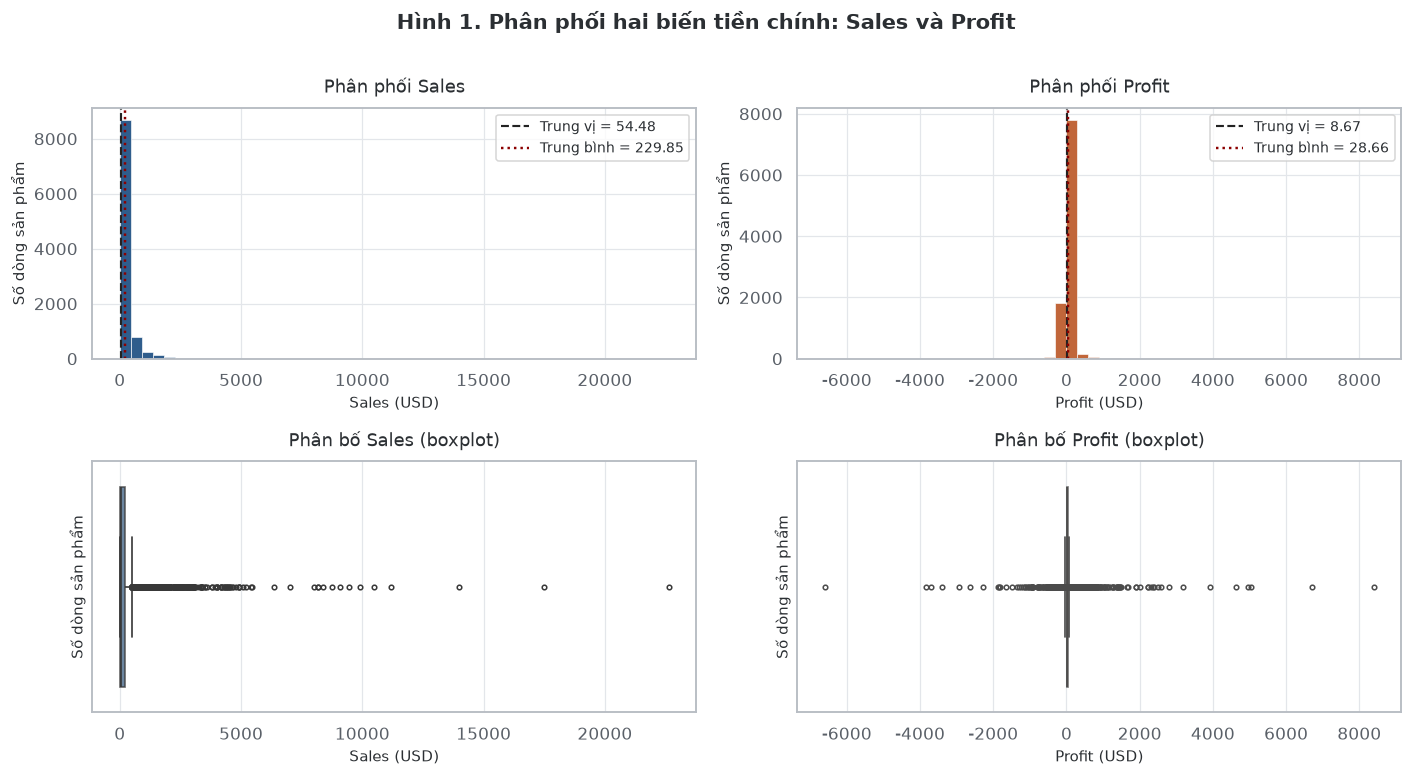

In [43]:
print("=== 5.4 Phân phối Sales và Profit (histogram + boxplot) ===")
print("Vì sao chọn loại biểu đồ này: histogram cho phép đọc HÌNH DÁNG phân phối (lệch, đỉnh, đuôi),")
print("còn boxplot cho phép so sánh vị trí trung vị, IQR và các điểm ngoại lại trong cùng một trục.")
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for ax, col, color in [(axes[0, 0], "Sales", PALETTE[0]), (axes[0, 1], "Profit", PALETTE[1])]:
    ax.hist(df[col], bins=50, color=color, edgecolor="white", linewidth=0.4)
    ax.set_title(f"Phân phối {col}", fontsize=12, pad=10)
    ax.set_xlabel(col + " (USD)", fontsize=10)
    ax.set_ylabel("Số dòng sản phẩm", fontsize=10)
    ax.axvline(df[col].median(), color="#222", linestyle="--", linewidth=1.4,
               label=f"Trung vị = {df[col].median():,.2f}")
    ax.axvline(df[col].mean(), color="#8B0000", linestyle=":", linewidth=1.6,
               label=f"Trung bình = {df[col].mean():,.2f}")
    ax.legend(fontsize=9, frameon=True, facecolor="white", edgecolor="#CCC")

for ax, col, color in [(axes[1, 0], "Sales", PALETTE[0]), (axes[1, 1], "Profit", PALETTE[1])]:
    sns.boxplot(data=df, x=col, color=color, ax=ax, fliersize=3,
                linewidth=1.1, boxprops={"alpha": 0.75})
    ax.set_title(f"Phân bố {col} (boxplot)", fontsize=12, pad=10)
    ax.set_xlabel(col + " (USD)", fontsize=10)
    ax.set_ylabel("Số dòng sản phẩm", fontsize=10)
    ax.set_yticks([])

fig.suptitle("Hình 1. Phân phối hai biến tiền chính: Sales và Profit",
             fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

=== 5.5 Phân phối Quantity và Discount ===
Vì sao chọn: Quantity là biến số nguyên rời rạc (nên dùng thanh đếm số nguyên),
Discount cũng rời rạc nhưng có 12 mức rời rạc → thanh ngang cho thấy tần suất từng mức rõ hơn.


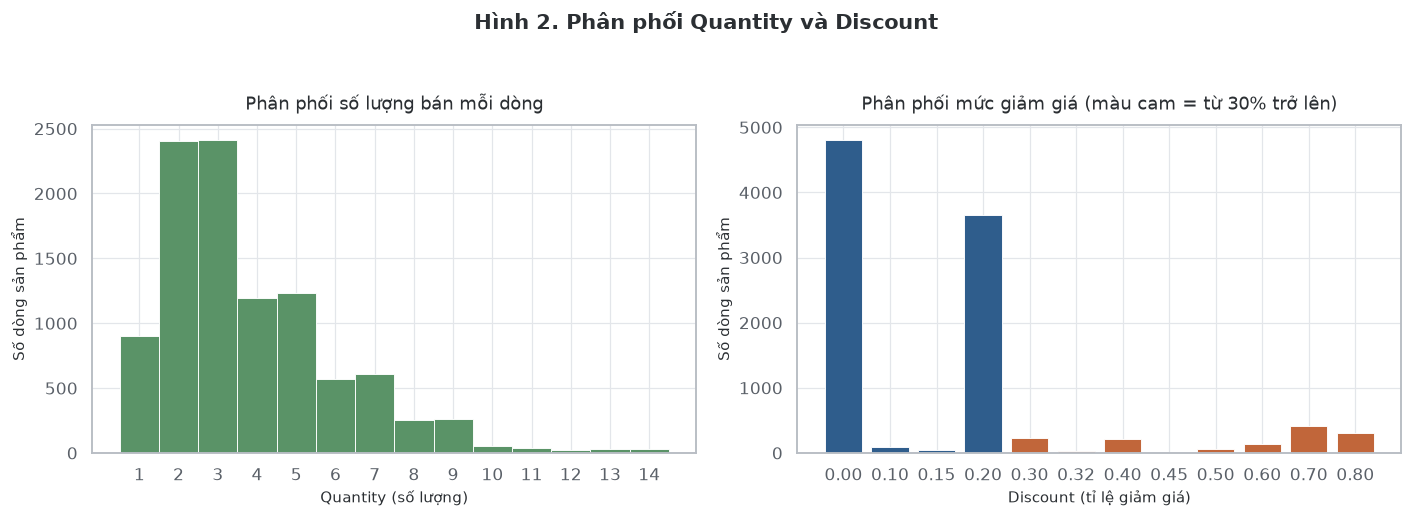

In [44]:
print("=== 5.5 Phân phối Quantity và Discount ===")
print("Vì sao chọn: Quantity là biến số nguyên rời rạc (nên dùng thanh đếm số nguyên),")
print("Discount cũng rời rạc nhưng có 12 mức rời rạc → thanh ngang cho thấy tần suất từng mức rõ hơn.")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df["Quantity"], bins=range(1, 16), color=PALETTE[2],
              edgecolor="white", linewidth=0.6, align="left")
axes[0].set_title("Phân phối số lượng bán mỗi dòng", fontsize=12, pad=10)
axes[0].set_xlabel("Quantity (số lượng)", fontsize=10)
axes[0].set_ylabel("Số dòng sản phẩm", fontsize=10)
axes[0].set_xticks(range(1, 15))

disc_counts = df["Discount"].value_counts().sort_index()
disc_colors = [PALETTE[1] if d >= 0.3 else PALETTE[0] for d in disc_counts.index]
axes[1].bar([f"{d:.2f}" for d in disc_counts.index], disc_counts.values,
             color=disc_colors, edgecolor="white", linewidth=0.6)
axes[1].set_title("Phân phối mức giảm giá (màu cam = từ 30% trở lên)", fontsize=12, pad=10)
axes[1].set_xlabel("Discount (tỉ lệ giảm giá)", fontsize=10)
axes[1].set_ylabel("Số dòng sản phẩm", fontsize=10)

fig.suptitle("Hình 2. Phân phối Quantity và Discount", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## 6. Group Comparison — D10

**Mục tiêu:** so sánh hiệu quả kinh doanh giữa các nhóm: **Category** (sản phẩm), **Region** (khu vực) và **Segment** (phân khúc khách hàng).

### Công thức quan trọng — Average Order Value

> **AOV = tổng `Sales` của nhóm ÷ số `Order ID` khác nhau trong nhóm**

Không được dùng `mean(Sales)` trên cấp dòng, vì mỗi đơn có số mặt hàng khác nhau (tối đa 14 dòng/đơn) → trung bình cấp dòng sẽ đánh giá thấp giá trị thực của một đơn.

Cùng với AOV, nhóm sẽ tính thêm:
- **Biên lợi nhuận (%)** = tổng `Profit` ÷ tổng `Sales` × 100
- **Lợi nhuận mỗi đơn** = tổng `Profit` ÷ số đơn
- **Số dòng lỗ** (dòng `Profit` âm) — để thấy rõ vấn đề nằm ở nhóm nào

In [45]:
# --- Hàm tổng hợp nhóm dùng chung cho cả D10 và D13 ---
def group_summary(df, by):
    # Tổng hợp nhóm. AOV = tổng Sales / số Order ID khác nhau (KHÔNG phải mean(Sales) cấp dòng).
    g = df.groupby(by).agg(
        sales=("Sales", "sum"),
        profit=("Profit", "sum"),
        quantity=("Quantity", "sum"),
        lines=("Row ID", "size"),
        orders=("Order ID", "nunique"),
    )
    g["AOV"] = (g["sales"] / g["orders"]).round(2)
    g["profit_per_order"] = (g["profit"] / g["orders"]).round(2)
    g["margin_pct"] = (g["profit"] / g["sales"] * 100).round(2)
    g["lines_per_order"] = (g["lines"] / g["orders"]).round(2)
    g["neg_lines"] = df.groupby(by).apply(
        lambda x: int((x["Profit"] < 0).sum()), include_groups=False)
    g["neg_pct_lines"] = (g["neg_lines"] / g["lines"] * 100).round(2)
    return g.sort_values("sales", ascending=False)


print("=== 6.1 A. Product Category ===")
cat_summary = group_summary(df, "Category")
print(cat_summary.to_string())

print("\n--- Kiểm chứng công thức AOV cho Technology (đối chiếu thủ công) ---")
tech = df[df["Category"] == "Technology"]
print(f"Tổng Sales      : {tech['Sales'].sum():,.4f}")
print(f"Số Order ID khác nhau: {tech['Order ID'].nunique():,}")
print(f"AOV (Sales/Orders): {tech['Sales'].sum() / tech['Order ID'].nunique():,.4f}")
print(f"mean(Sales) cấp dòng (SAI - không dùng): {tech['Sales'].mean():,.4f}")
print("=> Hai cách cho kết quả rất khác nhau, vì vậy AOV phải dùng công thức chia cho số đơn.")

=== 6.1 A. Product Category ===
                       sales       profit  quantity  lines  orders     AOV  profit_per_order  margin_pct  lines_per_order  neg_lines  neg_pct_lines
Category                                                                                                                                           
Technology       836154.0330  145454.9481      6939   1847    1544  541.55             94.21       17.40             1.20        271          14.67
Furniture        741718.4233   18463.3316      8026   2120    1764  420.48             10.47        2.49             1.20        713          33.63
Office Supplies  719047.0320  122490.8008     22906   6026    3742  192.16             32.73       17.04             1.61        886          14.70

--- Kiểm chứng công thức AOV cho Technology (đối chiếu thủ công) ---
Tổng Sales      : 836,154.0330
Số Order ID khác nhau: 1,544
AOV (Sales/Orders): 541.5505
mean(Sales) cấp dòng (SAI - không dùng): 452.7093
=> Hai cách cho kết

In [46]:
print("=== 6.2 A. Chi tiết Sub-Category (cấp sâu hơn) ===")
sub_summary = group_summary(df, "Sub-Category")
print(sub_summary[["sales", "profit", "orders", "AOV", "margin_pct", "neg_lines"]].to_string())

=== 6.2 A. Chi tiết Sub-Category (cấp sâu hơn) ===
                    sales      profit  orders      AOV  margin_pct  neg_lines
Sub-Category                                                                 
Phones        330007.0540  44515.7306     814   405.41       13.49        136
Chairs        328167.7310  26602.2251     576   569.74        8.11        234
Storage       223843.6080  21278.8264     777   288.09        9.51        161
Tables        206965.5320 -17725.4811     307   674.15       -8.56        203
Binders       203412.7330  30221.7633    1316   154.57       14.86        613
Machines      189238.6310   3384.7569     112  1689.63        1.79         44
Accessories   167380.3180  41936.6357     718   233.12       25.05         91
Copiers       149528.0300  55617.8249      68  2198.94       37.20          0
Bookcases     114879.9963  -3472.5560     224   512.86       -3.02        109
Appliances    107532.1610  18138.0054     451   238.43       16.87         67
Furnishings  

In [47]:
print("=== 6.3 B. Region ===")
reg_summary = group_summary(df, "Region")
print(reg_summary.to_string())

print("\n--- Kiểm chứng AOV cho từng vùng ---")
for r in reg_summary.index:
    sub = df[df["Region"] == r]
    aov_check = sub["Sales"].sum() / sub["Order ID"].nunique()
    print(f"{r:8s} tổng Sales {sub['Sales'].sum():>12,.2f} / "
          f"{sub['Order ID'].nunique():>5,} đơn = AOV {aov_check:>8,.2f}  "
          f"(khớp bảng: {abs(aov_check - reg_summary.loc[r, 'AOV']) < 0.01})")

=== 6.3 B. Region ===
               sales       profit  quantity  lines  orders     AOV  profit_per_order  margin_pct  lines_per_order  neg_lines  neg_pct_lines
Region                                                                                                                                     
West     725457.8245  108418.4489     12266   3203    1611  450.32             67.30       14.94             1.99        318           9.93
East     678499.8680   91534.8388     10616   2847    1401  484.30             65.34       13.49             2.03        552          19.39
Central  501239.8908   39706.3625      8780   2323    1175  426.59             33.79        7.92             1.98        741          31.90
South    391721.9050   46749.4303      6209   1620     822  476.55             56.87       11.93             1.97        259          15.99

--- Kiểm chứng AOV cho từng vùng ---
West     tổng Sales   725,457.82 / 1,611 đơn = AOV   450.32  (khớp bảng: True)
East     tổng Sales  

In [48]:
print("=== 6.4 C. Customer Segment ===")
seg_summary = group_summary(df, "Segment")
print(seg_summary.to_string())

print("\n--- Kiểm chứng AOV cho từng phân khúc ---")
for s in seg_summary.index:
    sub = df[df["Segment"] == s]
    aov_check = sub["Sales"].sum() / sub["Order ID"].nunique()
    print(f"{s:12s} tổng Sales {sub['Sales'].sum():>12,.2f} / "
          f"{sub['Order ID'].nunique():>5,} đơn = AOV {aov_check:>8,.2f}  "
          f"(khớp bảng: {abs(aov_check - seg_summary.loc[s, 'AOV']) < 0.01})")

=== 6.4 C. Customer Segment ===
                    sales       profit  quantity  lines  orders     AOV  profit_per_order  margin_pct  lines_per_order  neg_lines  neg_pct_lines
Segment                                                                                                                                         
Consumer     1.161401e+06  134119.2092     19521   5191    2586  449.11             51.86       11.55             2.01       1003          19.32
Corporate    7.061464e+05   91979.1340     11608   3020    1514  466.41             60.75       13.03             1.99        556          18.41
Home Office  4.293718e+05   60310.7373      6742   1782     909  472.36             66.35       14.05             1.96        311          17.45

--- Kiểm chứng AOV cho từng phân khúc ---
Consumer     tổng Sales 1,161,401.34 / 2,586 đơn = AOV   449.11  (khớp bảng: True)
Corporate    tổng Sales   706,146.37 / 1,514 đơn = AOV   466.41  (khớp bảng: True)
Home Office  tổng Sales   429,371.

In [49]:
print("=== 6.5 Bổ sung: Ship Mode (đặc điểm vận chuyển, thay cho cột chi phí vận chuyển) ===")
ship_summary = group_summary(df, "Ship Mode")
print(ship_summary[["sales", "profit", "orders", "AOV", "margin_pct", "neg_pct_lines"]].to_string())

df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
print("\n--- Thời gian giao hàng theo phương thức vận chuyển (ngày) ---")
print(df.groupby("Ship Mode")["ship_days"].agg(["count", "mean", "median", "min", "max"]).round(2).to_string())

=== 6.5 Bổ sung: Ship Mode (đặc điểm vận chuyển, thay cho cột chi phí vận chuyển) ===
                       sales       profit  orders     AOV  margin_pct  neg_pct_lines
Ship Mode                                                                           
Standard Class  1.357934e+06  164100.8463    2994  453.55       12.08          19.64
Second Class    4.591936e+05   57446.6354     964  476.34       12.51          15.78
First Class     3.514284e+05   48969.8399     787  446.54       13.93          19.05
Same Day        1.283631e+05   15891.7589     264  486.22       12.38          18.05

--- Thời gian giao hàng theo phương thức vận chuyển (ngày) ---
                count  mean  median  min  max
Ship Mode                                    
First Class      1538  2.18     2.0    1    4
Same Day          543  0.04     0.0    0    1
Second Class     1945  3.24     3.0    1    5
Standard Class   5967  5.01     5.0    3    7


**Nhận xét (D10):**

**A. Product Category**
* **Doanh thu:** `Technology` dẫn đầu (836.154 USD, 36,4% tổng), kế đến `Furniture` (741.718) và `Office Supplies` (719.047) — ba nhóm khá cân bằng về doanh thu.
* **Lợi nhuận:** khác biệt cực lớn. `Technology` 145.455 USD và `Office Supplies` 122.491 USD gần như bằng nhau, nhưng `Furniture` chỉ **18.463 USD** — thấp hơn `Technology` 7,9 lần dù doanh thu chỉ thấp hơn 11%.
* **Biên lợi nhuận:** `Furniture` chỉ **2,49%** so với 17,40% của `Technology` và 17,04% của `Office Supplies`. Đây là phát hiện quan trọng nhất của nhóm sản phẩm.
* **Số lỗ:** `Furniture` có 713 dòng lỗ trên 2.120 dòng (33,6%) — **gấp hơn 2,3 lần** tỉ lệ của hai nhóm kia (14,7% và 14,7%).
* **Số lượng bán:** `Office Supplies` bán nhiều hơn 3 lần `Technology` (22.906 vs 6.939) — mô hình bán lẻ đặc sản khác nhau: giá trị đơn lớn ít dòng vs giá trị nhỏ số lượng lớn.

**B. Region**
* **Doanh thu:** `West` cao nhất (725.458), `South` thấp nhất (391.722) — chênh 1,85 lần.
* **Lợi nhuận:** `West` cũng cao nhất (108.418). Nhưng `Central` chỉ 39.706 USD dù doanh thu đứng thứ ba — biên lợi nhuận thấp nhất (**7,92%**).
* **AOV:** `East` cao nhất (484,30), `Central` thấp nhất (426,59) — chênh lệch khá nhỏ (13,5%) so với chênh lệch doanh thu.
* **Số lỗ:** `Central` cao nhất (741 dòng, 31,9%) — tập trung vấn đề ở khu vực này.

**C. Customer Segment**
* **Doanh thu:** `Consumer` áp đảo (1.161.401, 50,6% tổng) — **1,6 lần** `Corporate` và 2,7 lần `Home Office`.
* **Lợi nhuận:** `Consumer` cũng cao nhất (134.119) nhưng **biên lợi nhuận thấp nhất (11,55%)**, thấp hơn `Corporate` (13,03%) và `Home Office` (14,05%).
* **AOV:** ba phân khúc gần như bằng nhau — 449,11 / 466,41 / 472,36 USD (chênh tối đa 5,2%). **Đây là điểm đáng chú ý:** phân khúc khác nhau rõ về **số lượng đơn** nhưng gần như không khác về **giá trị mỗi đơn**.
* **Số lỗ:** `Consumer` có 1.003 dòng lỗ (19,3%) — **tỉ lệ cao nhất** trong ba phân khúc (cao hơn `Corporate` 18,4% và `Home Office` 17,5%).

**Ship Mode**
* `Same Day` có AOV cao nhất (486,22) nhưng chỉ 264 đơn; `Standard Class` chiếm 59,7% đơn. Thời gian giao hàng trung vị 4 ngày, không vượt quá 7 ngày.

=== 6.6 Hình 3. Doanh thu và lợi nhuận theo nhóm sản phẩm ===
Vì sao chọn biểu đồ cột nhóm (grouped bar): cần so sánh HAI đại lượng (doanh thu và lợi nhuận)
trên CÙNG một trục số tiền cho ba nhóm sản phẩm. Bar cho phép so sánh độ dài trực tiếp,
dễ đọc hơn nhiều so với đường khi trục ngang là danh mục rời rạc.


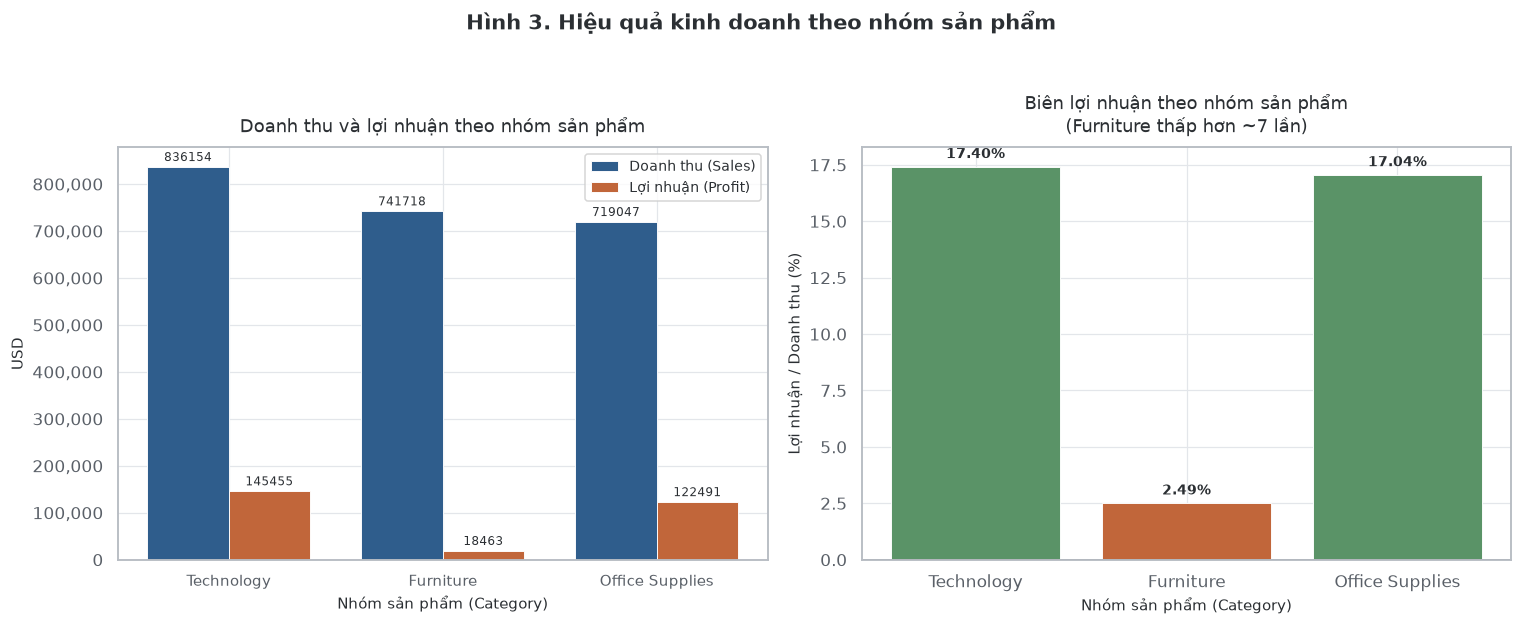

In [50]:
print("=== 6.6 Hình 3. Doanh thu và lợi nhuận theo nhóm sản phẩm ===")
print("Vì sao chọn biểu đồ cột nhóm (grouped bar): cần so sánh HAI đại lượng (doanh thu và lợi nhuận)")
print("trên CÙNG một trục số tiền cho ba nhóm sản phẩm. Bar cho phép so sánh độ dài trực tiếp,")
print("dễ đọc hơn nhiều so với đường khi trục ngang là danh mục rời rạc.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Sales & Profit by Category ---
ax = axes[0]
cats = cat_summary.index.tolist()
x = np.arange(len(cats))
w = 0.38
b1 = ax.bar(x - w/2, cat_summary["sales"], w, label="Doanh thu (Sales)",
            color=PALETTE[0], edgecolor="white", linewidth=0.6)
b2 = ax.bar(x + w/2, cat_summary["profit"], w, label="Lợi nhuận (Profit)",
            color=PALETTE[1], edgecolor="white", linewidth=0.6)
ax.set_title("Doanh thu và lợi nhuận theo nhóm sản phẩm", fontsize=12, pad=10)
ax.set_xlabel("Nhóm sản phẩm (Category)", fontsize=10)
ax.set_ylabel("USD", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(cats, fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=9, frameon=True, facecolor="white", edgecolor="#CCC")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2, rotation=0)

# --- Panel 2: Margin % by Category (the key finding) ---
ax2 = axes[1]
colors_margin = [PALETTE[1] if v < 5 else PALETTE[2] for v in cat_summary["margin_pct"]]
bars = ax2.bar(cats, cat_summary["margin_pct"], color=colors_margin,
                edgecolor="white", linewidth=0.6)
ax2.set_title("Biên lợi nhuận theo nhóm sản phẩm\n(Furniture thấp hơn ~7 lần)", fontsize=12, pad=10)
ax2.set_xlabel("Nhóm sản phẩm (Category)", fontsize=10)
ax2.set_ylabel("Lợi nhuận / Doanh thu (%)", fontsize=10)
ax2.axhline(0, color="#333", linewidth=1)
for b, v in zip(bars, cat_summary["margin_pct"]):
    ax2.text(b.get_x() + b.get_width()/2, v + 0.4, f"{v:.2f}%",
             ha="center", fontsize=9, fontweight="bold")

fig.suptitle("Hình 3. Hiệu quả kinh doanh theo nhóm sản phẩm", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

=== 6.7 Hình 4. Lợi nhuận theo khu vực và phân khúc ===
Vì sao chọn biểu đồ cột ngang (horizontal bar): tên nhóm ('Office Supplies', 'Home Office')
khá dài, nằm ngang sẽ dễ đọc hơn; thứ tự sắp xếp giảm dần giúp so sánh nhanh.


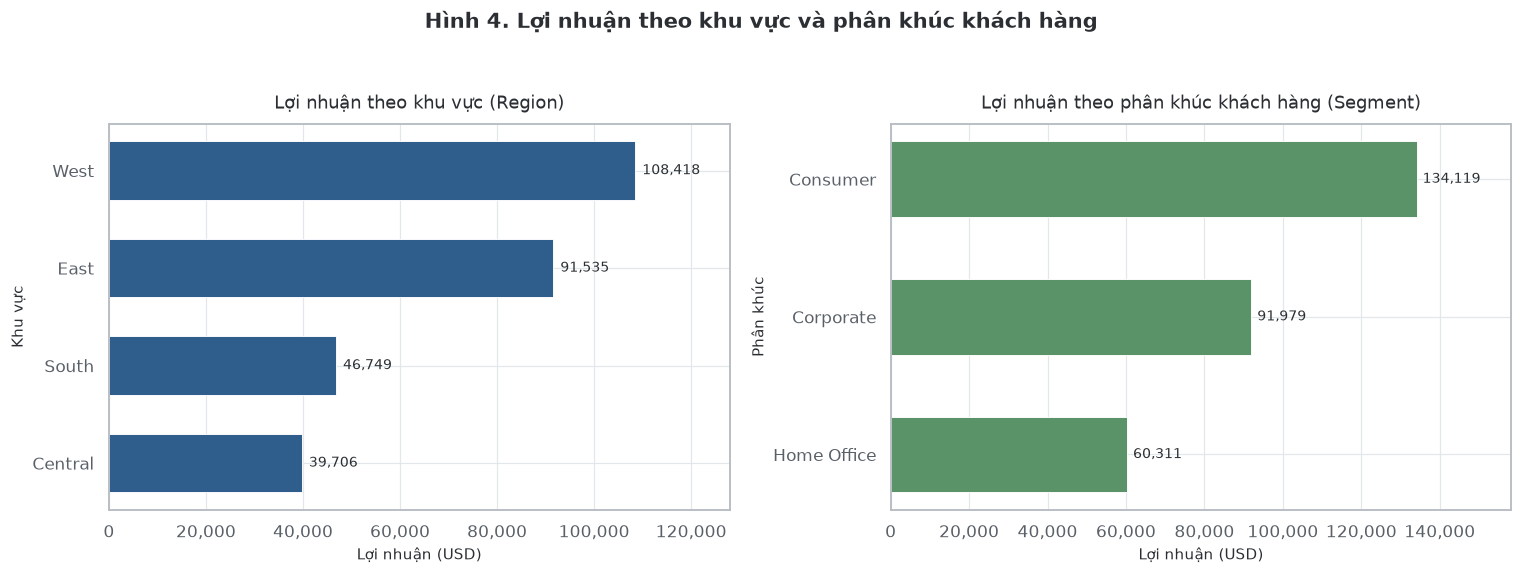

In [51]:
print("=== 6.7 Hình 4. Lợi nhuận theo khu vực và phân khúc ===")
print("Vì sao chọn biểu đồ cột ngang (horizontal bar): tên nhóm ('Office Supplies', 'Home Office')")
print("khá dài, nằm ngang sẽ dễ đọc hơn; thứ tự sắp xếp giảm dần giúp so sánh nhanh.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
r_sorted = reg_summary.sort_values("profit", ascending=True)
bars = ax.barh(r_sorted.index, r_sorted["profit"], color=PALETTE[0],
               edgecolor="white", linewidth=0.6, height=0.6)
ax.set_title("Lợi nhuận theo khu vực (Region)", fontsize=12, pad=10)
ax.set_xlabel("Lợi nhuận (USD)", fontsize=10)
ax.set_ylabel("Khu vực", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
for b, v in zip(bars, r_sorted["profit"]):
    ax.text(v + 1500, b.get_y() + b.get_height()/2, f"{v:,.0f}",
            va="center", fontsize=9)
ax.set_xlim(0, r_sorted["profit"].max() * 1.18)

ax = axes[1]
s_sorted = seg_summary.sort_values("profit", ascending=True)
bars = ax.barh(s_sorted.index, s_sorted["profit"], color=PALETTE[2],
               edgecolor="white", linewidth=0.6, height=0.55)
ax.set_title("Lợi nhuận theo phân khúc khách hàng (Segment)", fontsize=12, pad=10)
ax.set_xlabel("Lợi nhuận (USD)", fontsize=10)
ax.set_ylabel("Phân khúc", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
for b, v in zip(bars, s_sorted["profit"]):
    ax.text(v + 1500, b.get_y() + b.get_height()/2, f"{v:,.0f}",
            va="center", fontsize=9)
ax.set_xlim(0, s_sorted["profit"].max() * 1.18)

fig.suptitle("Hình 4. Lợi nhuận theo khu vực và phân khúc khách hàng",
             fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

=== 6.8 Hình 5. Giá trị đơn trung bình (AOV) theo khu vực và phân khúc ===
Vì sao chọn biểu đồ cột: AOV là một đại lượng đơn lẻ, so sánh giữa vài nhóm rời rạc
bằng độ dài cột là trực quan nhất. Đặt cạnh nhau để thấy ngay AOV gần như BẰNG NHAU
giữa các vùng và các phân khúc — khác với chênh lệch lớn về doanh thu tổng.


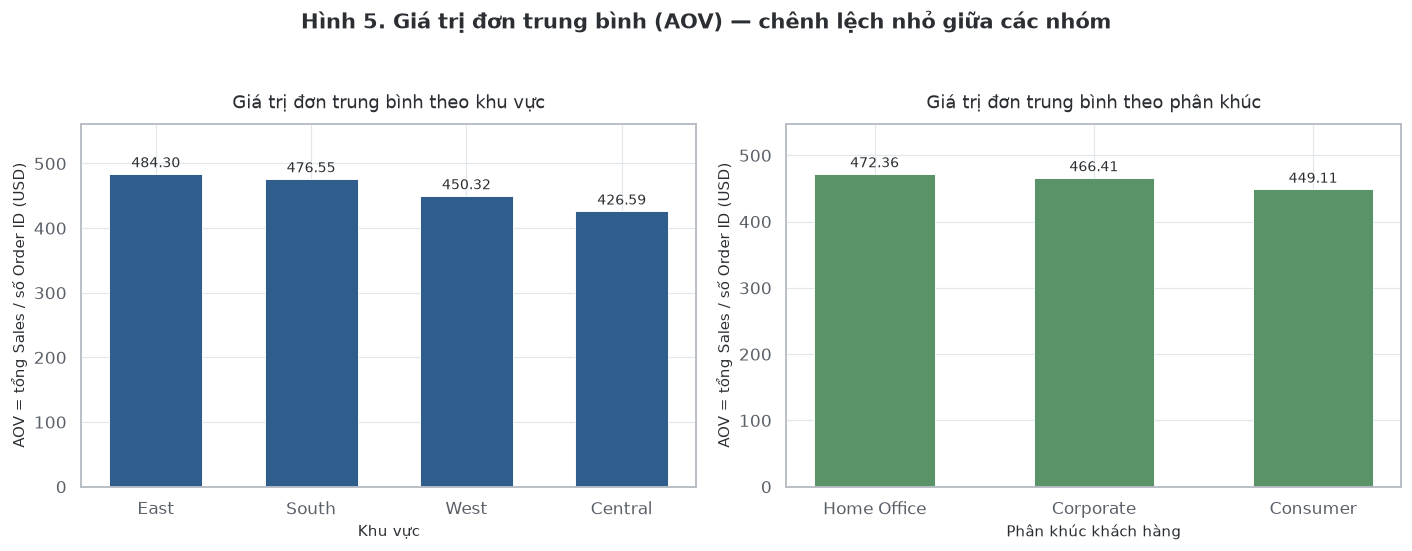

In [52]:
print("=== 6.8 Hình 5. Giá trị đơn trung bình (AOV) theo khu vực và phân khúc ===")
print("Vì sao chọn biểu đồ cột: AOV là một đại lượng đơn lẻ, so sánh giữa vài nhóm rời rạc")
print("bằng độ dài cột là trực quan nhất. Đặt cạnh nhau để thấy ngay AOV gần như BẰNG NHAU")
print("giữa các vùng và các phân khúc — khác với chênh lệch lớn về doanh thu tổng.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
r2 = reg_summary.sort_values("AOV", ascending=False)
bars = ax.bar(r2.index, r2["AOV"], color=[PALETTE[0]] * len(r2),
               edgecolor="white", linewidth=0.6, width=0.6)
ax.set_title("Giá trị đơn trung bình theo khu vực", fontsize=12, pad=10)
ax.set_xlabel("Khu vực", fontsize=10)
ax.set_ylabel("AOV = tổng Sales / số Order ID (USD)", fontsize=10)
ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, r2["AOV"].max() * 1.16)

ax = axes[1]
s2 = seg_summary.sort_values("AOV", ascending=False)
bars = ax.bar(s2.index, s2["AOV"], color=[PALETTE[2]] * len(s2),
               edgecolor="white", linewidth=0.6, width=0.55)
ax.set_title("Giá trị đơn trung bình theo phân khúc", fontsize=12, pad=10)
ax.set_xlabel("Phân khúc khách hàng", fontsize=10)
ax.set_ylabel("AOV = tổng Sales / số Order ID (USD)", fontsize=10)
ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, s2["AOV"].max() * 1.16)

fig.suptitle("Hình 5. Giá trị đơn trung bình (AOV) — chênh lệch nhỏ giữa các nhóm",
             fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## 7. Relationship Analysis — D11

**Mục tiêu:** đo lường mối quan hệ giữa ba cặp biến được yêu cầu:

1. `Discount` ↔ `Sales`
2. `Discount` ↔ `Profit`
3. `Sales` ↔ `Profit`

### Cách diễn giải hệ số tương quan

| Hệ số `r` (Pearson) | Mức độ | Diễn giải |
|---|---|---|
| \|r\| = 1 | Hoàn hảo | Tuyến tính tuyệt đối |
| 0,7 ≤ \|r\| < 1 | Mạnh | Mối liên hệ chặt chẽ |
| 0,4 ≤ \|r\| < 0,7 | Trung bình | Mối liên hệ đáng kể |
| 0,2 ≤ \|r\| < 0,4 | Yếu | Mối liên hệ nhẹ |
| \|r\| < 0,2 | Rất yếu | Không có mối liên hệ tuyến tính rõ |

> **Lưu ý bắt buộc:** hệ số tương quan chỉ đo **mối liên hệ tuyến tính đồng thời** trong dữ liệu quan sát. Nó **không** chứng minh quan hệ nhân quả. Phần D11 dưới đây luôn diễn giải bằng "có mối liên hệ", "đi kèm", không dùng "gây ra".

In [53]:
print("=== 7.1 Ma trận tương quan ===")
num_cols = ["Sales", "Profit", "Quantity", "Discount"]
corr = df[num_cols].corr(method="pearson")
print(corr.round(4).to_string())

print("\n=== 7.2 Hệ số tương quan cần quan tâm ===")
print(f"Discount ↔ Sales  : r = {df['Discount'].corr(df['Sales']):+.4f}")
print(f"Discount ↔ Profit : r = {df['Discount'].corr(df['Profit']):+.4f}")
print(f"Sales ↔ Profit    : r = {df['Sales'].corr(df['Profit']):+.4f}")
print(f"Quantity ↔ Sales  : r = {df['Quantity'].corr(df['Sales']):+.4f}")
print(f"Quantity ↔ Profit : r = {df['Quantity'].corr(df['Profit']):+.4f}")

print("\n=== 7.3 Kiểm tra độ mạnh quan hệ Sales–Profit bị ngoại lại chi phối không? ===")
print("Nếu bỏ các dòng doanh thu rất lớn, hệ số sẽ thay đổi thế nào?")
for cap in [None, 10000, 5000, 2000]:
    sub = df if cap is None else df[df["Sales"] <= cap]
    label = "toàn bộ" if cap is None else f"Sales <= {cap:,}"
    print(f"  {label:22s} n = {len(sub):>6,}   r(Sales, Profit) = "
          f"{sub['Sales'].corr(sub['Profit']):+.4f}")

print("\n=== 7.4 Tương quan Discount–Profit trên toàn bộ vs chỉ dòng không lỗ ===")
print(f"Toàn bộ            : r = {df['Discount'].corr(df['Profit']):+.4f}")
nn = df[df["Profit"] >= 0]
print(f"Chỉ dòng Profit>=0 : r = {nn['Discount'].corr(nn['Profit']):+.4f}  (n = {len(nn):,})")
print("-> Phần lớn tín hiệu đến từ chính các dòng lỗ (giảm giá sâu).")

print("\n=== 7.5 Tương quan với biến log (Sales phân phối lệch) ===")
print(f"log1p(Sales) ↔ Profit : r = {np.log1p(df['Sales']).corr(df['Profit']):+.4f}")
print("-> Thấp hơn r(Sales, Profit) gốc, vì vài dòng doanh thu khổng lồ đẩy tương quan lên.")

=== 7.1 Ma trận tương quan ===
           Sales  Profit  Quantity  Discount
Sales     1.0000  0.4791    0.2008   -0.0282
Profit    0.4791  1.0000    0.0662   -0.2195
Quantity  0.2008  0.0662    1.0000    0.0087
Discount -0.0282 -0.2195    0.0087    1.0000

=== 7.2 Hệ số tương quan cần quan tâm ===
Discount ↔ Sales  : r = -0.0282
Discount ↔ Profit : r = -0.2195
Sales ↔ Profit    : r = +0.4791
Quantity ↔ Sales  : r = +0.2008
Quantity ↔ Profit : r = +0.0662

=== 7.3 Kiểm tra độ mạnh quan hệ Sales–Profit bị ngoại lại chi phối không? ===
Nếu bỏ các dòng doanh thu rất lớn, hệ số sẽ thay đổi thế nào?
  toàn bộ                n =  9,993   r(Sales, Profit) = +0.4791
  Sales <= 10,000        n =  9,988   r(Sales, Profit) = +0.4014
  Sales <= 5,000         n =  9,974   r(Sales, Profit) = +0.3128
  Sales <= 2,000         n =  9,853   r(Sales, Profit) = +0.2612

=== 7.4 Tương quan Discount–Profit trên toàn bộ vs chỉ dòng không lỗ ===
Toàn bộ            : r = -0.2195
Chỉ dòng Profit>=0 : r = -0.0707

=== 7.6 Hình 6. Heatmap ma trận tương quan ===
Vì sao chọn heatmap: cho cái nhìn TOÀN CẢNH về các cặp biến cùng lúc trong một bảng màu,
dễ phát hiện cặp nào mạnh/yếu mà không cần đọc từng con số. Dùng `center=0` để 0 nằm giữa,
nên màu xanh (dương) và cam (âm) đối xứng nhau, tránh hiểu nhầm thang màu.


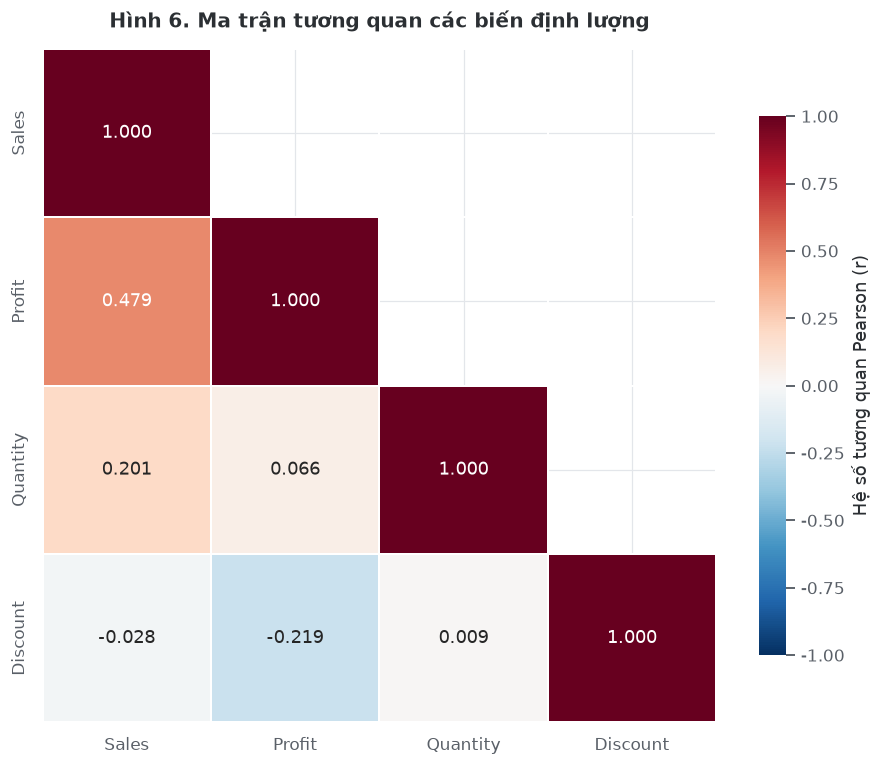

In [54]:
print("=== 7.6 Hình 6. Heatmap ma trận tương quan ===")
print("Vì sao chọn heatmap: cho cái nhìn TOÀN CẢNH về các cặp biến cùng lúc trong một bảng màu,")
print("dễ phát hiện cặp nào mạnh/yếu mà không cần đọc từng con số. Dùng `center=0` để 0 nằm giữa,")
print("nên màu xanh (dương) và cam (âm) đối xứng nhau, tránh hiểu nhầm thang màu.")
fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".3f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white",
            cbar_kws={"label": "Hệ số tương quan Pearson (r)", "shrink": 0.8})
ax.set_title("Hình 6. Ma trận tương quan các biến định lượng",
             fontsize=13, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

=== 7.7 Hình 7. Discount vs Profit (scatter) ===
Vì sao chọn scatter plot: thể hiện TỪNG CẶP QUAN SÁT thay vì một con số tổng hợp,
nên nhìn thấy được cả xu hướng tổng thể VÀ các điểm ngoại lại nổi bật.
Màu theo Category để thấy mối quan hệ có khác nhau giữa các nhóm sản phẩm hay không.


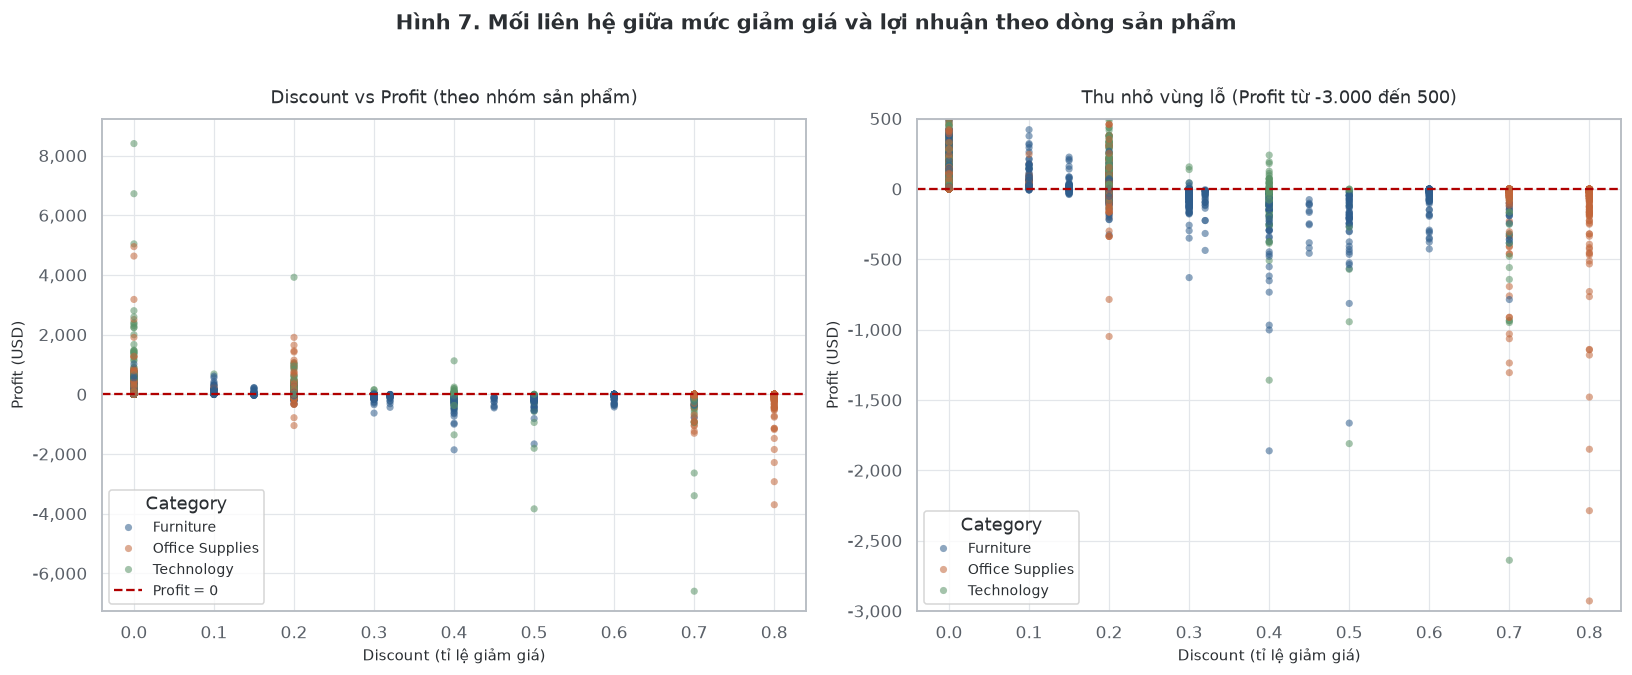

In [55]:
print("=== 7.7 Hình 7. Discount vs Profit (scatter) ===")
print("Vì sao chọn scatter plot: thể hiện TỪNG CẶP QUAN SÁT thay vì một con số tổng hợp,")
print("nên nhìn thấy được cả xu hướng tổng thể VÀ các điểm ngoại lại nổi bật.")
print("Màu theo Category để thấy mối quan hệ có khác nhau giữa các nhóm sản phẩm hay không.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Panel 1: Discount vs Profit, hue = Category ---
ax = axes[0]
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category",
                palette=PALETTE[:3], alpha=0.55, s=22, ax=ax,
                edgecolor="none", legend="full")
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.5, label="Profit = 0")
ax.set_title("Discount vs Profit (theo nhóm sản phẩm)", fontsize=12, pad=10)
ax.set_xlabel("Discount (tỉ lệ giảm giá)", fontsize=10)
ax.set_ylabel("Profit (USD)", fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=9, title="Category", frameon=True, facecolor="white",
          edgecolor="#CCC", loc="lower left")
ax.set_ylim(df["Profit"].min() * 1.1, df["Profit"].max() * 1.1)

# --- Panel 2: cùng dữ liệu nhưng zoom vùng lỗ ---
ax = axes[1]
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category",
                palette=PALETTE[:3], alpha=0.55, s=22, ax=ax,
                edgecolor="none", legend="full")
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.5)
ax.set_title("Thu nhỏ vùng lỗ (Profit từ -3.000 đến 500)", fontsize=12, pad=10)
ax.set_xlabel("Discount (tỉ lệ giảm giá)", fontsize=10)
ax.set_ylabel("Profit (USD)", fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(-3000, 500)
ax.legend(fontsize=9, title="Category", frameon=True, facecolor="white",
          edgecolor="#CCC", loc="lower left")

fig.suptitle("Hình 7. Mối liên hệ giữa mức giảm giá và lợi nhuận theo dòng sản phẩm",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

=== 7.8 Hình 8. Sales vs Profit + biểu đồ hỗ trợ mức giảm giá ===
Vì sao chọn: (trái) scatter Sales–Profit để xem mối liên hệ và phần dư;
(giữa) đường hồi quy theo từng nhóm sản phẩm; (phải) boxplot Profit theo mức giảm giá
để thấy rõ 'giảm giá càng cao, lợi nhuận càng âm' theo phân phối, không chỉ điểm trung bình.


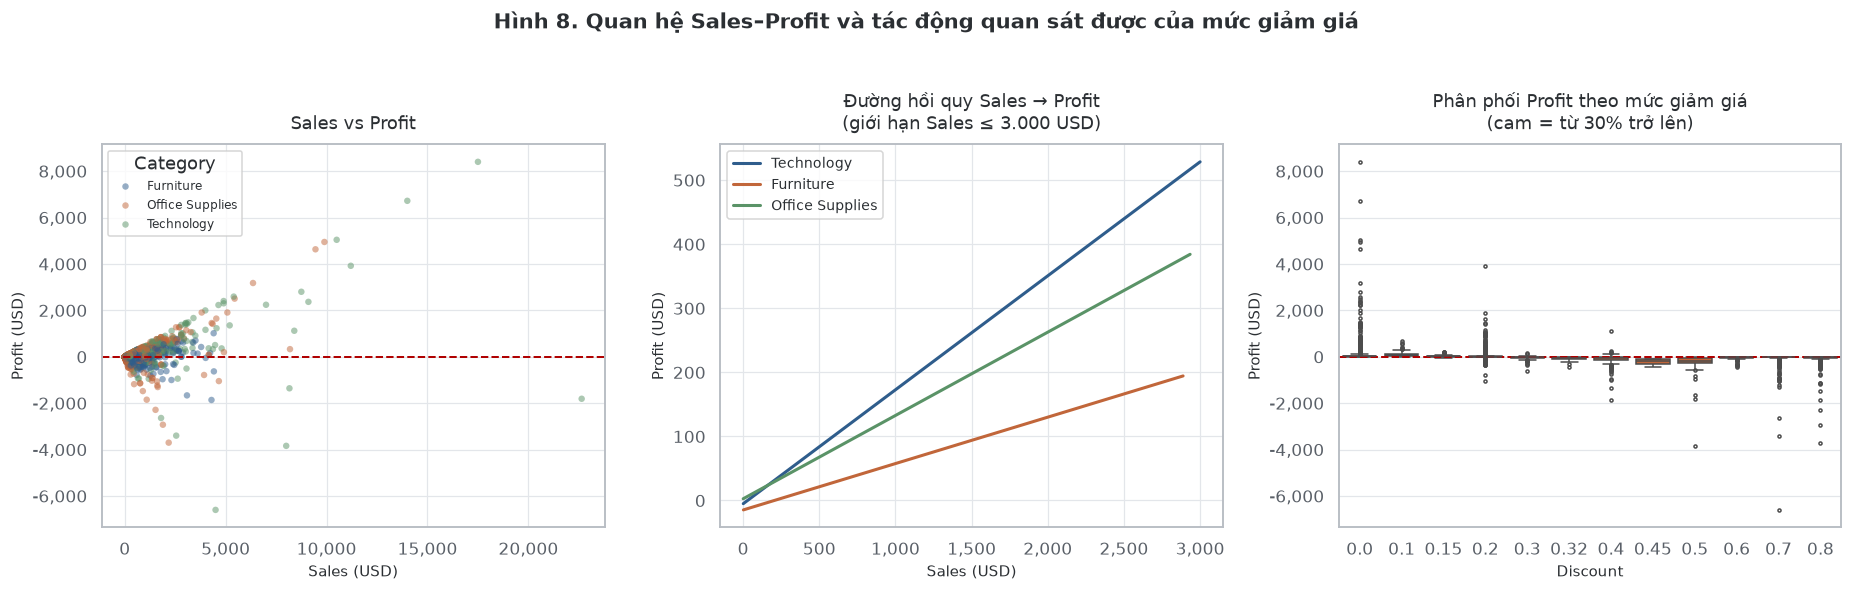

In [56]:
print("=== 7.8 Hình 8. Sales vs Profit + biểu đồ hỗ trợ mức giảm giá ===")
print("Vì sao chọn: (trái) scatter Sales–Profit để xem mối liên hệ và phần dư;")
print("(giữa) đường hồi quy theo từng nhóm sản phẩm; (phải) boxplot Profit theo mức giảm giá")
print("để thấy rõ 'giảm giá càng cao, lợi nhuận càng âm' theo phân phối, không chỉ điểm trung bình.")
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

ax = axes[0]
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category",
                palette=PALETTE[:3], alpha=0.5, s=18, ax=ax,
                edgecolor="none", legend="full")
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.3)
ax.set_title("Sales vs Profit", fontsize=12, pad=10)
ax.set_xlabel("Sales (USD)", fontsize=10)
ax.set_ylabel("Profit (USD)", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=8, title="Category", frameon=True, facecolor="white", edgecolor="#CCC")

ax = axes[1]
for i, cat in enumerate(cat_summary.index):
    sub = df[df["Category"] == cat]
    sub = sub[sub["Sales"] <= 3000]           # cắt đuôi để đường hồi quy đọc được
    z = np.polyfit(sub["Sales"], sub["Profit"], 1)
    xs = np.linspace(sub["Sales"].min(), sub["Sales"].max(), 100)
    ax.plot(xs, np.polyval(z, xs), color=PALETTE[i], linewidth=2, label=cat)
ax.set_title("Đường hồi quy Sales → Profit\n(giới hạn Sales ≤ 3.000 USD)", fontsize=12, pad=10)
ax.set_xlabel("Sales (USD)", fontsize=10)
ax.set_ylabel("Profit (USD)", fontsize=10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:0,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=9, frameon=True, facecolor="white", edgecolor="#CCC")

ax = axes[2]
disc_box = df.groupby("Discount")["Profit"].median().index
# Gán màu theo từng hộp thay vì truyền `palette` (seaborn >= 0.13 cảnh báo khi
# truyền palette mà không có `hue`): tô màu trực tiếp từng box sau khi vẽ.
disc_colors = [PALETTE[1] if d >= 0.3 else PALETTE[0] for d in disc_box]
sns.boxplot(data=df, x="Discount", y="Profit", order=disc_box,
            fliersize=2, linewidth=1.0, ax=ax)
for patch, color in zip(ax.patches, disc_colors):
    patch.set_facecolor(color)
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.3)
ax.set_title("Phân phối Profit theo mức giảm giá\n(cam = từ 30% trở lên)", fontsize=12, pad=10)
ax.set_xlabel("Discount", fontsize=10)
ax.set_ylabel("Profit (USD)", fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.suptitle("Hình 8. Quan hệ Sales–Profit và tác động quan sát được của mức giảm giá",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [57]:
print("=== 7.9 Bảng tổng hợp theo mức giảm giá (bằng chứng định lượng cho D13/Q4) ===")
disc_tbl = df.groupby("Discount").agg(
    lines=("Sales", "size"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
    neg_lines=("Profit", lambda s: int((s < 0).sum())),
    avg_sales=("Sales", "mean"),
    avg_profit=("Profit", "mean"),
).round(2)
disc_tbl["neg_pct"] = (disc_tbl["neg_lines"] / disc_tbl["lines"] * 100).round(1)
disc_tbl["margin_pct"] = (disc_tbl["profit"] / disc_tbl["sales"] * 100).round(2)
# Lưu ý: không tính tương quan bên trong từng mức giảm giá — `Discount` là hằng số
# trong mỗi nhóm nên hệ số tương quan luôn bằng 0 hoặc NaN, không mang thông tin.
print(disc_tbl.to_string())

=== 7.9 Bảng tổng hợp theo mức giảm giá (bằng chứng định lượng cho D13/Q4) ===
          lines       sales     profit  neg_lines  avg_sales  avg_profit  neg_pct  margin_pct
Discount                                                                                     
0.00       4798  1087908.47  320987.60          0     226.74       66.90      0.0       29.51
0.10         94    54369.35    9029.18          4     578.40       96.06      4.3       16.61
0.15         52    27558.52    1418.99         17     529.97       27.29     32.7        5.15
0.20       3657   764594.37   90337.31        502     209.08       24.70     13.7       11.82
0.30        226   102945.28  -10357.22        207     455.51      -45.83     91.6      -10.06
0.32         27    14493.46   -2391.14         27     536.79      -88.56    100.0      -16.50
0.40        206   116417.78  -23057.05        180     565.13     -111.93     87.4      -19.81
0.45         11     5484.97   -2493.11         11     498.63     -226.65   

**Nhận xét (D11):**

**`Discount` ↔ `Sales`: r = −0,028 — gần như không có mối liên hệ tuyến tính.**
Không có bằng chứng rằng mức giảm giá thường đi kèm với doanh thu lớn hơn hoặc nhỏ hơn ở cấp dòng. Lý do có thể: giảm giá được áp dụng theo **danh mục sản phẩm** chứ không theo giá trị đơn, nên trong một mức giảm giá có cả dòng doanh thu thấp lẫn cao.

**`Discount` ↔ `Profit`: r = −0,219 — mối liên hệ yếu về chiều âm.**
Chi tiết quan trọng:
* Biểu đồ theo mức giảm giá cho thấy mối quan hệ **không đơn điệu mà phân tầng theo ngưỡng**: mức 0,0 có biên lợi nhuận **29,51%**, mức 0,2 còn **11,82%**, nhưng từ **0,30 trở lên biên lợi nhuận âm** (−10,06% đến −180,03%).
* Tại **6 mức** 0,32 / 0,45 / 0,50 / 0,60 / 0,70 / 0,80 — **100% số dòng đều lỗ**. Mức 0,30 là 91,6% và mức 0,40 là 87,4%. Nói cách khác: **mọi mức giảm giá ≥ 0,30 đều lỗ trên 87% số dòng**.
* Đáng chú ý: tổng doanh thu ở mức giảm giá cao **vẫn lớn** (mức 0,5: 58.918 USD trên 66 dòng) — cho thấy doanh thu không mất đi, mà **chuyển thành doanh thu không sinh lời**.
* R² của hệ số −0,219 chỉ là 4,8% → mức giảm giá **chỉ giải thích ~5% biến động** của lợi nhuận ở cấp dòng. Không thể dùng mức giảm giá để dự báo lợi nhuận.

**`Sales` ↔ `Profit`: r = +0,479 — mối liên hệ trung bình theo chiều dương.**
Nhưng con số này **bị chi phối bởi ngoại lại**: khi giới hạn `Sales ≤ 5.000`, r giảm từ 0,479 xuống **0,313**; với `log1p(Sales)` r chỉ còn **0,204**. Nghĩa là phần lớn mối liên hệ đến từ vài đơn giá trị rất lớn (máy photocopy Canon: 17.499,95 USD lãi 8.399,98; thiết bị hội nghị Cisco: 22.638,48 USD lỗ 1.811,08).

**Ngoại lại đáng chú ý:**
* Lỗ lớn nhất: `Technology/Machines` giảm giá 70% trên 4.499,99 USD → lỗ **−6.599,98** (một dòng lỗ bằng cả 761 lần giá trị trung vị lợi nhuận của một dòng — 8,67 USD).
* Nghịch lý giảm giá: `Technology/Copiers` bán **không giảm giá** với giá 17.499,95 USD → lãi 8.399,98 (lợi nhuận cao nhất). Cho thấy giảm giá không phải con đường duy nhất tới doanh thu lớn.
* `Quantity` không liên hệ đáng kể với lợi nhuận (r = 0,066).

> **Giới hạn diễn giải:** các hệ số trên là mối liên hệ **quan sát** trên dữ liệu lịch sử. Chúng **không** chứng minh rằng tăng mức giảm giá **làm** giảm lợi nhuận. Các yếu tố không có trong dataset (chi phí vận chuyển, giá vốn, tồn kho, chương trình khuyến mãi khác) có thể vừa gây ra giảm giá vừa ảnh hưởng đến lợi nhuận.

## 8. Time Series Analysis — D12

**Mục tiêu:** phân tích diễn biến doanh thu, lợi nhuận và số đơn hàng theo tháng và theo năm trong giai đoạn 01/2014 – 12/2017.

> **Quy tắc quan trọng — số đơn hàng:** mọi phép đếm đơn hàng đều dùng `nunique("Order ID")`. Số dòng dữ liệu **không** được dùng để đại diện cho số đơn, vì một đơn có thể có tới 14 dòng sản phẩm.

Dữ liệu có **đủ 48/48 tháng** trong giai đoạn 2014–2017 → không có tháng mất dữ liệu, nên có thể so sánh trực tiếp cùng tháng giữa các năm.

In [58]:
# --- Gom nhóm theo tháng ---
df["ym"] = df["Order Date"].dt.to_period("M")
df["year"] = df["Order Date"].dt.year
df["month_num"] = df["Order Date"].dt.month
df["quarter"] = df["Order Date"].dt.to_period("Q")

monthly = df.groupby("ym").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
    orders=("Order ID", "nunique"),      # SỐ ĐƠN = nunique, KHÔNG phải count dòng
    lines=("Row ID", "size"),             # số dòng sản phẩm (tham chiếu)
).round(2)
monthly["AOV"] = (monthly["sales"] / monthly["orders"]).round(2)
monthly["margin_pct"] = (monthly["profit"] / monthly["sales"] * 100).round(2)
monthly["avg_lines_per_order"] = (monthly["lines"] / monthly["orders"]).round(2)

print("=== 8.1 Bảng theo tháng (48 tháng) ===")
print(monthly.to_string())

print("\n=== 8.2 Kiểm chứng: số đơn dùng nunique, không phải số dòng ===")
print(f"Tổng số đơn (nunique Order ID) : {df['Order ID'].nunique():,}")
print(f"Tổng số dòng sản phẩm          : {len(df):,}")
print(f"Tổng số dòng trong bảng monthly: {monthly['lines'].sum():,}")
print(f"Tổng số đơn trong bảng monthly : {monthly['orders'].sum():,}")
print(f"Kiểm tra: {monthly['orders'].sum():,} == {df['Order ID'].nunique():,} -> "
      f"{'KHỚP' if monthly['orders'].sum() == df['Order ID'].nunique() else 'SAI'}")
print(f"Trung bình số mặt hàng mỗi đơn: {len(df) / df['Order ID'].nunique():.2f}")
print("=> Nếu dùng số dòng thay cho số đơn, số 'đơn' sẽ bị thổi phồng ~100%.")

=== 8.1 Bảng theo tháng (48 tháng) ===
             sales    profit  orders  lines     AOV  margin_pct  avg_lines_per_order
ym                                                                                  
2014-01   14236.90   2450.19      32     79  444.90       17.21                 2.47
2014-02    4519.89    862.31      28     46  161.42       19.08                 1.64
2014-03   55691.01    498.73      71    157  784.38        0.90                 2.21
2014-04   28013.97   3500.89      66    134  424.45       12.50                 2.03
2014-05   23648.29   2738.71      69    122  342.73       11.58                 1.77
2014-06   34595.13   4976.52      66    135  524.17       14.39                 2.05
2014-07   33946.39   -841.48      65    143  522.25       -2.48                 2.20
2014-08   27909.47   5318.10      72    153  387.63       19.05                 2.12
2014-09   81777.35   8328.10     130    268  629.06       10.18                 2.06
2014-10   31453.39   3448.

In [59]:
print("=== 8.3 So sánh theo năm ===")
yearly = df.groupby("year").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
    orders=("Order ID", "nunique"),
    lines=("Row ID", "size"),
).round(2)
yearly["AOV"] = (yearly["sales"] / yearly["orders"]).round(2)
yearly["margin_pct"] = (yearly["profit"] / yearly["sales"] * 100).round(2)
yearly["yoy_sales_pct"] = (yearly["sales"].pct_change() * 100).round(2)
yearly["yoy_profit_pct"] = (yearly["profit"].pct_change() * 100).round(2)
yearly["yoy_orders_pct"] = (yearly["orders"].pct_change() * 100).round(2)
yearly["neg_lines"] = df.groupby("year").apply(
    lambda x: int((x["Profit"] < 0).sum()), include_groups=False)
print(yearly.to_string())

print("\n--- Tăng trưởng cả giai đoạn 2014 → 2017 ---")
s_growth = (yearly.loc[2017, "sales"] / yearly.loc[2014, "sales"] - 1) * 100
p_growth = (yearly.loc[2017, "profit"] / yearly.loc[2014, "profit"] - 1) * 100
o_growth = (yearly.loc[2017, "orders"] / yearly.loc[2014, "orders"] - 1) * 100
print(f"Doanh thu : {s_growth:+.1f}%")
print(f"Lợi nhuận : {p_growth:+.1f}%")
print(f"Số đơn    : {o_growth:+.1f}%")
print(f"AOV       : {yearly.loc[2014,'AOV']:.2f} -> {yearly.loc[2017,'AOV']:.2f} "
      f"({(yearly.loc[2017,'AOV']/yearly.loc[2014,'AOV']-1)*100:+.1f}%)")

=== 8.3 So sánh theo năm ===
          sales    profit  orders  lines     AOV  margin_pct  yoy_sales_pct  yoy_profit_pct  yoy_orders_pct  neg_lines
year                                                                                                                  
2014  483966.13  49556.03     969   1992  499.45       10.24            NaN             NaN             NaN        376
2015  470532.51  61618.60    1038   2102  453.31       13.10          -2.78           24.34            7.12        397
2016  609205.60  81795.17    1315   2587  463.27       13.43          29.47           32.74           26.69        477
2017  733215.26  93439.27    1687   3312  434.63       12.74          20.36           14.24           28.29        620

--- Tăng trưởng cả giai đoạn 2014 → 2017 ---
Doanh thu : +51.5%
Lợi nhuận : +88.6%
Số đơn    : +74.1%
AOV       : 499.45 -> 434.63 (-13.0%)


In [60]:
print("=== 8.4 Mùa vụ: so sánh cùng tháng giữa các năm ===")
pivot_sales = df.pivot_table(index="month_num", columns="year",
                              values="Sales", aggfunc="sum").round(0)
pivot_orders = df.pivot_table(index="month_num", columns="year",
                               values="Order ID", aggfunc="nunique")
print("--- Doanh thu theo tháng (tháng x năm) ---")
print(pivot_sales.to_string())
print("\n--- Số đơn theo tháng (tháng x năm) ---")
print(pivot_orders.to_string())

season = df.groupby("month_num").agg(
    sales=("Sales", "sum"), profit=("Profit", "sum"),
    orders=("Order ID", "nunique"), lines=("Row ID", "size")).round(2)
season["avg_monthly_sales"] = (season["sales"] / 4).round(2)
season["avg_monthly_profit"] = (season["profit"] / 4).round(2)
season["avg_monthly_orders"] = (season["orders"] / 4).round(2)
season["share_sales_pct"] = (season["sales"] / df["Sales"].sum() * 100).round(2)
print("\n--- Trung bình mỗi tháng trong 4 năm ---")
print(season.to_string())

print(f"\nDoanh thu tháng 11-12 chiếm: {df[df['month_num'].isin([11,12])]['Sales'].sum()/df['Sales'].sum()*100:.1f}% tổng")
print(f"Tháng thấp nhất: {season['avg_monthly_sales'].idxmin()} "
      f"({season['avg_monthly_sales'].min():,.2f} USD/tháng)")
print(f"Tháng cao nhất : {season['avg_monthly_sales'].idxmax()} "
      f"({season['avg_monthly_sales'].max():,.2f} USD/tháng)")
print(f"Tỉ lệ max/min: {season['avg_monthly_sales'].max()/season['avg_monthly_sales'].min():.1f} lần")

=== 8.4 Mùa vụ: so sánh cùng tháng giữa các năm ===
--- Doanh thu theo tháng (tháng x năm) ---
year          2014     2015     2016      2017
month_num                                     
1          14237.0  18174.0  18542.0   43971.0
2           4520.0  11951.0  22979.0   20301.0
3          55691.0  38726.0  51716.0   58872.0
4          28014.0  34195.0  38750.0   36522.0
5          23648.0  30132.0  56988.0   44261.0
6          34595.0  24797.0  40345.0   52982.0
7          33946.0  28765.0  39262.0   45264.0
8          27909.0  36898.0  31115.0   63121.0
9          81777.0  64596.0  73410.0   87867.0
10         31453.0  31405.0  59688.0   77777.0
11         78629.0  75973.0  79412.0  118448.0
12         69546.0  74920.0  96999.0   83829.0

--- Số đơn theo tháng (tháng x năm) ---
year       2014  2015  2016  2017
month_num                        
1            32    29    48    69
2            28    36    45    53
3            71    79    86   118
4            66    72    89   116
5 

In [61]:
print("=== 8.5 Theo quý ===")
quarterly = df.groupby("quarter").agg(
    sales=("Sales", "sum"), profit=("Profit", "sum"),
    orders=("Order ID", "nunique")).round(2)
quarterly["margin_pct"] = (quarterly["profit"] / quarterly["sales"] * 100).round(2)
print(quarterly.to_string())

print("\n--- Tổng hợp theo quý (mọi năm gộp lại) ---")
q_sum = df.groupby(df["Order Date"].dt.quarter).agg(
    sales=("Sales", "sum"), profit=("Profit", "sum"),
    orders=("Order ID", "nunique")).round(2)
q_sum["share_sales_pct"] = (q_sum["sales"] / df["Sales"].sum() * 100).round(2)
q_sum["avg_quarterly_sales"] = (q_sum["sales"] / 4).round(2)
print(q_sum.to_string())
print(f"\nQ4 chiếm {q_sum.loc[4,'share_sales_pct']}% doanh thu; Q1 chỉ {q_sum.loc[1,'share_sales_pct']}%")

=== 8.5 Theo quý ===


             sales    profit  orders  margin_pct
quarter                                         
2014Q1    74447.80   3811.23     131        5.12
2014Q2    86257.39  11216.13     201       13.00
2014Q3   143633.21  12804.72     267        8.91
2014Q4   179627.73  21723.95     370       12.09
2015Q1    68851.74   9264.94     144       13.46
2015Q2    89124.19  12190.92     214       13.68
2015Q3   130259.58  16853.62     274       12.94
2015Q4   182297.01  23309.12     406       12.79
2016Q1    93237.18  11441.37     179       12.27
2016Q2   136082.30  16390.34     294       12.04
2016Q3   143787.36  15823.60     378       11.00
2016Q4   236098.75  38139.86     464       16.15
2017Q1   123144.86  23506.20     240       19.09
2017Q2   133764.37  15499.21     367       11.59
2017Q3   196251.96  26985.13     448       13.75
2017Q4   280054.07  27448.73     632        9.80

--- Tổng hợp theo quý (mọi năm gộp lại) ---
                sales     profit  orders  share_sales_pct  avg_quarterly_

=== 8.6 Hình 9. Xu hướng doanh thu, lợi nhuận và số đơn theo tháng ===
Vì sao chọn biểu đồ đường: dữ liệu là chuỗi thời gian THỦY THỦ 48 tháng liên tục,
nên đường thể hiện xu hướng và chu kỳ mùa vụ rõ ràng nhất (bar sẽ che mất độ liên tục).
Dùng 2 trục y (twinx) vì doanh thu (nghìn USD) và số đơn có thang đo khác nhau.


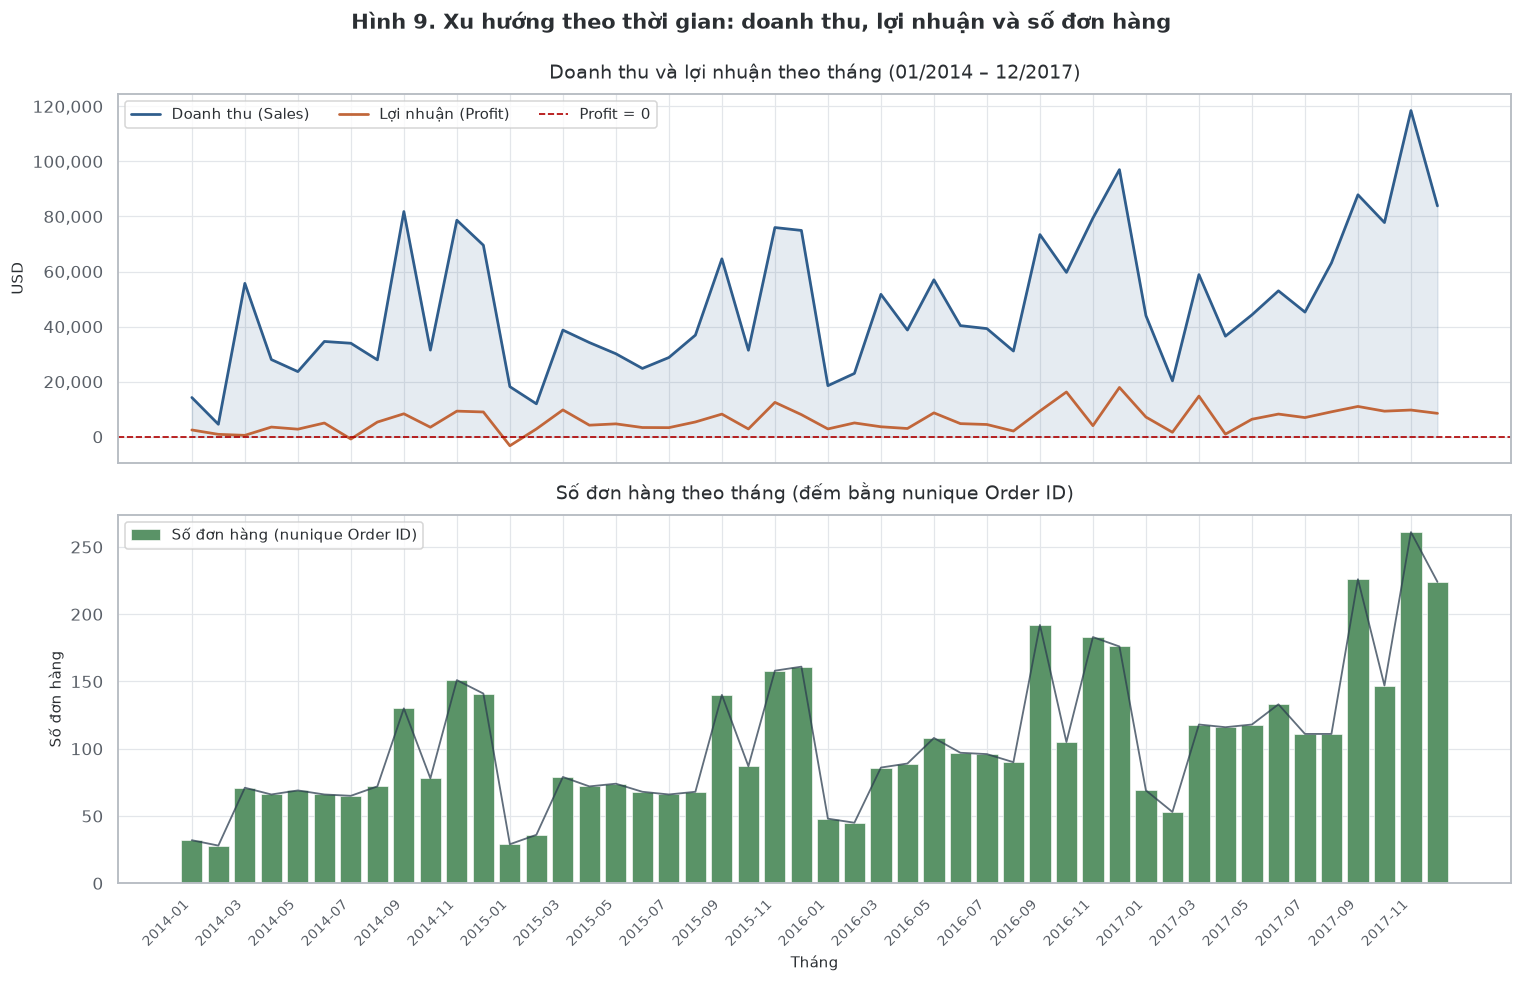

In [62]:
print("=== 8.6 Hình 9. Xu hướng doanh thu, lợi nhuận và số đơn theo tháng ===")
print("Vì sao chọn biểu đồ đường: dữ liệu là chuỗi thời gian THỦY THỦ 48 tháng liên tục,")
print("nên đường thể hiện xu hướng và chu kỳ mùa vụ rõ ràng nhất (bar sẽ che mất độ liên tục).")
print("Dùng 2 trục y (twinx) vì doanh thu (nghìn USD) và số đơn có thang đo khác nhau.")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

x = np.arange(len(monthly))
labels = [str(p) for p in monthly.index]

# --- Panel 1: Sales & Profit ---
ax = axes[0]
ax.plot(x, monthly["sales"], color=PALETTE[0], linewidth=1.8, label="Doanh thu (Sales)")
ax.fill_between(x, monthly["sales"], color=PALETTE[0], alpha=0.12)
ax.plot(x, monthly["profit"], color=PALETTE[1], linewidth=1.8, label="Lợi nhuận (Profit)")
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.1, label="Profit = 0")
ax.set_title("Doanh thu và lợi nhuận theo tháng (01/2014 – 12/2017)",
             fontsize=12.5, pad=10)
ax.set_ylabel("USD", fontsize=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=9.5, frameon=True, facecolor="white", edgecolor="#CCC", ncol=3)

# --- Panel 2: Orders (nunique) ---
ax2 = axes[1]
ax2.bar(x, monthly["orders"], color=PALETTE[2], edgecolor="white", linewidth=0.4,
        label="Số đơn hàng (nunique Order ID)")
ax2.plot(x, monthly["orders"], color="#2C3E50", linewidth=1.2, alpha=0.75)
ax2.set_title("Số đơn hàng theo tháng (đếm bằng nunique Order ID)",
              fontsize=12.5, pad=10)
ax2.set_xlabel("Tháng", fontsize=10)
ax2.set_ylabel("Số đơn hàng", fontsize=10)
ax2.set_xticks(x[::2])
ax2.set_xticklabels(labels[::2], rotation=45, ha="right", fontsize=9)
ax2.legend(fontsize=9.5, frameon=True, facecolor="white", edgecolor="#CCC")

fig.suptitle("Hình 9. Xu hướng theo thời gian: doanh thu, lợi nhuận và số đơn hàng",
             fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

=== 8.7 Hình 10. So sánh theo năm và mùa vụ theo tháng ===
Vì sao chọn: (trái) cột nhóm theo năm cho thấy mức tăng trưởng của cả 3 đại lượng;
(giữa) đường theo tháng để thấy hình dạng mùa vụ lặp lại qua các năm;
(phải) đường trung bình theo tháng để tóm tắt 'tháng nào mạnh, tháng nào yếu'.


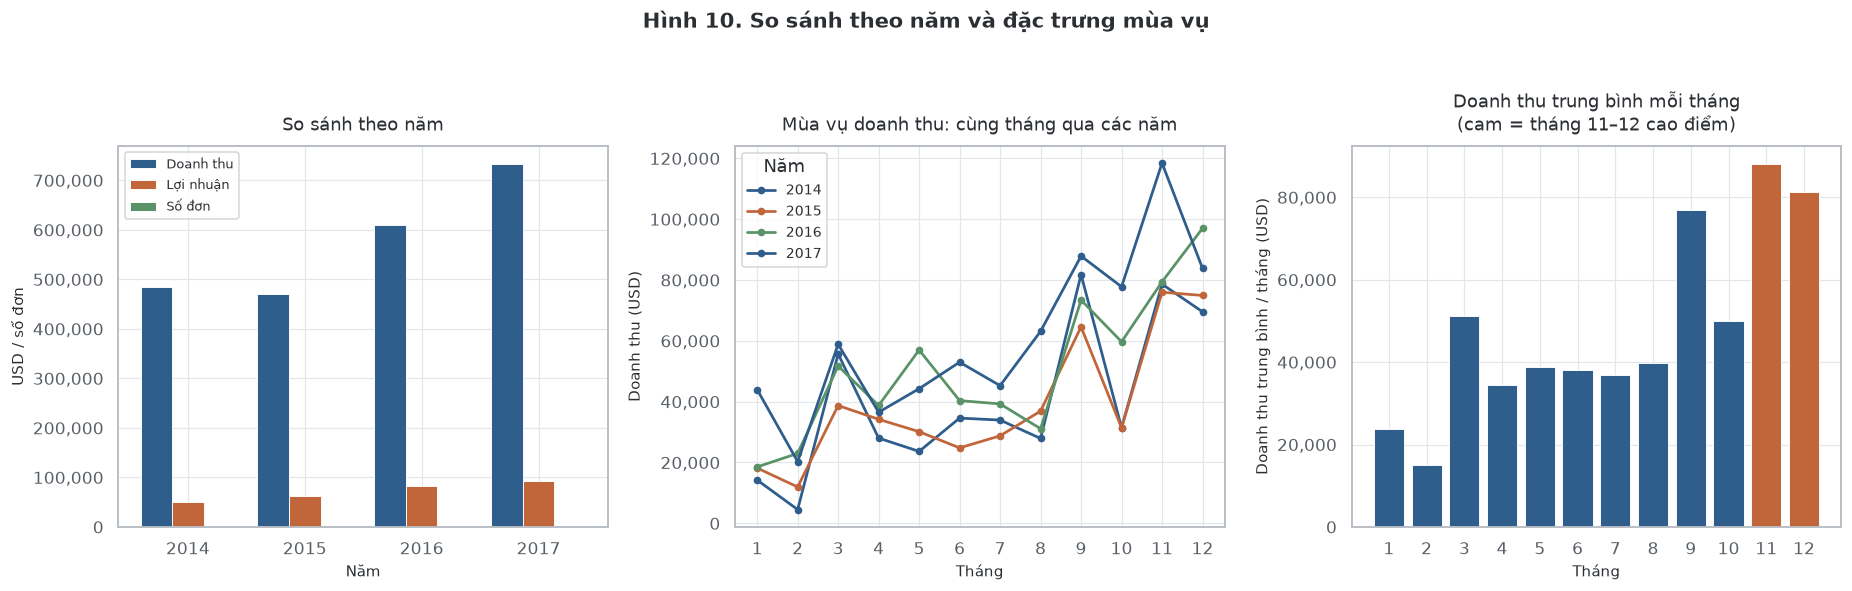

In [63]:
print("=== 8.7 Hình 10. So sánh theo năm và mùa vụ theo tháng ===")
print("Vì sao chọn: (trái) cột nhóm theo năm cho thấy mức tăng trưởng của cả 3 đại lượng;")
print("(giữa) đường theo tháng để thấy hình dạng mùa vụ lặp lại qua các năm;")
print("(phải) đường trung bình theo tháng để tóm tắt 'tháng nào mạnh, tháng nào yếu'.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# --- Panel 1: yearly grouped bar ---
ax = axes[0]
yrs = yearly.index.tolist()
x = np.arange(len(yrs))
w = 0.27
b1 = ax.bar(x - w, yearly["sales"], w, label="Doanh thu", color=PALETTE[0],
            edgecolor="white", linewidth=0.6)
b2 = ax.bar(x, yearly["profit"], w, label="Lợi nhuận", color=PALETTE[1],
            edgecolor="white", linewidth=0.6)
b3 = ax.bar(x + w, yearly["orders"], w, label="Số đơn", color=PALETTE[2],
            edgecolor="white", linewidth=0.6)
ax.set_title("So sánh theo năm", fontsize=12, pad=10)
ax.set_xlabel("Năm", fontsize=10)
ax.set_ylabel("USD / số đơn", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(yrs)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=8.5, frameon=True, facecolor="white", edgecolor="#CCC")

# --- Panel 2: monthly sales by year (seasonality lines) ---
ax = axes[1]
for i, yr in enumerate(sorted(df["year"].unique())):
    s = df[df["year"] == yr].groupby("month_num")["Sales"].sum()
    ax.plot(s.index, s.values, marker="o", markersize=4, linewidth=1.8,
            color=PALETTE[i % 3], label=str(yr))
ax.set_title("Mùa vụ doanh thu: cùng tháng qua các năm", fontsize=12, pad=10)
ax.set_xlabel("Tháng", fontsize=10)
ax.set_ylabel("Doanh thu (USD)", fontsize=10)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=9, frameon=True, facecolor="white", edgecolor="#CCC", title="Năm")

# --- Panel 3: average monthly profile ---
ax = axes[2]
ax.bar(season.index, season["avg_monthly_sales"],
       color=[PALETTE[1] if m in (11, 12) else PALETTE[0] for m in season.index],
       edgecolor="white", linewidth=0.6)
ax.set_title("Doanh thu trung bình mỗi tháng\n(cam = tháng 11–12 cao điểm)", fontsize=12, pad=10)
ax.set_xlabel("Tháng", fontsize=10)
ax.set_ylabel("Doanh thu trung bình / tháng (USD)", fontsize=10)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

fig.suptitle("Hình 10. So sánh theo năm và đặc trưng mùa vụ", fontsize=14,
             fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Nhận xét (D12):**

**Xu hướng theo năm:**
* Doanh thu: 483.966 (2014) → 470.533 (2015) → 609.206 (2016) → 733.215 (2017). **Tăng 51,5%** so với 2014.
* Lợi nhuận: 49.556 → 61.619 → 81.795 → 93.439. **Tăng 88,5%** — tăng nhanh hơn doanh thu, nên biên lợi nhuận cải thiện từ 10,24% lên 12,74%.
* Số đơn: 969 → 1.038 → 1.315 → 1.687. **Tăng 74,1%** — tăng nhanh hơn cả doanh thu.
* **AOV lại giảm**: 499,45 → 434,63 (−13,0%). Đây là tín hiệu đáng chú ý: quy mô tăng trưởng **không** đến từ đơn lớn hơn, mà đến từ **nhiều đơn hơn với giá trị nhỏ hơn**. Trong một mức giảm giá trung bình không đổi nhiều, đây có thể là dấu hiệu dịch chuyển sang nhóm sản phẩm rẻ hơn, hoặc đơn giản là thị trường có nhiều khách mua lẻ hơn.
* 2015 là năm **duy nhất giảm** doanh thu (−2,78%) trong khi lợi nhuận vẫn tăng +24,34% → chất lượng đơn hàng tốt hơn dù số lượng giảm.

**Mùa vụ (mạnh và rõ):**
* **Tháng 11 và 12 là cao điểm**: chiếm **29,5%** doanh thu của cả 4 năm (riêng tháng 12 là 14,2%).
* Tháng 11 có số đơn cao nhất: trung bình **188,25 đơn/tháng** — **gấp 4,65 lần** mức trung bình của tháng thấp điểm (tháng 2: 40,5 đơn/tháng).
* Tháng 2 là thấp điểm: trung bình 40,5 đơn/tháng, doanh thu 14.938 USD/tháng.
* **Tỉ lệ max/min của doanh thu trung bình/tháng đạt 5,9 lần** giữa tháng 11 (88.115 USD) và tháng 2 (14.938 USD) → mùa vụ chi phối mạnh, cần tính đến khi so sánh số liệu tháng.
* Hình dạng mùa vụ **lặp lại nhất quán qua cả 4 năm** (Hình 10, panel giữa) → đây là tín hiệu mùa vụ thật, không phải nhiễu ngẫu nhiên.
* Theo quý: Q4 chiếm 38,23% doanh thu, Q1 chỉ 15,66%.

**Rủi ro (month-level profit âm):**
* 2 tháng có lợi nhuận âm: 07/2014 (−841,48), 01/2015 (−3.281,01), và không có tháng nào khác. Cần chú ý khi dùng số liệu tháng để ra quyết định.

## 9. Business Insights — D13

Tổng hợp trả lời **4 câu hỏi phân tích** đã chốt. Mỗi câu trả lời gồm: **kết luận → số liệu chứng minh → biểu đồ → diễn giải kinh doanh → giới hạn của nhận định**.

In [64]:
print("=== 9.1 Bảng số liệu tổng hợp phục vụ trả lời 4 câu hỏi ===")
print("\n[Q1] Theo năm:")
print(yearly[["sales", "profit", "orders", "AOV", "margin_pct", "yoy_sales_pct"]].to_string())
print("\n[Q1] Điểm cao/thấp theo tháng:")
print("  Tháng doanh thu cao nhất:", monthly["sales"].idxmax(), f"= {monthly['sales'].max():,.2f} USD")
print("  Tháng doanh thu thấp nhất:", monthly["sales"].idxmin(), f"= {monthly['sales'].min():,.2f} USD")
print("  Tháng lợi nhuận cao nhất:", monthly["profit"].idxmax(), f"= {monthly['profit'].max():,.2f} USD")
print("  Tháng lợi nhuận thấp nhất:", monthly["profit"].idxmin(), f"= {monthly['profit'].min():,.2f} USD")
print("  Tháng nhiều đơn nhất:", monthly["orders"].idxmax(), f"= {monthly['orders'].max():,} đơn")
print("  Tháng ít đơn nhất:", monthly["orders"].idxmin(), f"= {monthly['orders'].min():,} đơn")

print("\n[Q2] Theo nhóm sản phẩm:")
print(cat_summary[["sales", "profit", "quantity", "orders", "AOV", "margin_pct", "neg_pct_lines"]].to_string())
print("\n[Q2] Ba sub-category lỗ nặng nhất:")
print(sub_summary.sort_values("profit")[["sales", "profit", "margin_pct", "neg_lines"]].head(3).to_string())

print("\n[Q3] Theo khu vực và phân khúc:")
print(reg_summary[["sales", "profit", "orders", "AOV", "margin_pct", "neg_pct_lines"]].to_string())
print()
print(seg_summary[["sales", "profit", "orders", "AOV", "margin_pct", "neg_pct_lines"]].to_string())

print("\n[Q4] Theo mức giảm giá:")
print(disc_tbl[["lines", "sales", "profit", "neg_pct", "margin_pct"]].to_string())

=== 9.1 Bảng số liệu tổng hợp phục vụ trả lời 4 câu hỏi ===

[Q1] Theo năm:
          sales    profit  orders     AOV  margin_pct  yoy_sales_pct
year                                                                
2014  483966.13  49556.03     969  499.45       10.24            NaN
2015  470532.51  61618.60    1038  453.31       13.10          -2.78
2016  609205.60  81795.17    1315  463.27       13.43          29.47
2017  733215.26  93439.27    1687  434.63       12.74          20.36

[Q1] Điểm cao/thấp theo tháng:
  Tháng doanh thu cao nhất: 2017-11 = 118,447.82 USD
  Tháng doanh thu thấp nhất: 2014-02 = 4,519.89 USD
  Tháng lợi nhuận cao nhất: 2016-12 = 17,885.31 USD
  Tháng lợi nhuận thấp nhất: 2015-01 = -3,281.01 USD
  Tháng nhiều đơn nhất: 2017-11 = 261 đơn
  Tháng ít đơn nhất: 2014-02 = 28 đơn

[Q2] Theo nhóm sản phẩm:
                       sales       profit  quantity  orders     AOV  margin_pct  neg_pct_lines
Category                                                           

=== 9.2 Hình 11. Tổng hợp bằng chứng cho 4 câu hỏi ===
Bốn panel, mỗi panel là bằng chứng trực quan cho một câu hỏi.


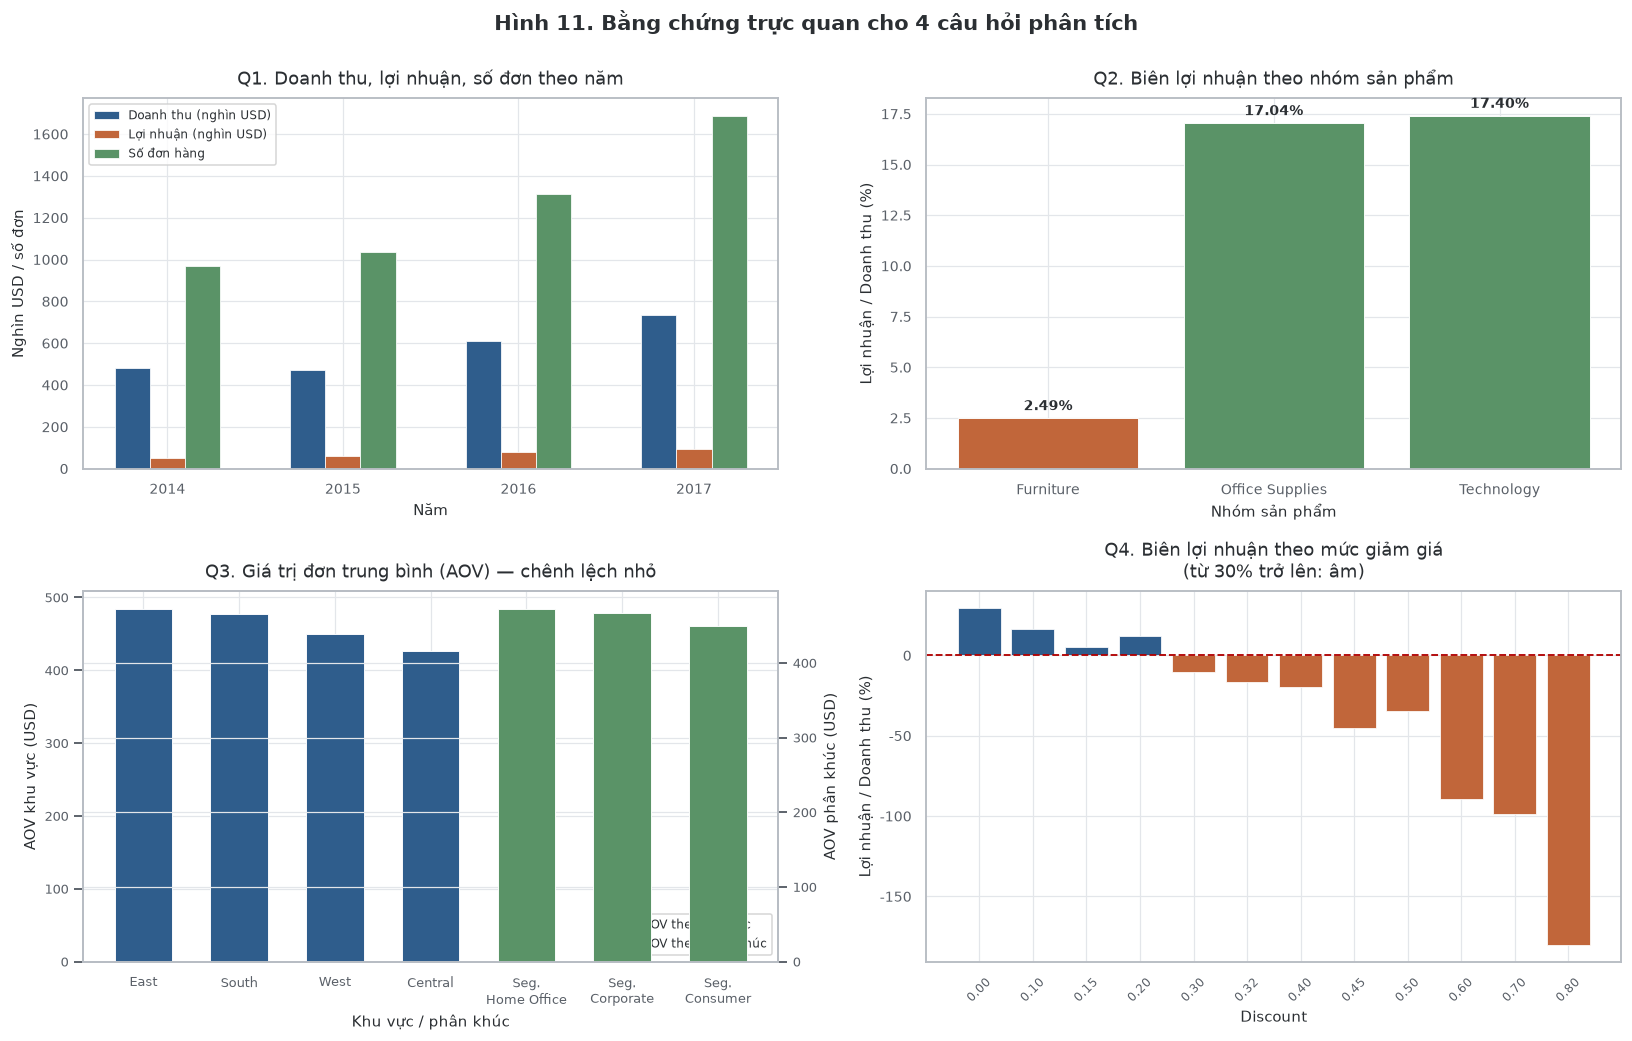

In [65]:
print("=== 9.2 Hình 11. Tổng hợp bằng chứng cho 4 câu hỏi ===")
print("Bốn panel, mỗi panel là bằng chứng trực quan cho một câu hỏi.")
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# Q1: yearly trend
ax = axes[0, 0]
x = np.arange(len(yearly))
ax.bar(x - 0.2, yearly["sales"] / 1000, 0.2, label="Doanh thu (nghìn USD)",
       color=PALETTE[0], edgecolor="white", linewidth=0.5)
ax.bar(x, yearly["profit"] / 1000, 0.2, label="Lợi nhuận (nghìn USD)",
       color=PALETTE[1], edgecolor="white", linewidth=0.5)
ax.bar(x + 0.2, yearly["orders"], 0.2, label="Số đơn hàng",
       color=PALETTE[2], edgecolor="white", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(yearly.index)
ax.set_title("Q1. Doanh thu, lợi nhuận, số đơn theo năm", fontsize=11.5, pad=9)
ax.set_xlabel("Năm", fontsize=9.5)
ax.set_ylabel("Nghìn USD / số đơn", fontsize=9.5)
ax.legend(fontsize=8, frameon=True, facecolor="white", edgecolor="#CCC")
ax.tick_params(labelsize=9)

# Q2: category margin
ax = axes[0, 1]
cm = cat_summary.sort_values("margin_pct")
bars = ax.bar(cm.index, cm["margin_pct"],
               color=[PALETTE[1] if v < 5 else PALETTE[2] for v in cm["margin_pct"]],
               edgecolor="white", linewidth=0.6)
for b, v in zip(bars, cm["margin_pct"]):
    ax.text(b.get_x() + b.get_width()/2, v + 0.4, f"{v:.2f}%",
            ha="center", fontsize=9, fontweight="bold")
ax.set_title("Q2. Biên lợi nhuận theo nhóm sản phẩm", fontsize=11.5, pad=9)
ax.set_xlabel("Nhóm sản phẩm", fontsize=9.5)
ax.set_ylabel("Lợi nhuận / Doanh thu (%)", fontsize=9.5)
ax.tick_params(labelsize=9)

# Q3: AOV comparison
ax = axes[1, 0]
ax2 = ax.twinx()
r3 = reg_summary.sort_values("AOV", ascending=False)
s3 = seg_summary.sort_values("AOV", ascending=False)
ax.bar(r3.index, r3["AOV"], color=PALETTE[0], edgecolor="white", linewidth=0.6,
       width=0.6, label="AOV theo khu vực")
ax2.bar([f"Seg.\n{i}" for i in s3.index], s3["AOV"], color=PALETTE[2],
        edgecolor="white", linewidth=0.6, width=0.6, label="AOV theo phân khúc")
ax.set_title("Q3. Giá trị đơn trung bình (AOV) — chênh lệch nhỏ", fontsize=11.5, pad=9)
ax.set_xlabel("Khu vực / phân khúc", fontsize=9.5)
ax.set_ylabel("AOV khu vực (USD)", fontsize=9.5)
ax2.set_ylabel("AOV phân khúc (USD)", fontsize=9.5)
ax.tick_params(labelsize=8.5)
ax2.tick_params(labelsize=8.5)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, frameon=True, facecolor="white",
          edgecolor="#CCC", loc="lower right")

# Q4: margin by discount
ax = axes[1, 1]
ax.bar([f"{d:.2f}" for d in disc_tbl.index], disc_tbl["margin_pct"],
       color=[PALETTE[1] if d >= 0.3 else PALETTE[0] for d in disc_tbl.index],
       edgecolor="white", linewidth=0.5)
ax.axhline(0, color="#B00000", linestyle="--", linewidth=1.2)
ax.set_title("Q4. Biên lợi nhuận theo mức giảm giá\n(từ 30% trở lên: âm)", fontsize=11.5, pad=9)
ax.set_xlabel("Discount", fontsize=9.5)
ax.set_ylabel("Lợi nhuận / Doanh thu (%)", fontsize=9.5)
ax.tick_params(axis="x", labelsize=8, rotation=45)
ax.tick_params(axis="y", labelsize=9)

fig.suptitle("Hình 11. Bằng chứng trực quan cho 4 câu hỏi phân tích",
             fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

### Câu hỏi 1 — Doanh thu, lợi nhuận và số đơn hàng thay đổi thế nào theo tháng và năm?

**Kết luận.** Cả ba đại lượng đều **tăng mạnh** trong giai đoạn 2014–2017, nhưng theo ba nhịp khác nhau, và bị chi phối bởi mùa vụ cuối năm.

**Số liệu chứng minh** (bảng mục 8.3):

| Năm | Doanh thu | Lợi nhuận | Số đơn | AOV | Biên LN | Doanh thu tăng |
|---|---:|---:|---:|---:|---:|---:|
| 2014 | 483.966 | 49.556 | 969 | 499,45 | 10,24% | — |
| 2015 | 470.533 | 61.619 | 1.038 | 453,31 | 13,10% | −2,78% |
| 2016 | 609.206 | 81.795 | 1.315 | 463,27 | 13,43% | +29,47% |
| 2017 | 733.215 | 93.439 | 1.687 | 434,63 | 12,74% | +20,36% |

* Cả giai đoạn 2014→2017: doanh thu **+51,5%**, lợi nhuận **+88,5%**, số đơn **+74,1%**.
* Tháng cao điểm doanh thu: **11/2017 = 118.447,82 USD**; thấp điểm: **02/2014 = 4.519,89 USD** (chênh 26 lần).
* Tháng nhiều đơn nhất: **11/2017 = 261 đơn**; ít nhất: **02/2014 = 28 đơn**.
* Tháng lợi nhuận cao nhất: **12/2016 = 17.885,31 USD**; thấp nhất: **01/2015 = −3.281,01 USD**.
* Tháng 11–12 chiếm **29,5%** doanh thu cả giai đoạn; Q4 chiếm 38,23%.

**Biểu đồ.** Hình 9 (xu hướng theo tháng), Hình 10 (so sánh năm + mùa vụ), Hình 11 panel trên-trái.

**Diễn giải kinh doanh.** Quy mô kinh doanh mở rộng đều đặn cả về doanh thu, lợi nhuận lẫn số lượng đơn. Đáng chú ý là **AOV giảm 13,0%** (499,45 → 434,63 USD) trong khi số đơn tăng 74% → tăng trưởng đến từ **nhiều đơn giá trị nhỏ hơn**, chứ không phải đơn lớn hơn. Biên lợi nhuận cải thiện từ 10,24% lên ~13% rồi giữ ổn định, cho thấy tăng trưởng không phải do bán rủi ro hơn. 2015 giảm doanh thu nhưng lợi nhuận tăng — cấu trúc đơn hàng tốt hơn.

**Giới hạn của nhận định.**
* Chỉ 4 năm dữ liệu → không đủ để xác định chu kỳ dài hạn hay kiểm định xu hướng thống kê chắc chắn.
* Mùa vụ chi phối mạnh (tỉ lệ max/min doanh thu trung bình/tháng là 5,9 lần) → **không nên so sánh tháng này với tháng khác một cách trực tiếp**, phải so cùng tháng giữa các năm.
* Hai tháng có lợi nhuận âm cho thấy biến động lớn ở cấp tháng → cần cẩn trọng khi ra quyết định theo tháng.
* Không có dữ liệu chi phí, khuyến mãi hay đầu tư → **không xác định được nguyên nhân** của tăng trưởng.

### Câu hỏi 2 — Nhóm sản phẩm nào hoạt động tốt nhất và kém nhất về doanh thu và lợi nhuận?

**Kết luận.** `Technology` tốt nhất về **cả** doanh thu và lợi nhuận. Nhóm **kém nhất là `Furniture`** — không phải vì doanh thu thấp nhất, mà vì **biên lợi nhuận chỉ 2,49%**, thấp hơn 7 lần so với hai nhóm còn lại dù doanh thu chỉ kém 11%.

**Số liệu chứng minh** (bảng mục 6.1):

| Nhóm | Doanh thu | Lợi nhuận | Số lượng | Số đơn | AOV | Biên LN | % dòng lỗ |
|---|---:|---:|---:|---:|---:|---:|---:|
| Technology | 836.154 | 145.455 | 6.939 | 1.544 | 541,55 | **17,40%** | 14,7% |
| Furniture | 741.718 | **18.463** | 8.026 | 1.764 | 420,48 | **2,49%** | 33,6% |
| Office Supplies | 719.047 | 122.491 | 22.906 | 3.742 | 192,16 | 17,04% | 14,7% |

* `Technology` chiếm **36,4%** doanh thu và **50,8%** lợi nhuận — tỷ lệ lợi nhuận cao hơn tỷ lệ doanh thu rất nhiều.
* `Furniture` có doanh thu chỉ kém `Technology` 11,3% nhưng lợi nhuận kém **87,3%**.
* `Furniture` là nhóm có **tỉ lệ dòng lỗ cao nhất: 33,6%** (713/2.120 dòng).
* Về số lượng bán, `Office Supplies` bán **22.906** đơn vị so với `Technology` 6.939 — nhưng đổi lại AOV thấp hơn gần 3 lần (192,16 vs 541,55 USD).

**Mức độ chi tiết sub-category** (phát hiện sâu hơn, bảng mục 6.2):
* **Kém nhất về lợi nhuận:** `Tables` (**−17.725,48 USD**, biên −8,56%, `Furniture`), `Bookcases` (−3.472,56, biên −3,02%, `Furniture`), `Supplies` (−1.189,10, biên −2,55%, `Office Supplies`) — **3 sub-category âm**: hai thuộc `Furniture`, một thuộc `Office Supplies`.
* **Tốt nhất về lợi nhuận:** `Copiers` (55.617,82), `Phones` (44.515,73), `Accessories` (41.936,64), `Paper` (34.053,57).
* `Copiers` chỉ 68 đơn nhưng tạo 55.618 USD lợi nhuận — AOV 2.198,94 USD/đơn, cao nhất toàn bộ nhóm sản phẩm.

**Biểu đồ.** Hình 3 (doanh thu, lợi nhuận, biên LN theo Category), Hình 11 panel trên-phải.

**Diễn giải kinh doanh.** Ba nhóm sản phẩm theo **ba mô hình kinh doanh khác nhau**: `Technology` = giá trị đơn cao, số lượng thấp; `Office Supplies` = số lượng lớn, giá trị đơn thấp nhưng lượng lớn nên vẫn lợi nhuận tốt; `Furniture` = doanh thu lớn nhưng **mất tiền ở các dòng giảm giá sâu**. Vấn đề của `Furniture` nằm ở `Tables` và `Bookcases` — nhóm sản phẩm có giá trị đơn cao nhưng thường xuyên bị giảm giá mạnh (chi tiết ở câu hỏi 4).

**Giới hạn của nhận định.**
* `Furniture` có **33,6%** dòng lỗ nhưng vẫn sinh lợi nhuận dương ở cấp nhóm → không được nói "Furniture lỗ". Đây là nhóm **hiệu quả thấp**, không phải nhóm lỗ.
* Không có cột chi phí vận chuyển hay chi phí bán hàng → không xác định được nguyên nhân gốc rễ khiến biên lợi nhuận thấp (chi phí vận chuyển hàng nặng là một giả thuyết hợp lý cho `Tables`/`Bookcases`, nhưng **không kiểm chứng được** từ dữ liệu này).
* Phân tích ở cấp nhóm bị hiệu ứng Simpson: cần kiểm tra ở cấp sub-category mới kết luận được — và kết luận ở cấp sub-category vẫn mang tính mô tả.

### Câu hỏi 3 — Khu vực và phân khúc khách hàng khác nhau thế nào về doanh thu, lợi nhuận và giá trị đơn trung bình?

**Kết luận.** Khu vực và phân khúc **khác nhau rõ về quy mô (doanh thu, số đơn) nhưng gần như không khác nhau về giá trị đơn trung bình**. Điểm đáng chú ý nhất là `Central` (biên LN 7,92%) và `Consumer` (biên LN 11,55% thấp nhất dù doanh thu cao nhất).

**Số liệu chứng minh — theo khu vực** (bảng mục 6.3):

| Khu vực | Doanh thu | Lợi nhuận | Số đơn | **AOV** | Biên LN | % dòng lỗ |
|---|---:|---:|---:|---:|---:|---:|
| West | 725.458 | 108.418 | 1.611 | 450,32 | 14,94% | 9,9% |
| East | 678.500 | 91.535 | 1.401 | **484,30** | 13,49% | 19,4% |
| Central | 501.240 | 39.706 | 1.175 | 426,59 | **7,92%** | **31,9%** |
| South | 391.722 | 46.749 | 822 | 476,55 | 11,93% | 16,0% |

**Số liệu chứng minh — theo phân khúc** (bảng mục 6.4):

| Phân khúc | Doanh thu | Lợi nhuận | Số đơn | **AOV** | Biên LN | % dòng lỗ |
|---|---:|---:|---:|---:|---:|---:|
| Consumer | 1.161.401 | 134.119 | 2.586 | 449,11 | 11,55% | 19,3% |
| Corporate | 706.146 | 91.979 | 1.514 | 466,41 | 13,03% | 18,4% |
| Home Office | 429.372 | 60.311 | 909 | **472,36** | **14,05%** | 17,5% |

**Ba so sánh đáng chú ý:**
1. **AOV gần như bằng nhau giữa các phân khúc**: 449,11 / 466,41 / 472,36 USD — chênh tối đa **5,2%**. Trong khi doanh thu chênh tới **2,7 lần** (Consumer vs Home Office) và số đơn chênh **2,8 lần**. → Phân khúc khác nhau về **số lượng khách hàng và tần suất mua**, gần như không khác về **giá trị mỗi lần mua**.
2. **AOV chênh nhỏ giữa các khu vực**: 426,59 – 484,30 USD (chênh 13,5%) so với doanh thu chênh 1,85 lần. → Quy mô vùng phụ thuộc nhiều vào **số khách hàng**, ít phụ thuộc vào giá trị đơn.
3. **`Central` là vùng cần chú ý**: doanh thu đứng thứ ba nhưng lợi nhuận thấp nhất (39.706) và biên LN thấp nhất (**7,92%**), với **31,9% dòng lỗ** — **gấp 3,2 lần** `West` (9,9%). Ở chiều ngược lại, `South` có doanh thu thấp nhất nhưng biên LN 11,93% lại **cao hơn `Central`**.

**Biểu đồ.** Hình 4 (lợi nhuận theo khu vực và phân khúc), Hình 5 (AOV), Hình 11 panel dưới-trái.

**Diễn giải kinh doanh.** Vùng `West`/`East` và phân khúc `Consumer` là nơi tập trung doanh thu, nhưng **hiệu quả lợi nhuận lại nằm ở chỗ khác**: `Home Office` có biên LN cao nhất (14,05%) và AOV cao nhất. `Central` vừa doanh thu vừa biên LN đều thấp → đây là khu vực cần rà soát về chính sách giảm giá và chi phí vận chuyển.

**Giới hạn của nhận định.**
* Chỉ **4 khu vực** → độ lực thống kê rất thấp, **không thể kiểm định ý nghĩa thống kê** hay suy ra xu hướng vùng từ n = 4.
* Có **531 thành phố / 49 bang** nhưng không có dữ liệu chi phí theo địa lý → không phân rã được vì sao `Central` kém.
* `Consumer` là phân khúc lớn nhất (50,6% doanh thu) → kết luận về phân khúc bị ảnh hưởng bởi trọng số mẫu.
* Thiếu dữ liệu khách hàng mới/quay lại → **không** kết luận được phân khúc nào "gia trì" tốt hơn.
* AOV ở đây là giá trị đơn **quan sát trong giai đoạn 2014–2017**, không phải giá trị vòng đời của khách hàng.

### Câu hỏi 4 — Mức giảm giá có mối liên hệ thế nào với doanh thu và lợi nhuận?

**Kết luận.** Giảm giá **không liên hệ đáng kể với doanh thu** ở cấp dòng (r = −0,028), nhưng **liên hệ với lợi nhuận theo kiểu phân tầng theo ngưỡng**: dưới 30% vẫn sinh lời, **từ 30% trở lên hơn 87% số dòng đều lỗ** (và 100% ở 6 mức 0,32/0,45/0,50/0,60/0,70/0,80). Doanh thu ở các mức giảm giá cao **không biến mất** — nó **chuyển thành doanh thu không sinh lời**.

**Số liệu chứng minh** (bảng mục 7.9):

| Discount | Số dòng | Doanh thu | Lợi nhuận | **Biên LN** | % dòng lỗ |
|---|---:|---:|---:|---:|---:|
| 0,00 | 4.798 | 1.087.908 | 320.988 | **+29,51%** | 0,0% |
| 0,10 | 94 | 54.369 | 9.029 | +16,61% | 4,3% |
| 0,15 | 52 | 27.559 | 1.419 | +5,15% | 32,7% |
| 0,20 | 3.657 | 764.594 | 90.337 | +11,82% | 13,7% |
| 0,30 | 226 | 102.945 | −10.357 | **−10,06%** | 91,6% |
| 0,32 | 27 | 14.493 | −2.391 | −16,50% | **100,0%** |
| 0,40 | 206 | 116.418 | −23.057 | −19,81% | 87,4% |
| 0,45 | 11 | 5.485 | −2.493 | −45,45% | **100,0%** |
| 0,50 | 66 | 58.919 | −20.506 | −34,80% | **100,0%** |
| 0,60 | 138 | 6.645 | −5.945 | −89,46% | **100,0%** |
| 0,70 | 418 | 40.620 | −40.075 | −98,66% | **100,0%** |
| 0,80 | 300 | 16.964 | −30.539 | **−180,03%** | **100,0%** |

* Hệ số tương quan `Discount`–`Profit` = **−0,219** (yếu, chiều âm). R² tương ứng chỉ ~4,8% → mức giảm giá giải thích rất ít biến động lợi nhuận.
* `Discount`–`Sales` = **−0,028** → không có mối liên hệ tuyến tính.
* Tại 6 mức 0,32 / 0,45 / 0,50 / 0,60 / 0,70 / 0,80: **100% số dòng đều lỗ**. Gộp tất cả dòng có `Discount ≥ 0,30`: 1.392 dòng, trong đó **1.347 lỗ (96,8%)**. Gộp `Discount ≥ 0,32`: 1.166 dòng, trong đó 1.140 lỗ (97,8%).
* Doanh thu ở mức 0,50 vẫn là 58.918,54 USD trên 66 dòng (TB 892,71 USD/dòng — cao hơn TB chung 229,85) → **dòng lỗ vẫn là dòng doanh thu lớn**.
* Khi loại bỏ các dòng lỗ, r(Discount, Profit) giảm từ −0,219 xuống **−0,071** → phần lớn tín hiệu đến từ chính nhóm dòng lỗ.
* Liên hệ với `Furniture`: các dòng lỗ nặng nhất của `Furniture` tập trung ở `Tables` và `Bookcases` (bảng mục 6.2) — cùng nhóm có biên LN thấp nhất. (Xét toàn bộ ngành hàng, `Binders` — `Office Supplies` — và `Machines` — `Technology` — là hai sub-category lỗ nặng nhất.)

**Biểu đồ.** Hình 7 (scatter Discount–Profit, có panel thu nhỏ vùng lỗ), Hình 8 (panel phải: boxplot Profit theo Discount), Hình 11 panel dưới-phải.

**Diễn giải kinh doanh.** Có vẻ như một **ngưỡng rủi ro kinh doanh** rõ ràng ở khoảng 30%: dưới ngưỡng, giảm giá vẫn tạo lợi nhuận dương; từ ngưỡng trở lên, mức giảm giá vượt quá biên lợi nhuận gốc của sản phẩm và giao dịch gần như luôn lỗ. Quan trọng: **không có bằng chứng giảm giá làm giảm doanh thu** — doanh thu ở mức giảm giá cao vẫn rất lớn. Vấn đề là **hiệu quả**, không phải **quy mô**.

**Giới hạn của nhận định — điểm cần nhấn mạnh.**
* **Không kết luận "giảm giá gây ra lỗ".** Dữ liệu chỉ cho phép nói **có mối liên hệ** giữa mức giảm giá và lợi nhuận. Ba lý do cụ thể:
  1. **Tương quan ngược (hướng ngược) rất dễ xảy ra**: sản phẩm bị giảm giá mạnh thường là sản phẩm **sắp hết hàng** hoặc **chủ động xả tồn kho**. Khi đó "giảm giá nhiều" và "lợi nhuận thấp" là **hai hệ quả của cùng một nguyên nhân** (tình trạng hàng hóa), chứ không phải giảm giá sinh ra lỗ.
  2. **Thiếu biến kiểm soát**: không có cột chi phí vốn, chi phí vận chuyển, tồn kho hay chi phí thanh lý → không tách được "doanh thu giảm vì giảm giá" khỏi "chi phí tăng". Giảm giá sâu thường đi kèm **giảm giá vốn** khi hàng tồn kho.
  3. **Không có thí nghiệm, không có nhóm đối chứng, không có phân phối ngẫu nhiên** → mọi giải thích nhân quả đều không kiểm chứng được.
* r = −0,219 là mối liên hệ **yếu**; phần lớn biến động lợi nhuận nằm ở nơi khác (giá trị sản phẩm, số lượng, chi phí).
* Mức giảm giá có thể **không ngẫu nhiên**: gần 48% dòng không giảm giá, và giảm giá chỉ tập trung ở một số nhóm sản phẩm → so sánh giữa các mức giảm giá **không cân bằng về đặc tính sản phẩm**.
* Các mức 0,32 / 0,45 / 0,60 chỉ có 11–138 dòng → mẫu nhỏ, kết luận cho từng mức riêng lẻ có độ tin cậy thấp. Kết luận đáng tin hơn là **xu hướng ngưỡng 30%**.
* Đây là phân tích **lịch sử**, không phải cơ sở để khẳng định khả năng dự báo lợi nhuận tương lai.

## 10. Assumptions and Limitations — D14

Nội dung đầy đủ được ghi vào [`docs/assumptions_limitations.md`](../docs/assumptions_limitations.md) (cập nhật cho phần EDA). Tóm tắt các điểm then chốt:

### 10.1 Giả định trong phân tích

| Mã | Giả định | Tác động |
|---|---|---|
| A1 | Một dòng = một mặt hàng trong một đơn hàng | Số đơn và AOV **phải** tính qua `nunique("Order ID")` và chia tổng `Sales` cho số đơn |
| A2 | `Order Date` là mốc thời gian nghiệp vụ chính | Mọi phân tích thời gian dùng `Order Date`, không dùng năm trong `Order ID` (7 dòng lệch) |
| A3 | Các giá trị ngoại lại trong `Sales`/`Profit` là giao dịch thật | Giữ nguyên 1.870 dòng lỗ; biểu đồ dùng thang log khi cần |
| A4 | Biên lợi nhuận nhóm = tổng `Profit` ÷ tổng `Sales` | Không trung bình các tỉ lệ từng dòng |
| A5 | `Ship Date` phản ánh thời điểm giao hàng thực tế | Dùng cho thời gian giao hàng; `Ship Date` tới 05/01/2018 là do đơn đặt cuối năm |

### 10.2 Giới hạn khi tính Order Value (điểm cần chú ý nhất)

* **AOV không phải giá trị vòng đời khách hàng (CLV).** Nó chỉ là giá trị của các đơn **quan sát được trong giai đoạn 2014–2017**. Doanh nghiệp không biết một khách hàng sẽ quay lại bao nhiêu lần.
* **AOV bị ảnh hưởng bởi cơ cấu nhóm sản phẩm.** Một vùng có AOV thấp có thể chỉ vì bán nhiều sản phẩm giá trị thấp, không phải vì khách hàng mua kém. Vì vậy không nên dùng AOV một mình để kết luận về "chất lượng khách hàng".
* **Số đơn là số đơn *chứa* nhóm sản phẩm đó**, không phải số đơn *chỉ gồm* nhóm đó. Một đơn hỗn hợp xuất hiện ở cả 3 nhóm Category → tổng số đơn của 3 nhóm (1.544 + 1.764 + 3.742 = 7.050) **lớn hơn** tổng số đơn thực tế (5.009). Đây là lý do AOV phải tính trên tập đơn của nhóm, không cộng lại được.
* **Không có trường "chi phí vận chuyển" hay "giá vốn"** → không tính được biên lợi nhuận gốc, không tách được ảnh hưởng của chi phí khỏi ảnh hưởng của giá.

### 10.3 Giới hạn của các biến

| Biến | Giới hạn |
|---|---|
| `Sales` | Lệch phải mạnh (skew 12,97); trung bình bị 5 dòng chi phối → dùng trung vị hoặc log khi so sánh |
| `Profit` | Trải rộng hai chiều, 18,71% âm; phần dư không đồng nhất → không dùng OLS thẳng cho kết luận nhân quả |
| `Discount` | 12 mức rời rạc, 48% bằng 0 → biến phân loại có thứ tự hơn là biến liên tục |
| `Quantity` | Chỉ 1–14, tập trung 2–5 → thông tin đa dạng thấp |
| `Customer ID`/`Name` | Đã ẩn danh thành `CUST-nnn` → dùng để gom nhóm, **không** dùng làm biến dự báo |
| `Order ID` | Tiền tố `CA-`/`US-` không nhất quán → không dùng để suy ra bang/năm |

### 10.4 Các trường hợp thiếu dữ liệu

* Không có cột **chi phí vận chuyển** → không phân tích được tác động của chi phí logistics.
* Không có cột **giá vốn / giá niêm yết** → không tách được "giảm giá" khỏi "chi phí tăng" trong `Profit` âm.
* Không có **khách hàng mới / quay lại** → không phân tích được thu hút và giữ chân khách hàng.
* Không có **mã khuyến mãi** → không biết giảm giá thuộc chiến lược nào.
* Không có **tồn kho, sản phẩm sắp hết hàng** → không kiểm tra được giả thuyết "giảm giá sâu vì hàng tồn".
* Không có **bảng đầu đơn** → không biết số nhóm sản phẩm khác nhau trong mỗi đơn.
* Không có **đánh giá hài lòng / tỉ lệ hoàn trả** → không đánh giá được tác động của tốc độ giao hàng.

### 10.5 Khả năng dữ liệu ngoại lại ảnh hưởng kết quả

* **r(Sales, Profit) = 0,479 giảm còn 0,313 khi bỏ dòng `Sales > 5.000`** và chỉ còn 0,204 với `log1p(Sales)` → phần lớn mối liên hệ đến từ vài dòng giá trị lớn. **Phải báo cáo cả hai cách.**
* **r(Discount, Profit) = −0,219 giảm còn −0,071 khi loại dòng lỗ** → tín hiệu chủ yếu đến từ nhóm dòng lỗ.
* 1.167 dòng (11,7%) vượt ngưỡng ngoại lại IQR của `Sales`; giá trị lớn nhất 22.638,48 USD (lỗ 1.811,08).
* Dòng lỗ nặng nhất −6.599,98 USD bằng **761 lần** giá trị trung vị lợi nhuận một dòng → chi phối mạnh mọi thống kê trung bình của nhóm lỗ.
* **Do đó:** mọi phát hiện về `Furniture`, `Central` và các mức giảm giá cao đều phải được kiểm tra lại bằng **trung vị** hoặc tỉ lệ, không chỉ tổng và trung bình.

### 10.6 Không suy luận nhân quả

Mọi phát hiện ở mục 9 là **mối liên hệ quan sát**. Cụm từ bắt buộc dùng: "có mối liên hệ", "đi kèm", "xuất hiện cùng". Cấm dùng: "gây ra", "làm nên", "dẫn tới" khi nói về Discount–Profit, Region–Profit hay Category–Profit. Lý do chi tiết nêu ở câu hỏi 4 và trong [`docs/assumptions_limitations.md`](../docs/assumptions_limitations.md).

### 10.7 Không dùng kết quả để khẳng định khả năng dự báo tương lai

Đây là **phân tích dữ liệu lịch sử**. Mọi biểu đồ và con số mô tả điều đã xảy ra trong 01/2014 – 12/2017. Không có kết luận nào về doanh thu, lợi nhuận hay số đơn của các năm sau 2017. Bất kỳ nhận định về tương lai nào đều phải được ghi rõ là **nhận định định tính dựa trên xu hướng quan sát được**, không phải kết quả dự báo.

## 11. Conclusion

### 11.1 Tóm tắt kết quả EDA

| Câu hỏi | Trả lời ngắn |
|---|---|
| **Q1** Xu hướng theo tháng/năm | Doanh thu **+51,5%**, lợi nhuận **+88,5%**, số đơn **+74,1%** (2014→2017). Nhưng AOV **giảm 13%** → tăng trưởng đến từ nhiều đơn giá trị nhỏ hơn. Mùa vụ cực mạnh: tháng 11–12 chiếm **29,5%** doanh thu, tỉ lệ max/min doanh thu trung bình/tháng **5,9 lần**. |
| **Q2** Nhóm sản phẩm | **Tốt nhất: `Technology`** (836.154 doanh thu, 145.455 lợi nhuận, biên LN 17,40%). **Kém nhất: `Furniture`** — doanh thu chỉ kém 11% nhưng lợi nhuận kém 87%, biên LN chỉ **2,49%**, 33,6% dòng lỗ. Kém nhất ở cấp sub-category: `Tables` (−17.725), `Bookcases` (−3.473), `Supplies` (−1.189). |
| **Q3** Khu vực & phân khúc | Khác nhau rõ về **quy mô**, gần như không khác về **AOV** (vùng: 426–484 USD; phân khúc: 449–472 USD, chênh ≤13,5%). `West`/`East` dẫn doanh thu; `Central` biên LN thấp nhất (**7,92%**, 31,9% dòng lỗ); `Home Office` biên LN cao nhất (**14,05%**). |
| **Q4** Mức giảm giá | Không liên hệ với doanh thu (r = **−0,028**). Liên hệ **phân tầng theo ngưỡng** với lợi nhuận: biên LN +29,51% ở mức 0% → âm từ **30%**; tại 6 mức 0,32/0,45/0,50/0,60/0,70/0,80 **100% dòng lỗ**, và mọi mức ≥ 0,30 lỗ trên 87% dòng. r chỉ −0,219 (R² ~4,8%). Doanh thu ở mức giảm giá cao **không mất**, mà chuyển thành doanh thu không sinh lời. |

### 11.2 Điểm nhấn dành cho quản lý kinh doanh

Ba điểm có thể hành động được, đều dựa trên mối liên hệ **quan sát** (không phải kết luận nhân quả):

1. **Rà soát chính sách giảm giá ở `Furniture`**, đặc biệt `Tables` và `Bookcases` — nhóm có doanh thu lớn nhưng lợi nhuận âm. Biên LN 2,49% là rất thấp so với 17% của hai nhóm còn lại.
2. **Xem xét lại chính sách giảm giá ở vùng `Central`** — biên LN 7,92% thấp nhất và 31,9% dòng lỗ, trong khi `West` chỉ 9,9%.
3. **Tận dụng điểm mạnh của `Technology` và `Copiers`** — nhóm lợi nhuận cao nhất với số đơn rất ít (68 đơn cho `Copiers` tạo 55.618 USD lợi nhuận).

### 11.3 Điểm cần thận trọng

* Mọi phát hiện là **mối liên hệ quan sát** trên dữ liệu lịch sử — **không** phải quan hệ nhân quả.
* Kết quả **không** phải dự báo cho giai đoạn sau 2017.
* Các con số trung bình bị chi phối bởi ngoại lại → khi trích dẫn nên kèm trung vị hoặc tỉ lệ.

### 11.4 Bàn giao

| Sản phẩm | Vị trí | Người nhận |
|---|---|---|
| File dữ liệu sạch | `data_cleaned/superstore_clean.csv` | Hiếu (hồi quy), Hoàng (dashboard) |
| Notebook EDA | `notebooks/01_data_cleaning_eda.ipynb` | Cả nhóm |
| Data dictionary + Cleaning Decision Log | [`docs/data_dictionary.md`](../docs/data_dictionary.md) | Cả nhóm |
| Giả định & giới hạn | [`docs/assumptions_limitations.md`](../docs/assumptions_limitations.md) | Cả nhóm |
| Quyền riêng tư | [`docs/privacy_note.md`](../docs/privacy_note.md) | Cả nhóm |

**Lưu ý cho phần hồi quy tuyến tính (Hiếu):**
1. Biến nên đưa vào mô hình: `Category`, `Sub-Category`, `Region`, `Segment`, `Ship Mode`, `Discount`, `Quantity`, và các biến thời gian tách từ `Order Date` (`Year`, `Month`, `Quarter`).
2. **Không** đưa vào `X`: `Row ID`, `Order ID`, `Customer ID`, `Customer Name` (định danh), `Profit` (tính từ chính `Sales`), `Order Date`/`Ship Date` dạng thô.
3. Cân nhắc `log1p` cho `Sales` do phân phối lệch mạnh (skew 12,97).
4. Giữ các dòng cùng `Order ID` trong cùng một tập khi chia train/test.
5. Nhớ mốc so sánh `DummyRegressor` và báo cáo MAE/RMSE bên cạnh R².